In [3]:
!pip install -q lightkurve seaborn

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
datasets 4.8.5 requires fsspec[http]<=2026.2.0,>=2023.1.0, but you have fsspec 2026.9.0 which is incompatible.
gcsfs 2025.12.0 requires fsspec==2025.12.0, but you have fsspec 2026.9.0 which is incompatible.


In [4]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import lightkurve as lk

from astropy.timeseries import BoxLeastSquares
from pathlib import Path

print("Lightkurve:", lk.__version__)
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Environment initialized successfully.")


Lightkurve: 2.6.0
NumPy: 2.4.6
Pandas: 2.2.3
Environment initialized successfully.


/usr/local/lib/python3.13/dist-packages/lightkurve/prf/__init__.py:7: UserWarning: Warning: the tpfmodel submodule is not available without oktopus installed, which requires a current version of autograd. See #1452 for details.
  warnings.warn(


In [5]:

search_result = lk.search_lightcurve(
    "Kepler-10",
    mission="Kepler",
    author="Kepler",
    exptime=1800
)

print(search_result)
print("Available observations:", len(search_result))


SearchResult containing 15 data products.

 #       mission      year author exptime  target_name  distance
                                     s                   arcsec 
--- ----------------- ---- ------ ------- ------------- --------
  0 Kepler Quarter 00 2009 Kepler    1800 kplr011904151      0.0
  1 Kepler Quarter 01 2009 Kepler    1800 kplr011904151      0.0
  2 Kepler Quarter 02 2009 Kepler    1800 kplr011904151      0.0
  3 Kepler Quarter 03 2009 Kepler    1800 kplr011904151      0.0
  4 Kepler Quarter 04 2010 Kepler    1800 kplr011904151      0.0
  5 Kepler Quarter 05 2010 Kepler    1800 kplr011904151      0.0
  6 Kepler Quarter 06 2010 Kepler    1800 kplr011904151      0.0
  7 Kepler Quarter 07 2010 Kepler    1800 kplr011904151      0.0
  8 Kepler Quarter 09 2011 Kepler    1800 kplr011904151      0.0
  9 Kepler Quarter 10 2011 Kepler    1800 kplr011904151      0.0
 10 Kepler Quarter 11 2012 Kepler    1800 kplr011904151      0.0
 11 Kepler Quarter 13 2012 Kepler    1800 kplr0

In [6]:

# Display all available Kepler-10 data products
products = search_result.table

print("Available columns:")
print(products.colnames)

print("\nData product details:")
display(products.to_pandas())


Available columns:
['intentType', 'obs_collection', 'provenance_name', 'instrument_name', 'project', 'filters', 'wave_region', 'target_name', 'target_classification', 'obs_id', 's_ra', 's_dec', 'dataproduct_type', 'proposal_pi', 'calib_level', 't_min', 't_max', 't_exptime', 'wavelength_region', 'em_min', 'em_max', 'obs_title', 't_obs_release', 'proposal_id', 'proposal_type', 'sequence_number', 's_region', 'jpegURL', 'dataURL', 'dataRights', 'mtFlag', 'srcDen', 'obsid', 'objID', 'wave_min', 'wave_max', 'objID1', 'distance', 'exptime', 'obsID', 'obs_collection_products', 'dataproduct_type_products', 'description', 'type', 'dataURI', 'productType', 'productGroupDescription', 'productSubGroupDescription', 'productDocumentationURL', 'project_products', 'prvversion', 'proposal_id_products', 'productFilename', 'size', 'parent_obsid', 'dataRights_products', 'calib_level_products', 'filters_products', 'author', 'mission', '#', 'year', 'sort_order']

Data product details:


,intentType,obs_collection,provenance_name,instrument_name,project,filters,wave_region,target_name,target_classification,obs_id,...,size,parent_obsid,dataRights_products,calib_level_products,filters_products,author,mission,#,year,sort_order
0,science,Kepler,Kepler,Kepler,Kepler,KEPLER,OPTICAL,kplr011904151,NaN,kplr011904151_lc_Q111111110111011101,...,77760,582316,PUBLIC,2,KEPLER,Kepler,Kepler Quarter 00,0,2009,1
1,science,Kepler,Kepler,Kepler,Kepler,KEPLER,OPTICAL,kplr011904151,NaN,kplr011904151_lc_Q111111110111011101,...,192960,582316,PUBLIC,2,KEPLER,Kepler,Kepler Quarter 01,1,2009,1
2,science,Kepler,Kepler,Kepler,Kepler,KEPLER,OPTICAL,kplr011904151,NaN,kplr011904151_lc_Q111111110111011101,...,466560,582316,PUBLIC,2,KEPLER,Kepler,Kepler Quarter 02,2,2009,1
3,science,Kepler,Kepler,Kepler,Kepler,KEPLER,OPTICAL,kplr011904151,NaN,kplr011904151_lc_Q111111110111011101,...,466560,582316,PUBLIC,2,KEPLER,Kepler,Kepler Quarter 03,3,2009,1
4,science,Kepler,Kepler,Kepler,Kepler,KEPLER,OPTICAL,kplr011904151,NaN,kplr011904151_lc_Q111111110111011101,...,132480,582316,PUBLIC,2,KEPLER,Kepler,Kepler Quarter 04,4,2010,1
5,science,Kepler,Kepler,Kepler,Kepler,KEPLER,OPTICAL,kplr011904151,NaN,kplr011904151_lc_Q111111110111011101,...,492480,582316,PUBLIC,2,KEPLER,Kepler,Kepler Quarter 05,5,2010,1
6,science,Kepler,Kepler,Kepler,Kepler,KEPLER,OPTICAL,kplr011904151,NaN,kplr011904151_lc_Q111111110111011101,...,469440,582316,PUBLIC,2,KEPLER,Kepler,Kepler Quarter 06,6,2010,1
7,science,Kepler,Kepler,Kepler,Kepler,KEPLER,OPTICAL,kplr011904151,NaN,kplr011904151_lc_Q111111110111011101,...,466560,582316,PUBLIC,2,KEPLER,Kepler,Kepler Quarter 07,7,2010,1
8,science,Kepler,Kepler,Kepler,Kepler,KEPLER,OPTICAL,kplr011904151,NaN,kplr011904151_lc_Q111111110111011101,...,506880,582316,PUBLIC,2,KEPLER,Kepler,Kepler Quarter 09,8,2011,1
9,science,Kepler,Kepler,Kepler,Kepler,KEPLER,OPTICAL,kplr011904151,NaN,kplr011904151_lc_Q111111110111011101,...,486720,582316,PUBLIC,2,KEPLER,Kepler,Kepler Quarter 10,9,2011,1


In [7]:

# Inspect the important acquisition metadata
for column in ["target_name", "mission", "author", "quarter", "exptime"]:
    if column in products.colnames:
        print(f"\n{column}:")
        print(products[column])



target_name:
 target_name 
-------------
kplr011904151
kplr011904151
kplr011904151
kplr011904151
kplr011904151
kplr011904151
kplr011904151
kplr011904151
kplr011904151
kplr011904151
kplr011904151
kplr011904151
kplr011904151
kplr011904151
kplr011904151

mission:
     mission     
-----------------
Kepler Quarter 00
Kepler Quarter 01
Kepler Quarter 02
Kepler Quarter 03
Kepler Quarter 04
Kepler Quarter 05
Kepler Quarter 06
Kepler Quarter 07
Kepler Quarter 09
Kepler Quarter 10
Kepler Quarter 11
Kepler Quarter 13
Kepler Quarter 14
Kepler Quarter 15
Kepler Quarter 17

author:
author
------
Kepler
Kepler
Kepler
Kepler
Kepler
Kepler
Kepler
Kepler
Kepler
Kepler
Kepler
Kepler
Kepler
Kepler
Kepler

exptime:
exptime
   s   
-------
   1800
   1800
   1800
   1800
   1800
   1800
   1800
   1800
   1800
   1800
   1800
   1800
   1800
   1800
   1800


## 2. Verify duplicates properly

In [8]:

# Inspect product identifiers
columns_to_check = [
    col for col in [
        "target_name",
        "targetid",
        "quarter",
        "productFilename",
        "dataURI",
        "author"
    ]
    if col in products.colnames
]

product_df = products.to_pandas()[columns_to_check]

display(product_df)

print("\nDuplicate rows:", product_df.duplicated().sum())

if "productFilename" in product_df.columns:
    print(
        "Duplicate filenames:",
        product_df["productFilename"].duplicated().sum()
    )

if "quarter" in product_df.columns:
    print(
        "Duplicate quarters:",
        product_df["quarter"].duplicated().sum()
    )


,target_name,productFilename,dataURI,author
0,kplr011904151,kplr011904151-2009131105131_llc.fits,mast:KEPLER/url/missions/kepler/lightcurves/01...,Kepler
1,kplr011904151,kplr011904151-2009166043257_llc.fits,mast:KEPLER/url/missions/kepler/lightcurves/01...,Kepler
2,kplr011904151,kplr011904151-2009259160929_llc.fits,mast:KEPLER/url/missions/kepler/lightcurves/01...,Kepler
3,kplr011904151,kplr011904151-2009350155506_llc.fits,mast:KEPLER/url/missions/kepler/lightcurves/01...,Kepler
4,kplr011904151,kplr011904151-2010009091648_llc.fits,mast:KEPLER/url/missions/kepler/lightcurves/01...,Kepler
5,kplr011904151,kplr011904151-2010174085026_llc.fits,mast:KEPLER/url/missions/kepler/lightcurves/01...,Kepler
6,kplr011904151,kplr011904151-2010265121752_llc.fits,mast:KEPLER/url/missions/kepler/lightcurves/01...,Kepler
7,kplr011904151,kplr011904151-2010355172524_llc.fits,mast:KEPLER/url/missions/kepler/lightcurves/01...,Kepler
8,kplr011904151,kplr011904151-2011177032512_llc.fits,mast:KEPLER/url/missions/kepler/lightcurves/01...,Kepler
9,kplr011904151,kplr011904151-2011271113734_llc.fits,mast:KEPLER/url/missions/kepler/lightcurves/01...,Kepler



Duplicate rows: 0
Duplicate filenames: 0


In [9]:
target_search = lk.search_lightcurve(
    "Kepler",
    mission="Kepler",
    author="Kepler",
    exptime=1800
)

print("Total products found:", len(target_search))
print(target_search[:10])

Could not resolve "Kepler" to a sky position.
ERROR:lightkurve.search:Could not resolve "Kepler" to a sky position.


Total products found: 0
SearchResult containing 0 data products.


In [10]:
target_search = lk.search_lightcurve(
    "Kepler-10",
    mission="Kepler",
    author="Kepler",
    exptime=1800
)

print("Total products found:", len(target_search))
print(target_search[:5])

Total products found: 15
SearchResult containing 5 data products.

 #       mission      year author exptime  target_name  distance
                                     s                   arcsec 
--- ----------------- ---- ------ ------- ------------- --------
  0 Kepler Quarter 00 2009 Kepler    1800 kplr011904151      0.0
  1 Kepler Quarter 01 2009 Kepler    1800 kplr011904151      0.0
  2 Kepler Quarter 02 2009 Kepler    1800 kplr011904151      0.0
  3 Kepler Quarter 03 2009 Kepler    1800 kplr011904151      0.0
  4 Kepler Quarter 04 2010 Kepler    1800 kplr011904151      0.0


In [11]:
!pip install -q astroquery

In [15]:
target_search = lk.search_lightcurve(
    "Kepler-10",
    radius=1800,       # 0.5 degrees in arcseconds
    mission="Kepler",
    author="Kepler",
    exptime=1800,
    quarter=4
)

print("Total light-curve products:", len(target_search))

search_df = target_search.table.to_pandas()

print(
    "Unique target IDs:",
    search_df["target_name"].nunique()
)

display(
    search_df[
        ["target_name", "mission", "year", "author", "exptime", "distance"]
    ].head(20)
)

Total light-curve products: 588
Unique target IDs: 588


,target_name,mission,year,author,exptime,distance
0,kplr011904151,Kepler Quarter 04,2010,Kepler,1800.0,0.000000
1,kplr011904148,Kepler Quarter 04,2010,Kepler,1800.0,55.735312
2,kplr011904099,Kepler Quarter 04,2010,Kepler,1800.0,69.050846
3,kplr011904085,Kepler Quarter 04,2010,Kepler,1800.0,82.656078
4,kplr011904071,Kepler Quarter 04,2010,Kepler,1800.0,101.255480
5,kplr011904090,Kepler Quarter 04,2010,Kepler,1800.0,112.586345
6,kplr011904101,Kepler Quarter 04,2010,Kepler,1800.0,136.204418
7,kplr011904249,Kepler Quarter 04,2010,Kepler,1800.0,151.016142
8,kplr011904271,Kepler Quarter 04,2010,Kepler,1800.0,162.915072
9,kplr011904260,Kepler Quarter 04,2010,Kepler,1800.0,181.381828


In [16]:
pilot_search = target_search[:10]

pilot_lcs = pilot_search.download_all(
    flux_column="pdcsap_flux"
)

print("Downloaded light curves:", len(pilot_lcs))

for i, lc in enumerate(pilot_lcs):
    valid = (
        np.isfinite(lc.time.value)
        & np.isfinite(lc.flux.value)
    )

    print(
        f"Target {i + 1}:",
        lc.meta.get("TARGETID", "Unknown"),
        "| Total points:", len(lc.time),
        "| Valid points:", valid.sum()
    )

Downloaded light curves: 10
Target 1: 11904151 | Total points: 1011 | Valid points:  ———
Target 2: 11904148 | Total points: 1011 | Valid points:  ———
Target 3: 11904099 | Total points: 1011 | Valid points:  ———
Target 4: 11904085 | Total points: 1011 | Valid points:  ———
Target 5: 11904071 | Total points: 1011 | Valid points:  ———
Target 6: 11904090 | Total points: 1011 | Valid points:  ———
Target 7: 11904101 | Total points: 1011 | Valid points:  ———
Target 8: 11904249 | Total points: 1011 | Valid points:  ———
Target 9: 11904271 | Total points: 1011 | Valid points:  ———
Target 10: 11904260 | Total points: 1011 | Valid points:  ———


In [17]:
lc = pilot_lcs[0]

print("Target ID:", lc.meta.get("TARGETID"))
print("Total observations:", len(lc))

print("\nTime information:")
print("Time type:", type(lc.time.value))
print("Time sample:", lc.time.value[:5])

print("\nFlux information:")
print("Flux type:", type(lc.flux.value))
print("Flux sample:", lc.flux.value[:10])
print("Flux unit:", lc.flux.unit)

print("\nMasked values:")
print("Time masked:", np.ma.is_masked(lc.time.value))
print("Flux masked:", np.ma.is_masked(lc.flux.value))


Target ID: 11904151
Total observations: 1011

Time information:
Time type: <class 'numpy.ndarray'>
Time sample: [352.37710511 352.39753829 352.43840464 352.45883781 352.47927099]

Flux information:
Flux type: <class 'astropy.utils.masked.core.MaskedNDArray'>
Flux sample: [      ——— 575100.6  575187.25 575179.7  575197.06 575177.06 575159.5
 575157.44 575175.56 575160.6 ]
Flux unit: electron / s

Masked values:
Time masked: False
Flux masked: True


In [18]:
# Step 3.4 — Correctly count valid observations
for i, lc in enumerate(pilot_lcs):

    time = np.asarray(lc.time.value, dtype=float)
    flux = np.asarray(lc.flux.value.filled(np.nan), dtype=float)

    valid = (
        np.isfinite(time)
        & np.isfinite(flux)
    )

    print(
        f"Target {i + 1} | "
        f"ID: {lc.meta.get('TARGETID')} | "
        f"Total: {len(time)} | "
        f"Valid: {valid.sum()} | "
        f"Invalid: {(~valid).sum()}"
    )

Target 1 | ID: 11904151 | Total: 1011 | Valid: 1008 | Invalid: 3
Target 2 | ID: 11904148 | Total: 1011 | Valid: 1008 | Invalid: 3
Target 3 | ID: 11904099 | Total: 1011 | Valid: 1008 | Invalid: 3
Target 4 | ID: 11904085 | Total: 1011 | Valid: 1008 | Invalid: 3
Target 5 | ID: 11904071 | Total: 1011 | Valid: 1008 | Invalid: 3
Target 6 | ID: 11904090 | Total: 1011 | Valid: 1008 | Invalid: 3
Target 7 | ID: 11904101 | Total: 1011 | Valid: 1008 | Invalid: 3
Target 8 | ID: 11904249 | Total: 1011 | Valid: 1008 | Invalid: 3
Target 9 | ID: 11904271 | Total: 1011 | Valid: 1008 | Invalid: 3
Target 10 | ID: 11904260 | Total: 1011 | Valid: 1008 | Invalid: 3


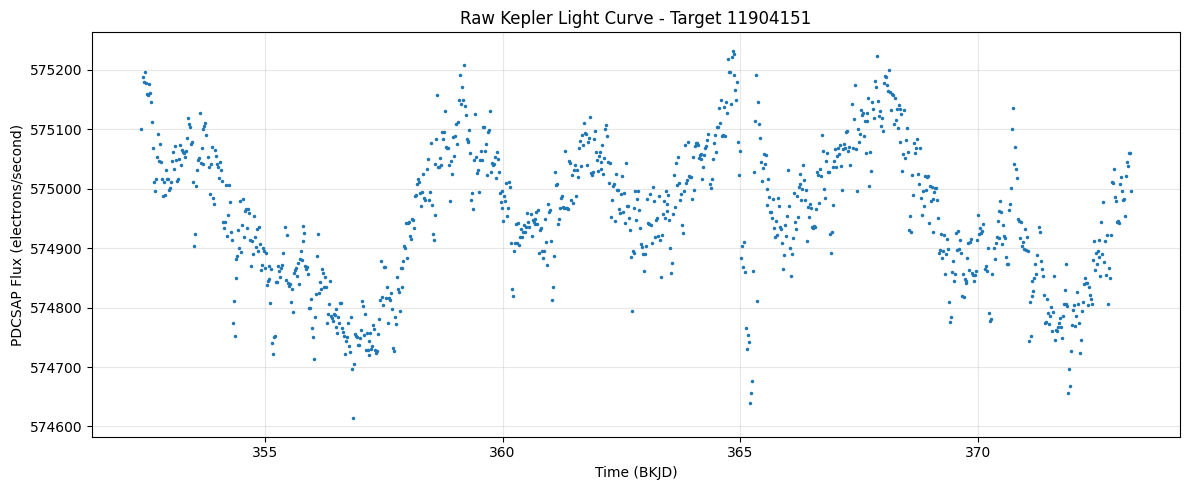

In [19]:
# bStep 3.5 — Visual inspection of the first light curve
lc = pilot_lcs[0]

time = np.asarray(lc.time.value, dtype=float)
flux = np.asarray(
    lc.flux.value.filled(np.nan),
    dtype=float
)

valid = np.isfinite(time) & np.isfinite(flux)

plt.figure(figsize=(12, 5))

plt.plot(
    time[valid],
    flux[valid],
    ".",
    markersize=3
)

plt.xlabel("Time (BKJD)")
plt.ylabel("PDCSAP Flux (electrons/second)")
plt.title(f"Raw Kepler Light Curve - Target {lc.meta.get('TARGETID')}")

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [20]:
# Step 3.6 — Inspect Kepler quality flags
lc = pilot_lcs[0]

quality = np.asarray(lc.quality.value)

unique_flags, flag_counts = np.unique(
    quality,
    return_counts=True
)

quality_table = pd.DataFrame({
    "Quality_Flag": unique_flags,
    "Count": flag_counts
})

print("Quality bitmask:", lc.meta.get("BITMASK"))
print("Total observations:", len(quality))

print("\nQuality flag distribution:")
display(quality_table)

print(
    "\nObservations with quality flag 0:",
    np.sum(quality == 0)
)

print(
    "Observations with non-zero quality flags:",
    np.sum(quality != 0)
)

Quality bitmask: None
Total observations: 1011

Quality flag distribution:


,Quality_Flag,Count
0,0,926
1,16,16
2,64,1
3,128,19
4,144,8
5,2192,1
6,4160,1
7,8192,38
8,8320,1



Observations with quality flag 0: 926
Observations with non-zero quality flags: 85


In [21]:
# Step 3.7 — Apply Lightkurve's default quality filtering
# Download the same 10 targets using default quality filtering
pilot_lcs_clean = pilot_search.download_all(
    flux_column="pdcsap_flux",
    quality_bitmask="default"
)

print("Downloaded light curves:", len(pilot_lcs_clean))

for i, lc in enumerate(pilot_lcs_clean):

    time = np.asarray(lc.time.value, dtype=float)
    flux = np.asarray(
        lc.flux.value.filled(np.nan),
        dtype=float
    )

    valid = np.isfinite(time) & np.isfinite(flux)

    print(
        f"Target {i + 1} | "
        f"ID: {lc.meta.get('TARGETID')} | "
        f"Total: {len(time)} | "
        f"Valid: {valid.sum()} | "
        f"Invalid: {(~valid).sum()}"
    )

Downloaded light curves: 10
Target 1 | ID: 11904151 | Total: 1011 | Valid: 1008 | Invalid: 3
Target 2 | ID: 11904148 | Total: 1011 | Valid: 1008 | Invalid: 3
Target 3 | ID: 11904099 | Total: 1011 | Valid: 1008 | Invalid: 3
Target 4 | ID: 11904085 | Total: 1011 | Valid: 1008 | Invalid: 3
Target 5 | ID: 11904071 | Total: 1011 | Valid: 1008 | Invalid: 3
Target 6 | ID: 11904090 | Total: 1011 | Valid: 1008 | Invalid: 3
Target 7 | ID: 11904101 | Total: 1011 | Valid: 1008 | Invalid: 3
Target 8 | ID: 11904249 | Total: 1011 | Valid: 1008 | Invalid: 3
Target 9 | ID: 11904271 | Total: 1011 | Valid: 1008 | Invalid: 3
Target 10 | ID: 11904260 | Total: 1011 | Valid: 1008 | Invalid: 3


In [22]:
# Step 3.7 — Compare default filtering with no quality filtering
# Original download: already uses the default quality bitmask
lc_default = pilot_lcs[0]

# Download the same target without quality filtering
lc_unfiltered = pilot_search[0].download(
    flux_column="pdcsap_flux",
    quality_bitmask="none"
)

# Extract flux arrays
flux_default = lc_default.flux.value
flux_unfiltered = lc_unfiltered.flux.value

# Count masked flux values
masked_default = np.ma.getmaskarray(flux_default).sum()
masked_unfiltered = np.ma.getmaskarray(flux_unfiltered).sum()

print("DEFAULT QUALITY FILTER")
print("Total observations:", len(lc_default))
print("Masked flux values:", masked_default)

print("\nNO QUALITY FILTER")
print("Total observations:", len(lc_unfiltered))
print("Masked flux values:", masked_unfiltered)

print("\nQUALITY FLAG COUNTS")
quality = np.asarray(lc_unfiltered.quality.value)

print("Zero flags:", np.sum(quality == 0))
print("Non-zero flags:", np.sum(quality != 0))

DEFAULT QUALITY FILTER
Total observations: 1011
Masked flux values: 3

NO QUALITY FILTER
Total observations: 1021
Masked flux values: 13

QUALITY FLAG COUNTS
Zero flags: 926
Non-zero flags: 95


In [26]:
# Recreate removed cadence table

time_default = np.asarray(lc_default.time.value)
time_unfiltered = np.asarray(lc_unfiltered.time.value)

quality_unfiltered = np.asarray(
    lc_unfiltered.quality.value
)

default_times = set(np.round(time_default, 8))

removed_indices = [
    i for i, t in enumerate(time_unfiltered)
    if np.round(t, 8) not in default_times
]

removed_table = pd.DataFrame({
    "Time_BKJD": time_unfiltered[removed_indices],
    "Quality_Flag": quality_unfiltered[removed_indices]
})

# Convert to native integer type
removed_table["Quality_Flag"] = (
    removed_table["Quality_Flag"]
    .to_numpy()
    .astype(np.int64)
)

print("Removed cadences:", len(removed_table))

display(removed_table)

print("\nQuality flag distribution:")
print(
    removed_table["Quality_Flag"]
    .value_counts()
    .sort_index()
)

Removed cadences: 10


,Time_BKJD,Quality_Flag
0,352.417972,32816
1,352.990100,16384
2,355.401217,32800
3,358.384466,32800
4,360.570823,16384
5,361.367720,32800
6,364.350978,32800
7,367.334241,32816
8,370.317508,32800
9,371.277876,16384



Quality flag distribution:
Quality_Flag
16384    3
32800    5
32816    2
Name: count, dtype: int64


Target ID: 11904151
Valid observations: 1008
Original median flux: 574964.8125
Normalized median flux: 1.0
Normalized minimum: 0.9993892017522377
Normalized maximum: 1.0004650284577197


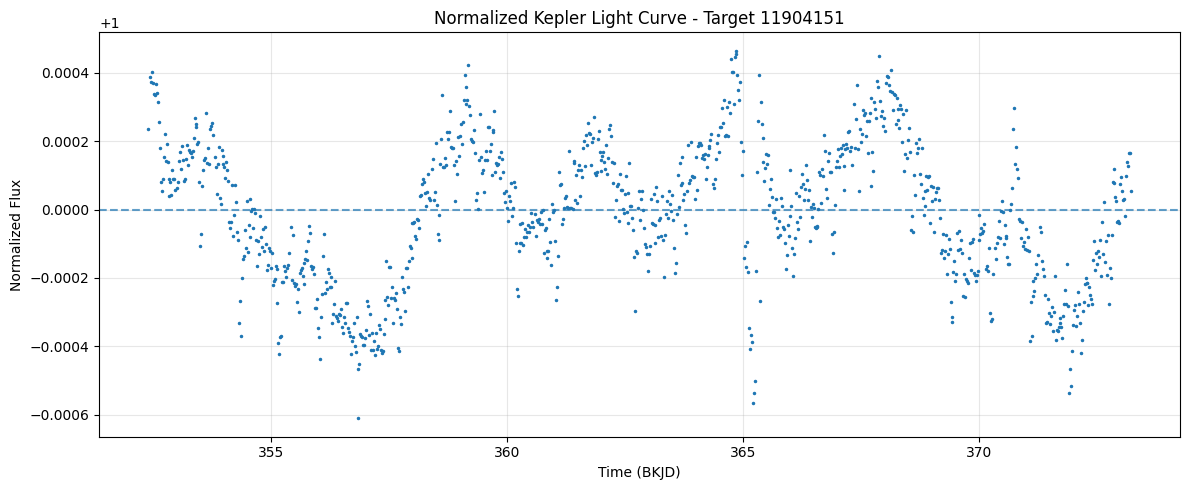

In [27]:
# Step 3.9 — Normalize the flux
# Select first quality-filtered light curve
lc = pilot_lcs[0]

# Extract time and flux
time = np.asarray(lc.time.value, dtype=float)

flux = np.asarray(
    lc.flux.value.filled(np.nan),
    dtype=float
)

# Remove invalid measurements
valid = np.isfinite(time) & np.isfinite(flux)

time_clean = time[valid]
flux_clean = flux[valid]

# Normalize flux
baseline = np.nanmedian(flux_clean)

normalized_flux = flux_clean / baseline

print("Target ID:", lc.meta.get("TARGETID"))
print("Valid observations:", len(normalized_flux))
print("Original median flux:", baseline)
print("Normalized median flux:", np.median(normalized_flux))
print("Normalized minimum:", np.min(normalized_flux))
print("Normalized maximum:", np.max(normalized_flux))

# Plot normalized light curve
plt.figure(figsize=(12, 5))

plt.plot(
    time_clean,
    normalized_flux,
    ".",
    markersize=3
)

plt.axhline(1.0, linestyle="--", alpha=0.7)

plt.xlabel("Time (BKJD)")
plt.ylabel("Normalized Flux")
plt.title("Normalized Kepler Light Curve - Target 11904151")

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

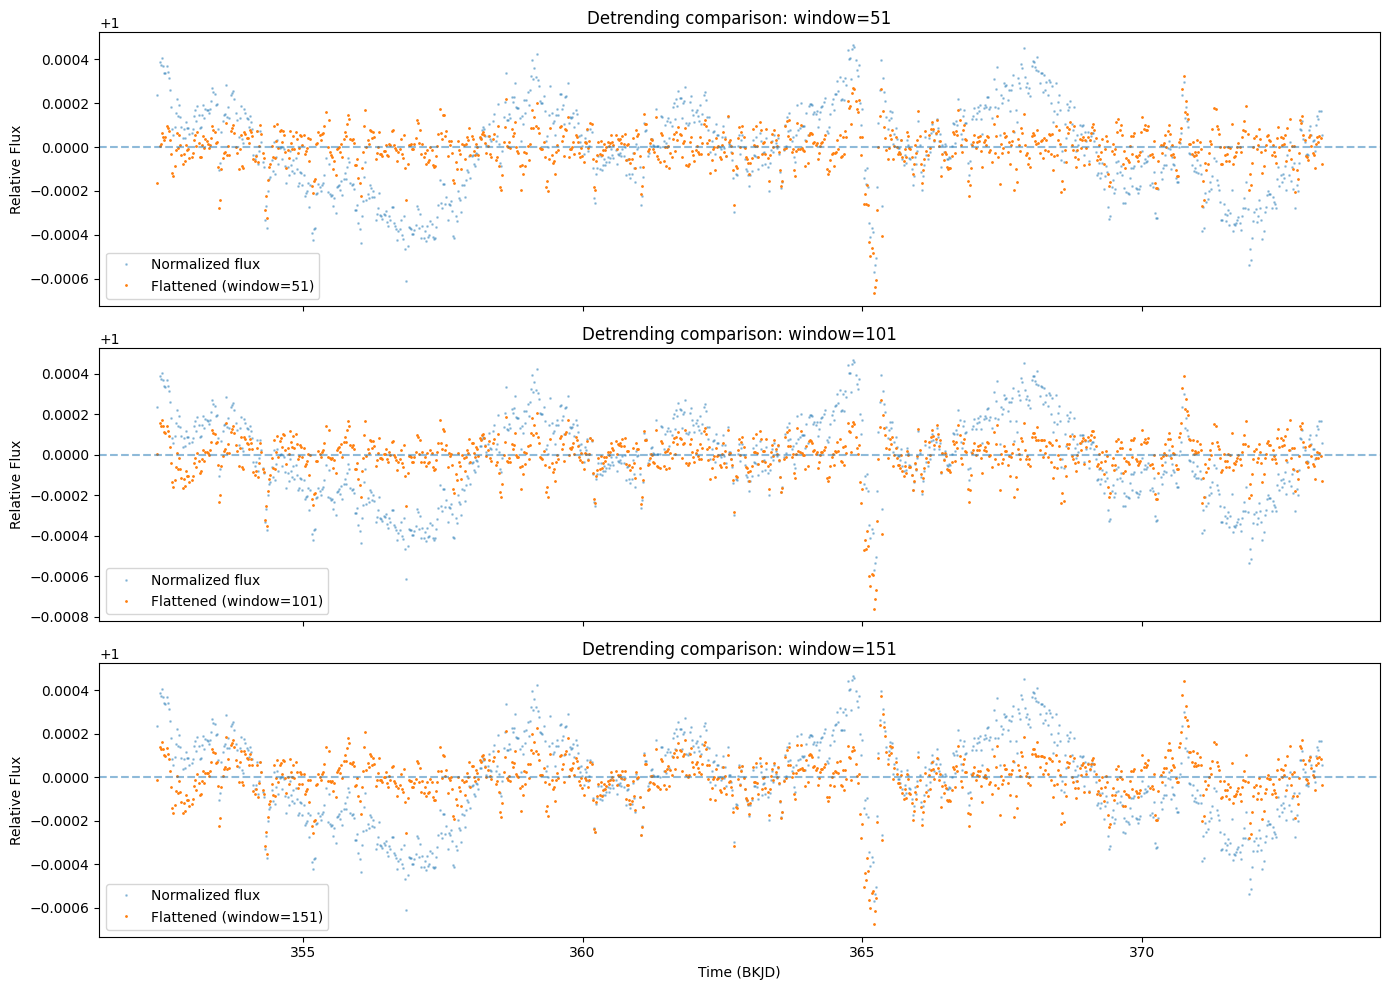

In [28]:
# Create a normalized LightCurve
lc_normalized = lk.LightCurve(
    time=time_clean,
    flux=normalized_flux
)

# Compare three detrending window lengths
window_lengths = [51, 101, 151]

fig, axes = plt.subplots(
    len(window_lengths), 1,
    figsize=(14, 10),
    sharex=True
)

for ax, window in zip(axes, window_lengths):

    flattened = lc_normalized.flatten(
        window_length=window,
        polyorder=2
    )

    ax.plot(
        time_clean,
        normalized_flux,
        ".",
        markersize=2,
        alpha=0.35,
        label="Normalized flux"
    )

    ax.plot(
        flattened.time.value,
        flattened.flux.value,
        ".",
        markersize=2,
        label=f"Flattened (window={window})"
    )

    ax.axhline(1.0, linestyle="--", alpha=0.5)
    ax.set_ylabel("Relative Flux")
    ax.set_title(f"Detrending comparison: window={window}")
    ax.legend()

axes[-1].set_xlabel("Time (BKJD)")

plt.tight_layout()
plt.show()

In [29]:
# Run this cell to compare the scatter remaining after detrending:
window_lengths = [51, 101, 151]

detrending_results = []

for window in window_lengths:

    flattened = lc_normalized.flatten(
        window_length=window,
        polyorder=2
    )

    flat_flux = np.asarray(flattened.flux.value, dtype=float)
    flat_flux = flat_flux[np.isfinite(flat_flux)]

    # Robust scatter estimate using MAD
    median_flux = np.median(flat_flux)
    mad = np.median(np.abs(flat_flux - median_flux))
    robust_scatter = 1.4826 * mad

    detrending_results.append({
        "Window": window,
        "Window_hours": window * 29.4 / 60,
        "Median": median_flux,
        "Standard_Deviation": np.std(flat_flux),
        "Robust_Scatter_MAD": robust_scatter
    })

detrending_table = pd.DataFrame(detrending_results)

display(detrending_table)

,Window,Window_hours,Median,Standard_Deviation,Robust_Scatter_MAD
0,51,24.99,1.000004,0.000094,0.000071
1,101,49.49,1.000003,0.000106,0.000078
2,151,73.99,1.000001,0.000109,0.000083


Injection time (BKJD): 362.8286986750609
Transit depth: 0.001
Transit duration (hours): 3.0
Number of injected observations: 6


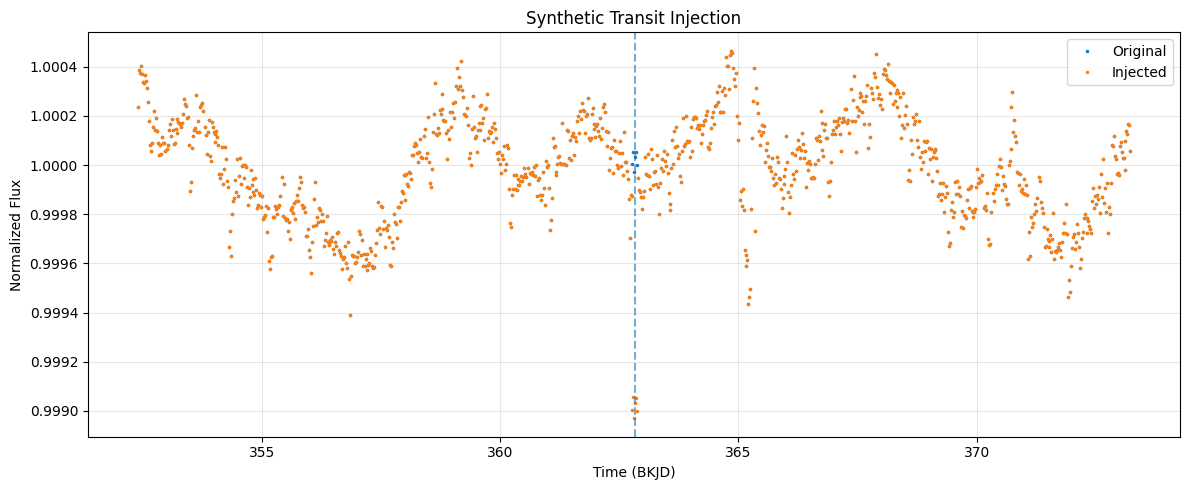

In [30]:
# Step 3.11 — Create a synthetic transit injection
# Synthetic transit parameters
transit_depth = 0.001
transit_duration_hours = 3.0

# Choose an injection time away from the edges
injection_time = np.median(time_clean)

# Convert duration into days
transit_duration_days = transit_duration_hours / 24

# Create synthetic transit mask
transit_mask = (
    np.abs(time_clean - injection_time)
    <= transit_duration_days / 2
)

# Copy original normalized flux
injected_flux = normalized_flux.copy()

# Inject transit
injected_flux[transit_mask] *= (1 - transit_depth)

print("Injection time (BKJD):", injection_time)
print("Transit depth:", transit_depth)
print("Transit duration (hours):", transit_duration_hours)
print("Number of injected observations:", transit_mask.sum())

# Plot original and injected light curves
plt.figure(figsize=(12, 5))

plt.plot(
    time_clean,
    normalized_flux,
    ".",
    markersize=3,
    label="Original"
)

plt.plot(
    time_clean,
    injected_flux,
    ".",
    markersize=3,
    label="Injected"
)

plt.axvline(injection_time, linestyle="--", alpha=0.6)

plt.xlabel("Time (BKJD)")
plt.ylabel("Normalized Flux")
plt.title("Synthetic Transit Injection")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [31]:
window_lengths = [51, 101, 151]

recovery_results = []

for window in window_lengths:

    # Create normalized light curves
    original_lc = lk.LightCurve(
        time=time_clean,
        flux=normalized_flux
    )

    injected_lc = lk.LightCurve(
        time=time_clean,
        flux=injected_flux
    )

    # Detrend both light curves
    original_flat = original_lc.flatten(
        window_length=window,
        polyorder=2
    )

    injected_flat = injected_lc.flatten(
        window_length=window,
        polyorder=2
    )

    original_flat_flux = np.asarray(
        original_flat.flux.value,
        dtype=float
    )

    injected_flat_flux = np.asarray(
        injected_flat.flux.value,
        dtype=float
    )

    # Match the injection mask to the flattened data
    flat_time = np.asarray(original_flat.time.value)

    flat_mask = (
        np.abs(flat_time - injection_time)
        <= transit_duration_days / 2
    )

    outside_mask = ~flat_mask

    # Measure depths
    original_depth = (
        np.median(original_flat_flux[outside_mask])
        - np.median(original_flat_flux[flat_mask])
    )

    injected_depth = (
        np.median(injected_flat_flux[outside_mask])
        - np.median(injected_flat_flux[flat_mask])
    )

    # Depth added by the injection after detrending
    recovered_depth = injected_depth - original_depth

    recovery_percent = (
        recovered_depth / transit_depth
    ) * 100

    recovery_results.append({
        "Window": window,
        "Original_Depth": original_depth,
        "Injected_Depth": injected_depth,
        "Recovered_Injected_Depth": recovered_depth,
        "Recovery_Percent": recovery_percent
    })

recovery_table = pd.DataFrame(recovery_results)

display(recovery_table)

,Window,Original_Depth,Injected_Depth,Recovered_Injected_Depth,Recovery_Percent
0,51,-0.000053,0.000877,0.000930,92.978894
1,101,-0.000048,0.000891,0.000938,93.843483
2,151,-0.000012,0.001069,0.001081,108.101188


In [32]:
# 4. Next experiment — repeat injection tests
# Multiple injection locations
injection_times = np.linspace(
    time_clean.min() + 1,
    time_clean.max() - 1,
    8
)

window_lengths = [51, 101, 151]

multi_injection_results = []

for injection_time_test in injection_times:

    transit_mask_test = (
        np.abs(time_clean - injection_time_test)
        <= transit_duration_days / 2
    )

    # Require at least 3 observations inside the transit
    if transit_mask_test.sum() < 3:
        continue

    injected_flux_test = normalized_flux.copy()

    injected_flux_test[transit_mask_test] *= (
        1 - transit_depth
    )

    for window in window_lengths:

        original_lc = lk.LightCurve(
            time=time_clean,
            flux=normalized_flux
        )

        injected_lc = lk.LightCurve(
            time=time_clean,
            flux=injected_flux_test
        )

        original_flat = original_lc.flatten(
            window_length=window,
            polyorder=2
        )

        injected_flat = injected_lc.flatten(
            window_length=window,
            polyorder=2
        )

        flat_time = np.asarray(original_flat.time.value)

        original_values = np.asarray(
            original_flat.flux.value,
            dtype=float
        )

        injected_values = np.asarray(
            injected_flat.flux.value,
            dtype=float
        )

        mask = (
            np.abs(flat_time - injection_time_test)
            <= transit_duration_days / 2
        )

        outside = ~mask

        original_depth_test = (
            np.median(original_values[outside])
            - np.median(original_values[mask])
        )

        injected_depth_test = (
            np.median(injected_values[outside])
            - np.median(injected_values[mask])
        )

        recovered_depth_test = (
            injected_depth_test - original_depth_test
        )

        recovery = (
            recovered_depth_test / transit_depth
        ) * 100

        multi_injection_results.append({
            "Injection_Time": injection_time_test,
            "Window": window,
            "In_Transit_Points": transit_mask_test.sum(),
            "Recovery_Percent": recovery
        })

multi_injection_table = pd.DataFrame(
    multi_injection_results
)

display(multi_injection_table)

,Injection_Time,Window,In_Transit_Points,Recovery_Percent
0,353.397538,51,6,95.488921
1,353.397538,101,6,103.356490
2,353.397538,151,6,103.126742
3,356.086325,51,6,103.048867
4,356.086325,101,6,103.808958
5,356.086325,151,6,98.524399
6,358.775112,51,6,98.418208
7,358.775112,101,6,104.955813
8,358.775112,151,6,110.972576
9,361.463899,51,6,100.012536


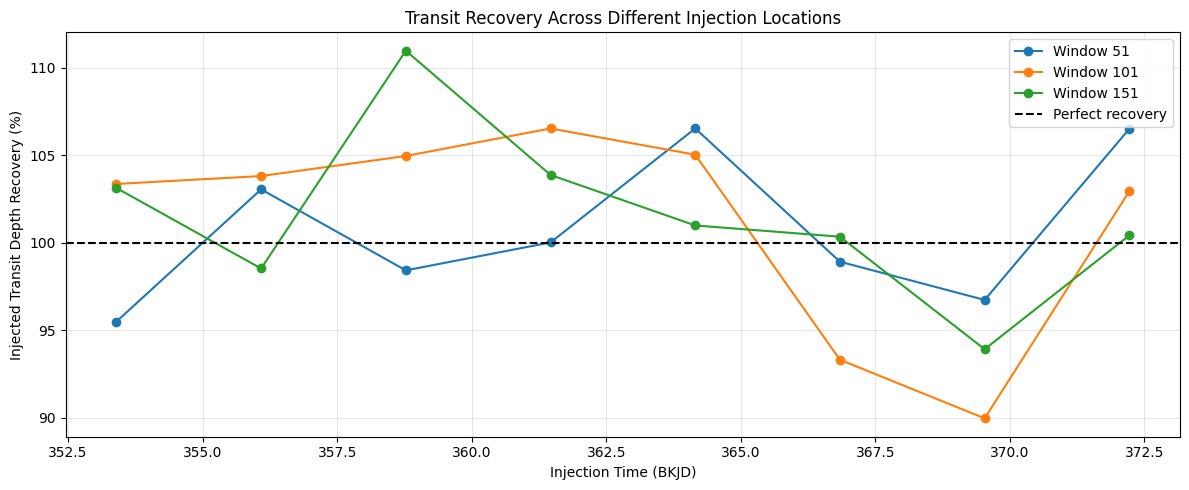

In [33]:
# 3. Next step — visualize recovery by injection location
plt.figure(figsize=(12, 5))

for window in [51, 101, 151]:

    subset = multi_injection_table[
        multi_injection_table["Window"] == window
    ]

    plt.plot(
        subset["Injection_Time"],
        subset["Recovery_Percent"],
        marker="o",
        label=f"Window {window}"
    )

plt.axhline(
    100,
    linestyle="--",
    color="black",
    label="Perfect recovery"
)

plt.xlabel("Injection Time (BKJD)")
plt.ylabel("Injected Transit Depth Recovery (%)")
plt.title("Transit Recovery Across Different Injection Locations")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [34]:
# Test different transit durations
transit_durations = [1.0, 3.0, 5.0]
window_lengths = [51, 101, 151]

# Use a fixed injection location with adequate data coverage
test_injection_time = 362.8286986750609

duration_results = []

for duration_hours in transit_durations:

    duration_days = duration_hours / 24

    transit_mask_test = (
        np.abs(time_clean - test_injection_time)
        <= duration_days / 2
    )

    if transit_mask_test.sum() < 3:
        print(
            f"Skipping {duration_hours} hours: "
            "fewer than 3 in-transit observations"
        )
        continue

    injected_flux_test = normalized_flux.copy()

    injected_flux_test[transit_mask_test] *= (
        1 - transit_depth
    )

    for window in window_lengths:

        original_lc = lk.LightCurve(
            time=time_clean,
            flux=normalized_flux
        )

        injected_lc = lk.LightCurve(
            time=time_clean,
            flux=injected_flux_test
        )

        original_flat = original_lc.flatten(
            window_length=window,
            polyorder=2
        )

        injected_flat = injected_lc.flatten(
            window_length=window,
            polyorder=2
        )

        flat_time = np.asarray(original_flat.time.value)

        original_values = np.asarray(
            original_flat.flux.value,
            dtype=float
        )

        injected_values = np.asarray(
            injected_flat.flux.value,
            dtype=float
        )

        mask = (
            np.abs(flat_time - test_injection_time)
            <= duration_days / 2
        )

        outside = ~mask

        original_depth_test = (
            np.median(original_values[outside])
            - np.median(original_values[mask])
        )

        injected_depth_test = (
            np.median(injected_values[outside])
            - np.median(injected_values[mask])
        )

        recovered_depth = (
            injected_depth_test - original_depth_test
        )

        recovery_percent = (
            recovered_depth / transit_depth
        ) * 100

        duration_results.append({
            "Duration_Hours": duration_hours,
            "Window": window,
            "In_Transit_Points": mask.sum(),
            "Recovery_Percent": recovery_percent
        })

duration_table = pd.DataFrame(duration_results)

display(duration_table)

Skipping 1.0 hours: fewer than 3 in-transit observations


,Duration_Hours,Window,In_Transit_Points,Recovery_Percent
0,3.0,51,6,92.978894
1,3.0,101,6,93.843483
2,3.0,151,6,108.101188
3,5.0,51,10,95.239200
4,5.0,101,10,106.084879
5,5.0,151,10,110.565529


In [35]:
transit_durations = [1.0, 3.0, 5.0]
window_lengths = [51, 101, 151]

injection_times = np.linspace(
    time_clean.min() + 1,
    time_clean.max() - 1,
    8
)

combined_results = []

for duration_hours in transit_durations:

    duration_days = duration_hours / 24

    for injection_time_test in injection_times:

        transit_mask_test = (
            np.abs(time_clean - injection_time_test)
            <= duration_days / 2
        )

        n_in_transit = transit_mask_test.sum()

        if n_in_transit < 3:
            for window in window_lengths:
                combined_results.append({
                    "Duration_Hours": duration_hours,
                    "Injection_Time": injection_time_test,
                    "Window": window,
                    "In_Transit_Points": n_in_transit,
                    "Recovery_Percent": np.nan,
                    "Status": "Under-sampled"
                })
            continue

        injected_flux_test = normalized_flux.copy()

        injected_flux_test[transit_mask_test] *= (
            1 - transit_depth
        )

        for window in window_lengths:

            original_lc = lk.LightCurve(
                time=time_clean,
                flux=normalized_flux
            )

            injected_lc = lk.LightCurve(
                time=time_clean,
                flux=injected_flux_test
            )

            original_flat = original_lc.flatten(
                window_length=window,
                polyorder=2
            )

            injected_flat = injected_lc.flatten(
                window_length=window,
                polyorder=2
            )

            flat_time = np.asarray(
                original_flat.time.value
            )

            original_values = np.asarray(
                original_flat.flux.value,
                dtype=float
            )

            injected_values = np.asarray(
                injected_flat.flux.value,
                dtype=float
            )

            mask = (
                np.abs(flat_time - injection_time_test)
                <= duration_days / 2
            )

            outside = ~mask

            original_depth_test = (
                np.median(original_values[outside])
                - np.median(original_values[mask])
            )

            injected_depth_test = (
                np.median(injected_values[outside])
                - np.median(injected_values[mask])
            )

            recovered_depth = (
                injected_depth_test - original_depth_test
            )

            recovery = (
                recovered_depth / transit_depth
            ) * 100

            combined_results.append({
                "Duration_Hours": duration_hours,
                "Injection_Time": injection_time_test,
                "Window": window,
                "In_Transit_Points": n_in_transit,
                "Recovery_Percent": recovery,
                "Status": "Measured"
            })

combined_table = pd.DataFrame(combined_results)

display(combined_table)

,Duration_Hours,Injection_Time,Window,In_Transit_Points,Recovery_Percent,Status
0,1.0,353.397538,51,2,NaN,Under-sampled
1,1.0,353.397538,101,2,NaN,Under-sampled
2,1.0,353.397538,151,2,NaN,Under-sampled
3,1.0,356.086325,51,2,NaN,Under-sampled
4,1.0,356.086325,101,2,NaN,Under-sampled
...,...,...,...,...,...,...
67,5.0,369.530259,101,10,91.406982,Measured
68,5.0,369.530259,151,10,96.521764,Measured
69,5.0,372.219046,51,11,108.070654,Measured
70,5.0,372.219046,101,11,103.431167,Measured


In [36]:
# Step 3.12 — Calculate recovery statistics
# Summarize recovery by transit duration and detrending window

summary_table = (
    combined_table[
        combined_table["Status"] == "Measured"
    ]
    .groupby(["Duration_Hours", "Window"])
    .agg(
        Number_of_Tests=("Recovery_Percent", "count"),
        Mean_Recovery=("Recovery_Percent", "mean"),
        Median_Recovery=("Recovery_Percent", "median"),
        Std_Recovery=("Recovery_Percent", "std"),
        Minimum_Recovery=("Recovery_Percent", "min"),
        Maximum_Recovery=("Recovery_Percent", "max")
    )
    .reset_index()
)

display(summary_table.round(3))

# Count under-sampled tests
print("\nUnder-sampled tests:")
print(
    combined_table[
        combined_table["Status"] == "Under-sampled"
    ].groupby("Duration_Hours").size()
)

,Duration_Hours,Window,Number_of_Tests,Mean_Recovery,Median_Recovery,Std_Recovery,Minimum_Recovery,Maximum_Recovery
0,3.0,51,8,100.706,99.463,4.227,95.489,106.530
1,3.0,101,8,101.235,103.583,6.098,89.960,106.529
2,3.0,151,8,101.519,100.703,4.888,93.909,110.973
3,5.0,51,8,102.561,102.594,3.438,98.578,108.071
4,5.0,101,8,102.026,104.045,5.571,91.407,107.452
5,5.0,151,8,101.905,100.981,4.160,96.522,109.217



Under-sampled tests:
Duration_Hours
1.0    24
dtype: int64


In [37]:
# Pilot preprocessing configuration
selected_window = 51
polyorder = 2

processed_lcs = []
processing_summary = []

for i, lc in enumerate(pilot_lcs_clean):

    # Extract time and flux
    time = np.asarray(lc.time.value, dtype=float)

    flux = np.asarray(
        lc.flux.value.filled(np.nan),
        dtype=float
    )

    # Remove invalid observations
    valid = np.isfinite(time) & np.isfinite(flux)

    time_valid = time[valid]
    flux_valid = flux[valid]

    # Normalize flux
    baseline = np.median(flux_valid)
    normalized = flux_valid / baseline

    # Construct normalized light curve
    normalized_lc = lk.LightCurve(
        time=time_valid,
        flux=normalized
    )

    # Detrend
    flattened_lc = normalized_lc.flatten(
        window_length=selected_window,
        polyorder=polyorder
    )

    processed_lcs.append(flattened_lc)

    processing_summary.append({
        "Target_Index": i,
        "Target_ID": lc.meta.get("TARGETID"),
        "Original_Valid_Points": len(time_valid),
        "Processed_Points": len(flattened_lc),
        "Original_Median_Flux": baseline,
        "Normalized_Median": np.median(normalized),
        "Detrended_Median": np.median(
            flattened_lc.flux.value
        ),
        "Detrended_Scatter": np.std(
            flattened_lc.flux.value
        )
    })

processing_table = pd.DataFrame(processing_summary)

display(processing_table.round(7))

print("Successfully processed targets:", len(processed_lcs))

,Target_Index,Target_ID,Original_Valid_Points,Processed_Points,Original_Median_Flux,Normalized_Median,Detrended_Median,Detrended_Scatter
0,0,11904151,1008,1008,574964.812500,1.0,1.000004,0.000095
1,1,11904148,1008,1008,10050.968262,1.0,1.000012,0.000505
2,2,11904099,1008,1008,31549.781250,1.0,1.000002,0.000267
3,3,11904085,1008,1008,145375.210938,1.0,0.999997,0.000106
4,4,11904071,1008,1008,40387.220703,1.0,0.999997,0.000200
5,5,11904090,1008,1008,24361.939453,1.0,0.999999,0.000269
6,6,11904101,1008,1008,13982.525391,1.0,1.000009,0.000480
7,7,11904249,1008,1008,26542.414062,1.0,0.999995,0.000307
8,8,11904271,1008,1008,23802.831055,1.0,0.999995,0.000395
9,9,11904260,1008,1008,13698.781250,1.0,0.999974,0.000546


Successfully processed targets: 10


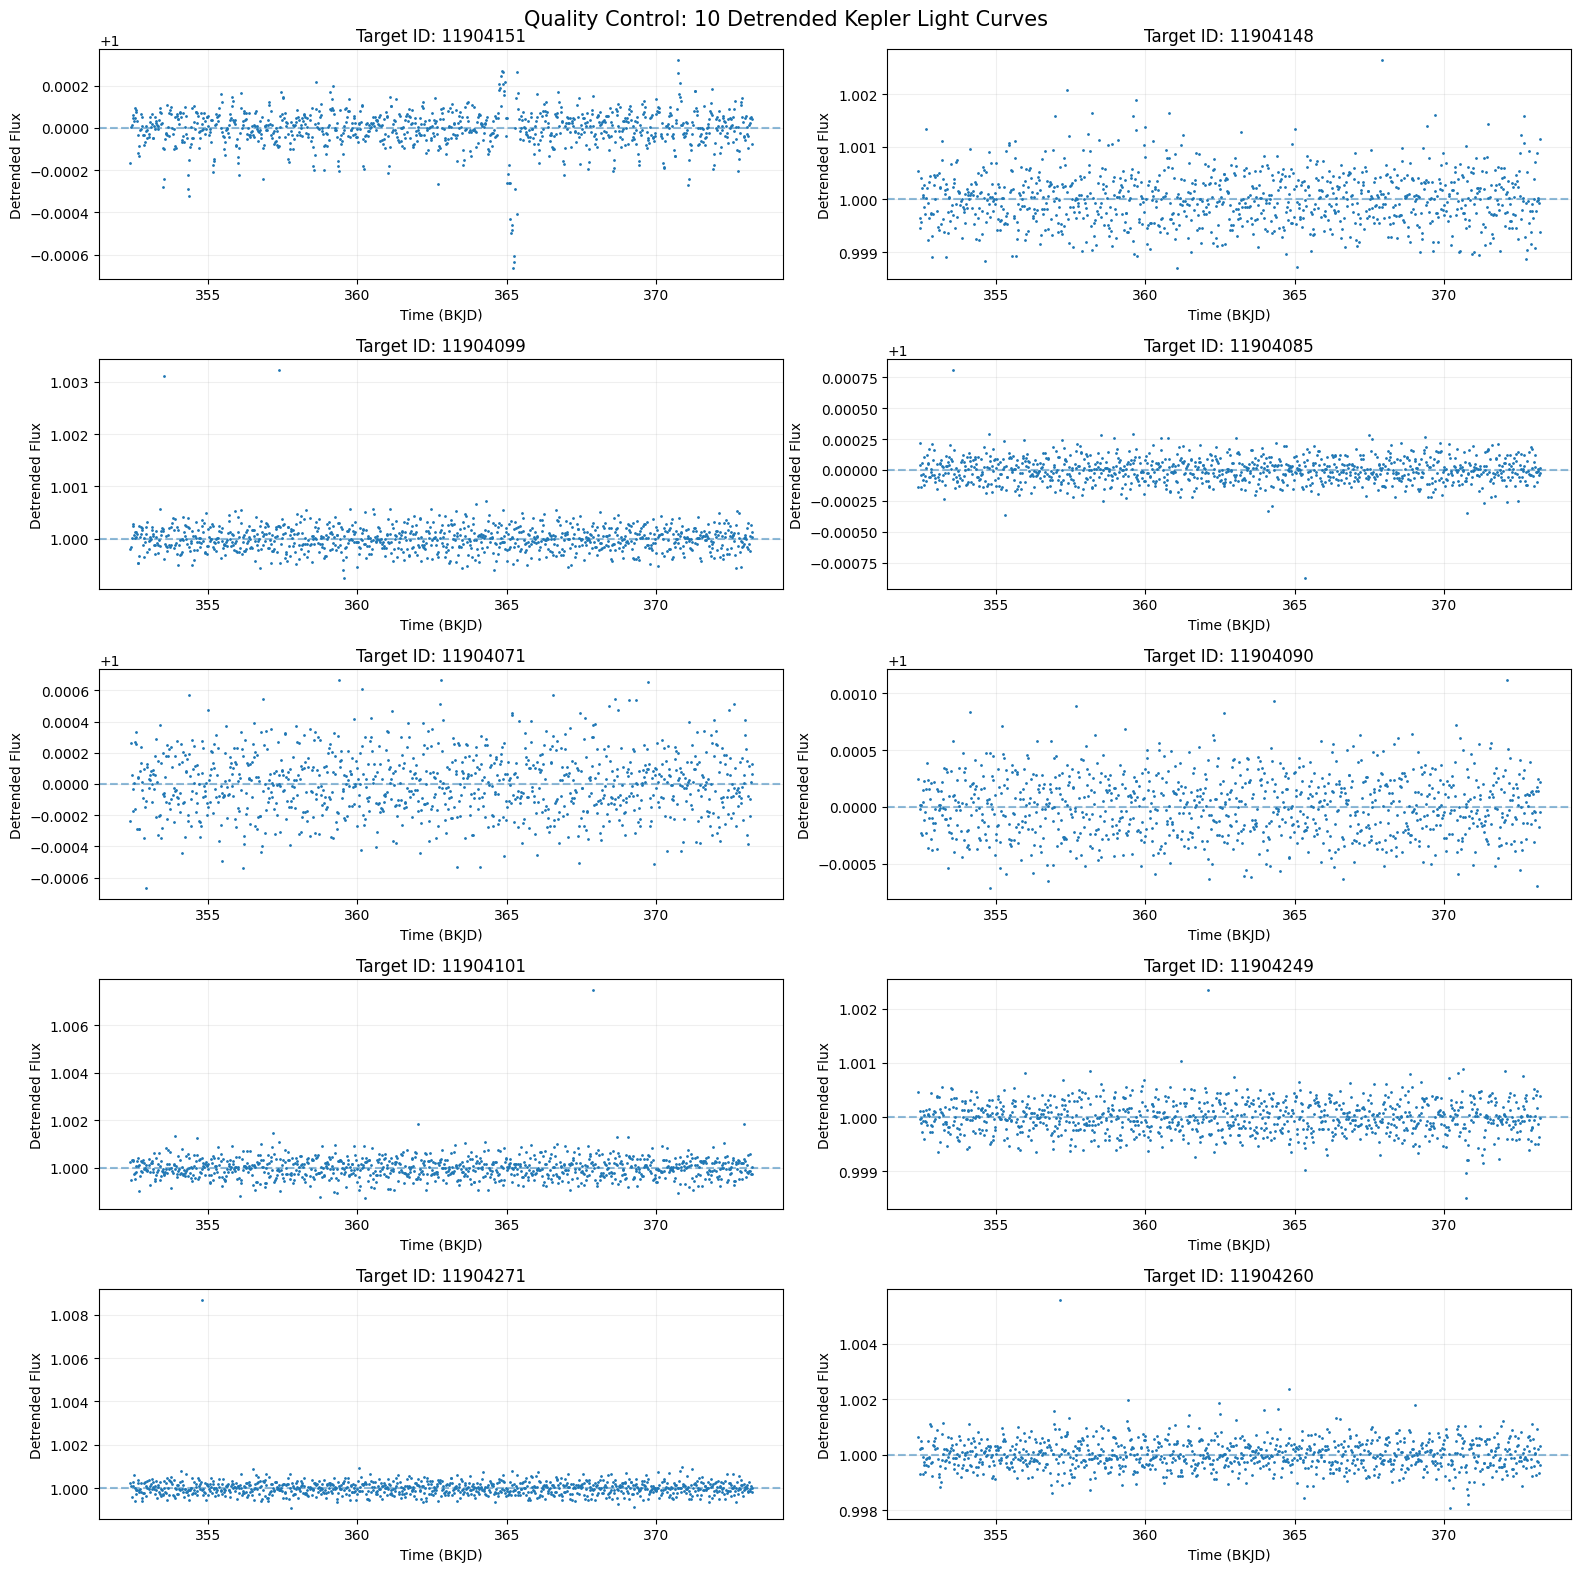

In [38]:
# 2. Step 3.13 — Visual quality control across all 10 targets
fig, axes = plt.subplots(
    5, 2,
    figsize=(16, 16)
)

axes = axes.flatten()

for i, (ax, lc) in enumerate(zip(axes, processed_lcs)):

    ax.plot(
        lc.time.value,
        lc.flux.value,
        ".",
        markersize=2
    )

    target_id = pilot_lcs_clean[i].meta.get("TARGETID")

    ax.axhline(
        1.0,
        linestyle="--",
        alpha=0.5
    )

    ax.set_title(f"Target ID: {target_id}")
    ax.set_xlabel("Time (BKJD)")
    ax.set_ylabel("Detrended Flux")
    ax.grid(alpha=0.2)

plt.suptitle(
    "Quality Control: 10 Detrended Kepler Light Curves",
    fontsize=15
)

plt.tight_layout()
plt.show()

In [39]:
outlier_summary = []
outlier_details = []

for i, lc in enumerate(processed_lcs):

    flux = np.asarray(lc.flux.value, dtype=float)
    time = np.asarray(lc.time.value, dtype=float)

    median_flux = np.median(flux)

    mad = np.median(
        np.abs(flux - median_flux)
    )

    if mad == 0:
        print(f"Target {i}: MAD is zero; skipping.")
        continue

    robust_z = (
        0.6745 * (flux - median_flux) / mad
    )

    outlier_mask = np.abs(robust_z) > 5

    target_id = pilot_lcs_clean[i].meta.get("TARGETID")

    outlier_summary.append({
        "Target_ID": target_id,
        "Total_Points": len(flux),
        "Outlier_Count": int(outlier_mask.sum()),
        "Outlier_Percentage": (
            outlier_mask.sum() / len(flux)
        ) * 100
    })

    for j in np.where(outlier_mask)[0]:

        outlier_details.append({
            "Target_ID": target_id,
            "Time_BKJD": time[j],
            "Flux": flux[j],
            "Robust_Z": robust_z[j]
        })

outlier_summary_table = pd.DataFrame(outlier_summary)
outlier_details_table = pd.DataFrame(outlier_details)

print("Outlier summary:")
display(outlier_summary_table.round(4))

print("\nIndividual flagged observations:")
display(outlier_details_table)

Outlier summary:


,Target_ID,Total_Points,Outlier_Count,Outlier_Percentage
0,11904151,1008,8,0.7937
1,11904148,1008,1,0.0992
2,11904099,1008,2,0.1984
3,11904085,1008,2,0.1984
4,11904071,1008,0,0.0000
5,11904090,1008,0,0.0000
6,11904101,1008,1,0.0992
7,11904249,1008,2,0.1984
8,11904271,1008,1,0.0992
9,11904260,1008,1,0.0992



Individual flagged observations:


,Target_ID,Time_BKJD,Flux,Robust_Z
0,11904151,365.127443,0.999570,-6.151955
1,11904151,365.147877,0.999503,-7.097850
2,11904151,365.168310,0.999542,-6.555579
3,11904151,365.188743,0.999518,-6.896037
4,11904151,365.209177,0.999335,-9.479500
5,11904151,365.229610,0.999364,-9.078955
6,11904151,365.250043,0.999393,-8.661466
7,11904151,365.352210,0.999593,-5.826702
8,11904148,367.926809,1.002650,5.565221
9,11904099,353.541795,1.003108,13.934572


In [40]:
from lightkurve.utils import KeplerQualityFlags

quality_check_results = []

for _, row in outlier_details_table.iterrows():

    target_id = int(row["Target_ID"])
    flagged_time = float(row["Time_BKJD"])

    # Find the corresponding original light curve
    matching_indices = [
        i for i, lc in enumerate(pilot_lcs_clean)
        if int(lc.meta.get("TARGETID")) == target_id
    ]

    if not matching_indices:
        continue

    original_lc = pilot_lcs_clean[matching_indices[0]]

    original_time = np.asarray(
        original_lc.time.value,
        dtype=float
    )

    original_quality = np.asarray(
        original_lc.quality.value
    )

    # Find nearest original observation
    nearest_index = np.argmin(
        np.abs(original_time - flagged_time)
    )

    nearest_time = original_time[nearest_index]
    quality_flag = int(original_quality[nearest_index])

    quality_check_results.append({
        "Target_ID": target_id,
        "Flagged_Time": flagged_time,
        "Matched_Time": nearest_time,
        "Time_Difference": abs(nearest_time - flagged_time),
        "Quality_Flag": quality_flag
    })

quality_check_table = pd.DataFrame(
    quality_check_results
)

quality_check_table["Quality_Flag"] = (
    quality_check_table["Quality_Flag"].astype("int64")
)

display(quality_check_table.round(8))

print("\nDecoded quality flags:")

for flag in sorted(
    quality_check_table["Quality_Flag"].unique()
):
    print(f"\nFlag {flag}:")
    print(KeplerQualityFlags.decode(flag))

,Target_ID,Flagged_Time,Matched_Time,Time_Difference,Quality_Flag
0,11904151,365.127443,365.127443,0.0,0
1,11904151,365.147877,365.147877,0.0,0
2,11904151,365.168310,365.168310,0.0,0
3,11904151,365.188743,365.188743,0.0,0
4,11904151,365.209177,365.209177,0.0,16
5,11904151,365.229610,365.229610,0.0,16
6,11904151,365.250043,365.250043,0.0,16
7,11904151,365.352210,365.352210,0.0,144
8,11904148,367.926809,367.926809,0.0,128
9,11904099,353.541795,353.541795,0.0,2176



Decoded quality flags:

Flag 0:
[]

Flag 16:
['Zero crossing']

Flag 128:
['Cosmic ray in optimal aperture']

Flag 144:
['Zero crossing', 'Cosmic ray in optimal aperture']

Flag 2176:
['Cosmic ray in optimal aperture', 'Impulsive outlier']

Flag 2192:
['Zero crossing', 'Cosmic ray in optimal aperture', 'Impulsive outlier']

Flag 8208:
['Zero crossing', 'Cosmic ray in collateral data']


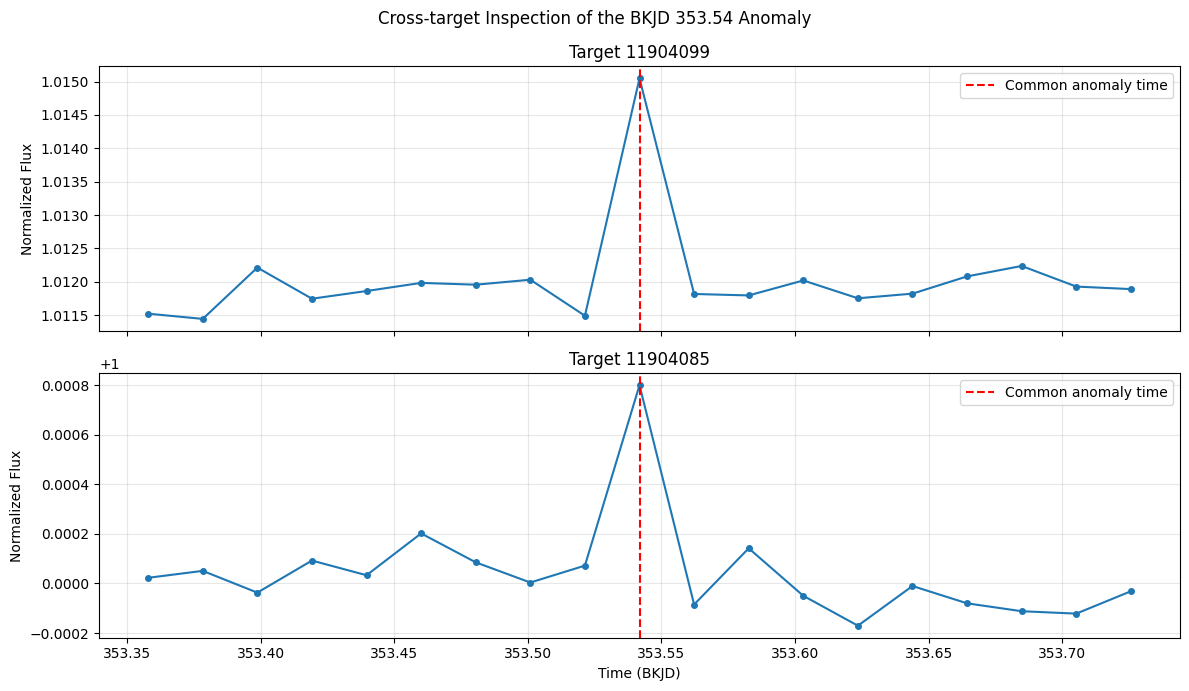

In [41]:
# Compare two targets around the common anomaly
targets_to_inspect = [11904099, 11904085]
event_time = 353.541795

fig, axes = plt.subplots(
    2, 1,
    figsize=(12, 7),
    sharex=True
)

for ax, target_id in zip(axes, targets_to_inspect):

    matching_index = next(
        i for i, lc in enumerate(pilot_lcs_clean)
        if int(lc.meta.get("TARGETID")) == target_id
    )

    lc = pilot_lcs_clean[matching_index]

    time = np.asarray(lc.time.value, dtype=float)
    flux = np.asarray(
        lc.flux.value.filled(np.nan),
        dtype=float
    )

    valid = np.isfinite(time) & np.isfinite(flux)

    time = time[valid]
    flux = flux[valid]

    normalized = flux / np.median(flux)

    local_mask = np.abs(time - event_time) <= 0.20

    ax.plot(
        time[local_mask],
        normalized[local_mask],
        "o-",
        markersize=4
    )

    ax.axvline(
        event_time,
        linestyle="--",
        color="red",
        label="Common anomaly time"
    )

    ax.set_title(f"Target {target_id}")
    ax.set_ylabel("Normalized Flux")
    ax.legend()
    ax.grid(alpha=0.3)

axes[-1].set_xlabel("Time (BKJD)")

plt.suptitle(
    "Cross-target Inspection of the BKJD 353.54 Anomaly"
)

plt.tight_layout()
plt.show()

In [42]:
# 4. Next step — quantify flagged cadences across all ten targets
from lightkurve.utils import KeplerQualityFlags

quality_summary = []

for lc in pilot_lcs_clean:

    target_id = int(lc.meta["TARGETID"])

    quality = np.asarray(
        lc.quality.value,
        dtype=np.int64
    )

    # Identify cosmic-ray and impulsive-outlier flags
    cosmic_ray_mask = (
        (quality & 128) != 0
    )

    impulsive_mask = (
        (quality & 2048) != 0
    )

    combined_mask = cosmic_ray_mask | impulsive_mask

    quality_summary.append({
        "Target_ID": target_id,
        "Total_Observations": len(quality),
        "Cosmic_Ray_Flagged": int(cosmic_ray_mask.sum()),
        "Impulsive_Outlier_Flagged": int(impulsive_mask.sum()),
        "Either_Flagged": int(combined_mask.sum()),
        "Zero_Flag": int((quality == 0).sum())
    })

quality_summary_table = pd.DataFrame(quality_summary)

display(quality_summary_table)

,Target_ID,Total_Observations,Cosmic_Ray_Flagged,Impulsive_Outlier_Flagged,Either_Flagged,Zero_Flag
0,11904151,1011,29,1,29,926
1,11904148,1011,19,0,19,944
2,11904099,1011,15,2,15,940
3,11904085,1011,51,2,51,893
4,11904071,1011,13,0,13,948
5,11904090,1011,10,0,10,948
6,11904101,1011,15,1,15,948
7,11904249,1011,22,1,22,933
8,11904271,1011,14,1,14,947
9,11904260,1011,24,1,24,936


In [43]:
# 3. Step 3.15 — create quality-controlled light curves
# Quality-controlled preprocessing
# Preserve original pilot_lcs_clean unchanged.

quality_controlled_lcs = []
quality_control_summary = []

BAD_QUALITY_BITS = 128 | 2048

for i, lc in enumerate(pilot_lcs_clean):

    time = np.asarray(lc.time.value, dtype=float)

    flux = np.asarray(
        lc.flux.value.filled(np.nan),
        dtype=float
    )

    quality = np.asarray(
        lc.quality.value,
        dtype=np.int64
    )

    # Identify observations with cosmic-ray or
    # impulsive-outlier quality bits
    bad_quality = (
        (quality & BAD_QUALITY_BITS) != 0
    )

    # Require finite time and flux
    finite_mask = (
        np.isfinite(time) &
        np.isfinite(flux)
    )

    # Retain valid observations without bad quality bits
    good_mask = finite_mask & (~bad_quality)

    time_good = time[good_mask]
    flux_good = flux[good_mask]

    # Normalize after quality filtering
    baseline = np.median(flux_good)
    normalized_flux_good = flux_good / baseline

    # Construct filtered light curve
    clean_lc = lk.LightCurve(
        time=time_good,
        flux=normalized_flux_good
    )

    # Detrend after masking
    flattened_lc = clean_lc.flatten(
        window_length=51,
        polyorder=2
    )

    quality_controlled_lcs.append(flattened_lc)

    quality_control_summary.append({
        "Target_ID": int(lc.meta["TARGETID"]),
        "Original_Rows": len(time),
        "Finite_Observations": int(finite_mask.sum()),
        "Quality_Flagged_Removed": int(
            (finite_mask & bad_quality).sum()
        ),
        "Remaining_Observations": len(time_good),
        "Processed_Observations": len(flattened_lc),
        "Normalized_Median": np.median(normalized_flux_good),
        "Detrended_Scatter": np.std(
            np.asarray(flattened_lc.flux.value, dtype=float)
        )
    })

quality_control_table = pd.DataFrame(
    quality_control_summary
)

display(quality_control_table.round(7))

print(
    "Quality-controlled targets:",
    len(quality_controlled_lcs)
)

,Target_ID,Original_Rows,Finite_Observations,Quality_Flagged_Removed,Remaining_Observations,Processed_Observations,Normalized_Median,Detrended_Scatter
0,11904151,1011,1008,29,979,979,1.0,0.000086
1,11904148,1011,1008,19,989,989,1.0,0.000491
2,11904099,1011,1008,15,993,993,1.0,0.000227
3,11904085,1011,1008,51,957,957,1.0,0.000098
4,11904071,1011,1008,13,995,995,1.0,0.000199
5,11904090,1011,1008,10,998,998,1.0,0.000266
6,11904101,1011,1008,15,993,993,1.0,0.000416
7,11904249,1011,1008,22,986,986,1.0,0.000296
8,11904271,1011,1008,14,994,994,1.0,0.000283
9,11904260,1011,1008,24,984,984,1.0,0.000512


Quality-controlled targets: 10


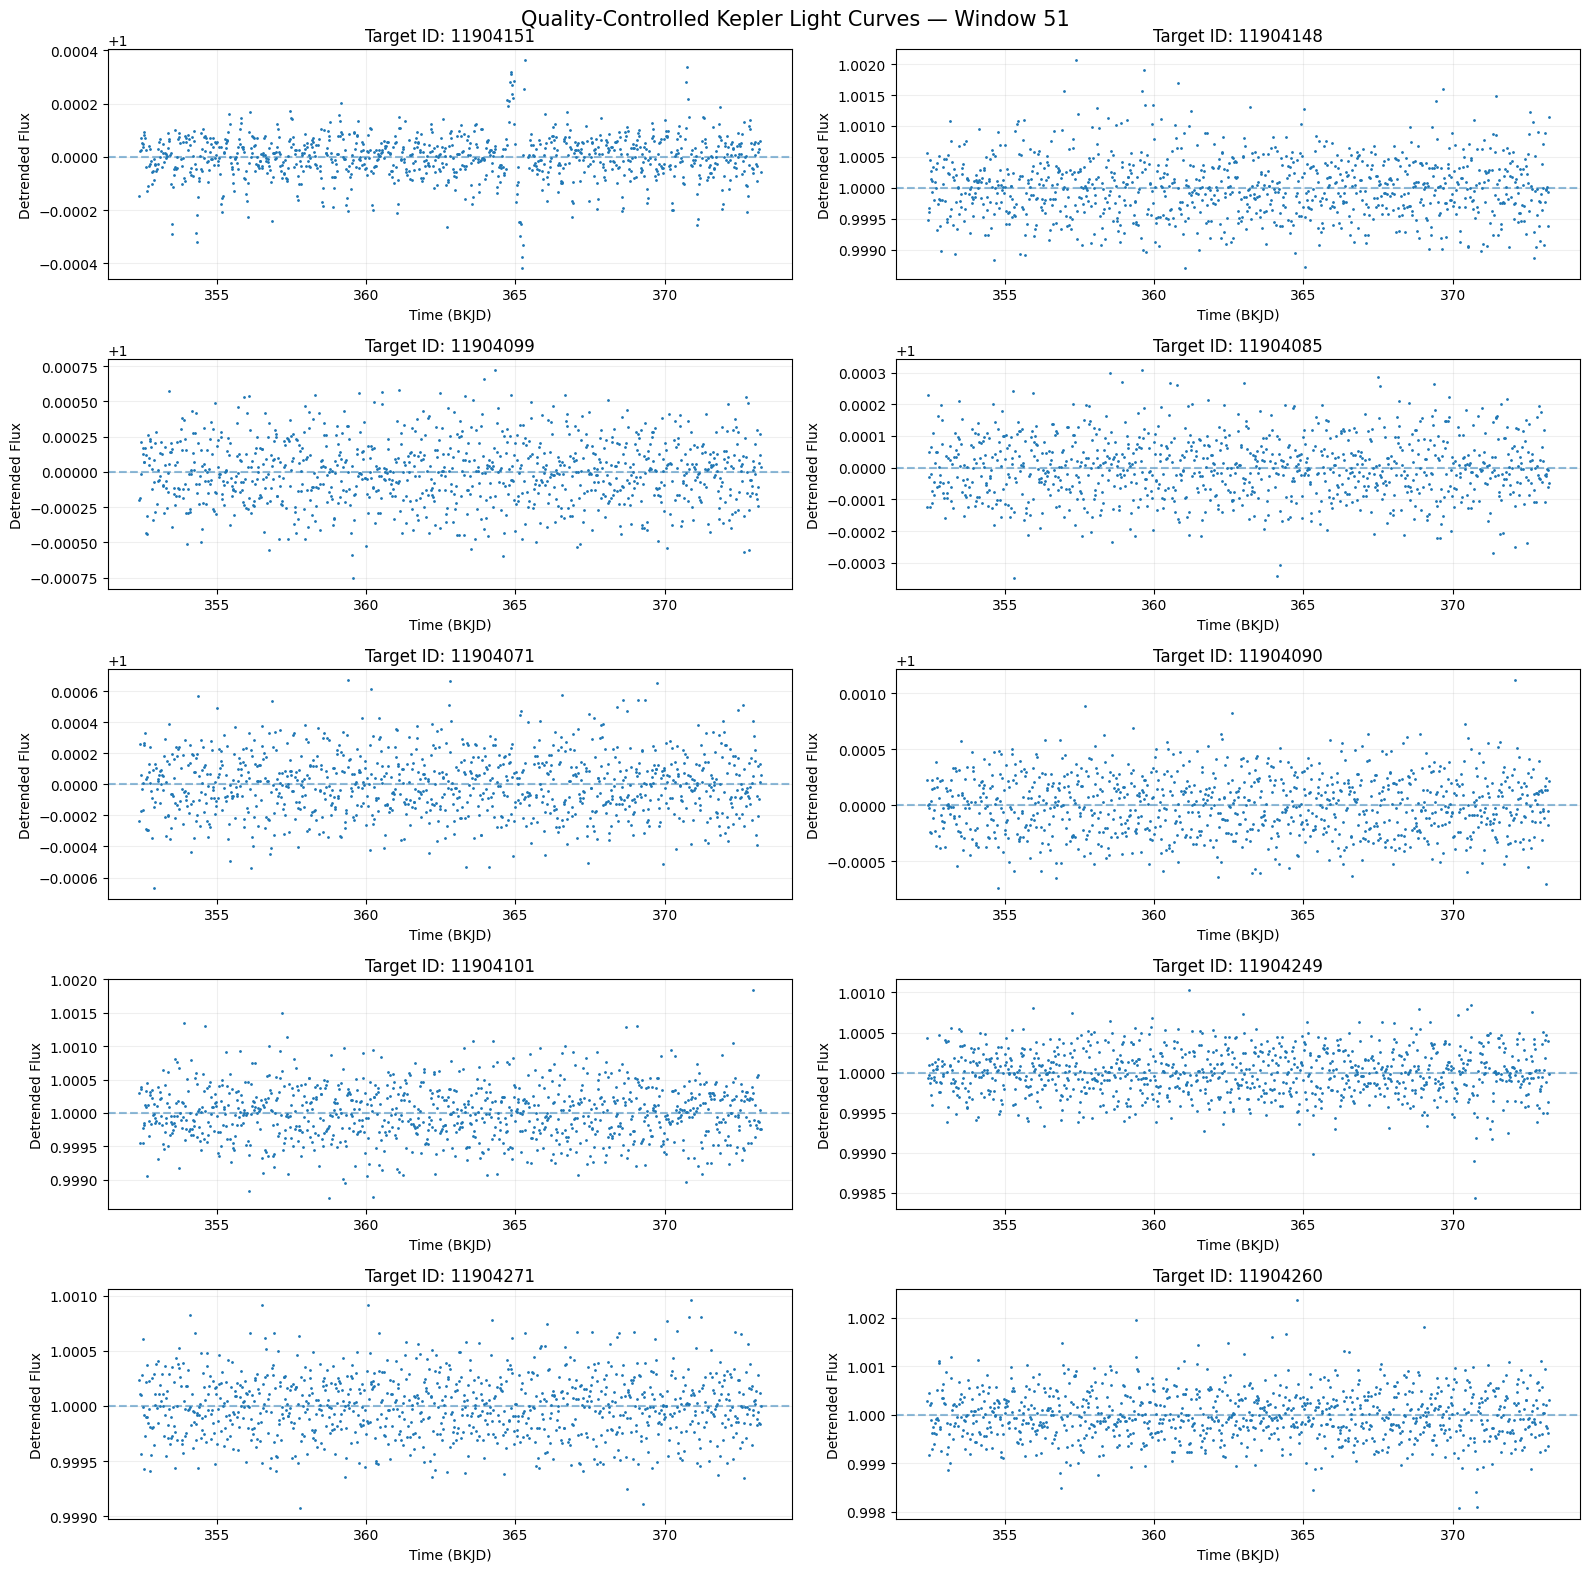

In [44]:
# quality control after masking
fig, axes = plt.subplots(
    5, 2,
    figsize=(16, 16)
)

axes = axes.flatten()

for i, (ax, lc) in enumerate(
    zip(axes, quality_controlled_lcs)
):

    time = np.asarray(lc.time.value, dtype=float)
    flux = np.asarray(lc.flux.value, dtype=float)

    target_id = pilot_lcs_clean[i].meta.get("TARGETID")

    ax.plot(
        time,
        flux,
        ".",
        markersize=2
    )

    ax.axhline(
        1.0,
        linestyle="--",
        alpha=0.5
    )

    ax.set_title(f"Target ID: {target_id}")
    ax.set_xlabel("Time (BKJD)")
    ax.set_ylabel("Detrended Flux")
    ax.grid(alpha=0.2)

plt.suptitle(
    "Quality-Controlled Kepler Light Curves — Window 51",
    fontsize=15
)

plt.tight_layout()
plt.show()

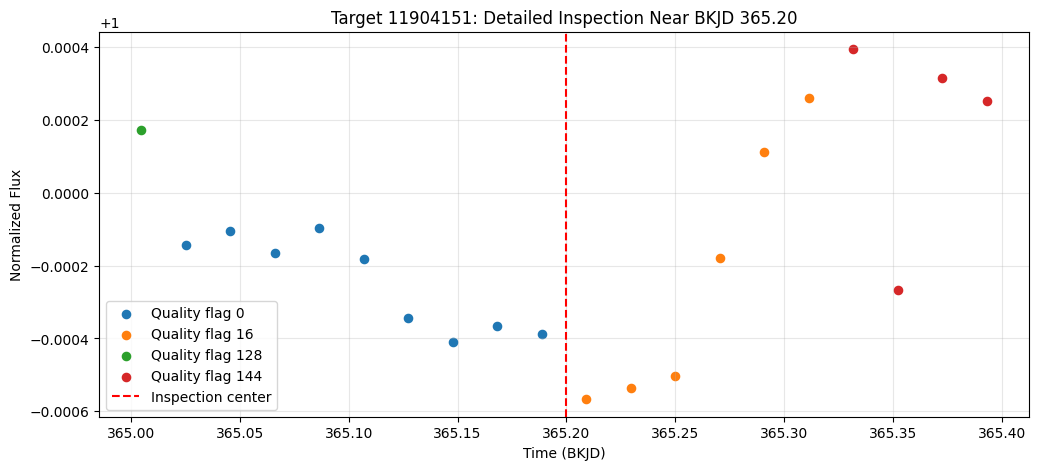

Observations in inspection window: 20
 Time_BKJD  Normalized_Flux  Quality_Flag
365.004844         1.000171           128
365.025277         0.999857             0
365.045710         0.999894             0
365.066143         0.999833             0
365.086577         0.999904             0
365.107010         0.999819             0
365.127443         0.999655             0
365.147877         0.999591             0
365.168310         0.999633             0
365.188743         0.999612             0
365.209177         0.999433            16
365.229610         0.999465            16
365.250043         0.999497            16
365.270476         0.999820            16
365.290910         1.000111            16
365.311343         1.000261            16
365.331776         1.000394           144
365.352210         0.999733           144
365.372643         1.000314           144
365.393076         1.000252           144


In [45]:
# inspect the event at higher resolution
# Detailed inspection of Target 11904151 near BKJD 365

target_id = 11904151
event_center = 365.20
time_window = 0.20

lc_original = next(
    lc for lc in pilot_lcs_clean
    if int(lc.meta["TARGETID"]) == target_id
)

time = np.asarray(lc_original.time.value, dtype=float)

flux = np.asarray(
    lc_original.flux.value.filled(np.nan),
    dtype=float
)

quality = np.asarray(
    lc_original.quality.value,
    dtype=np.int64
)

normalized_flux = flux / np.nanmedian(flux)

local_mask = (
    (np.abs(time - event_center) <= time_window) &
    np.isfinite(time) &
    np.isfinite(normalized_flux)
)

local_time = time[local_mask]
local_flux = normalized_flux[local_mask]
local_quality = quality[local_mask]

plt.figure(figsize=(12, 5))

for flag in np.unique(local_quality):
    mask = local_quality == flag

    plt.scatter(
        local_time[mask],
        local_flux[mask],
        label=f"Quality flag {flag}",
        s=35
    )

plt.axvline(
    event_center,
    color="red",
    linestyle="--",
    label="Inspection center"
)

plt.xlabel("Time (BKJD)")
plt.ylabel("Normalized Flux")
plt.title("Target 11904151: Detailed Inspection Near BKJD 365.20")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

print("Observations in inspection window:", len(local_time))

print(
    pd.DataFrame({
        "Time_BKJD": local_time,
        "Normalized_Flux": local_flux,
        "Quality_Flag": local_quality
    }).to_string(index=False)
)

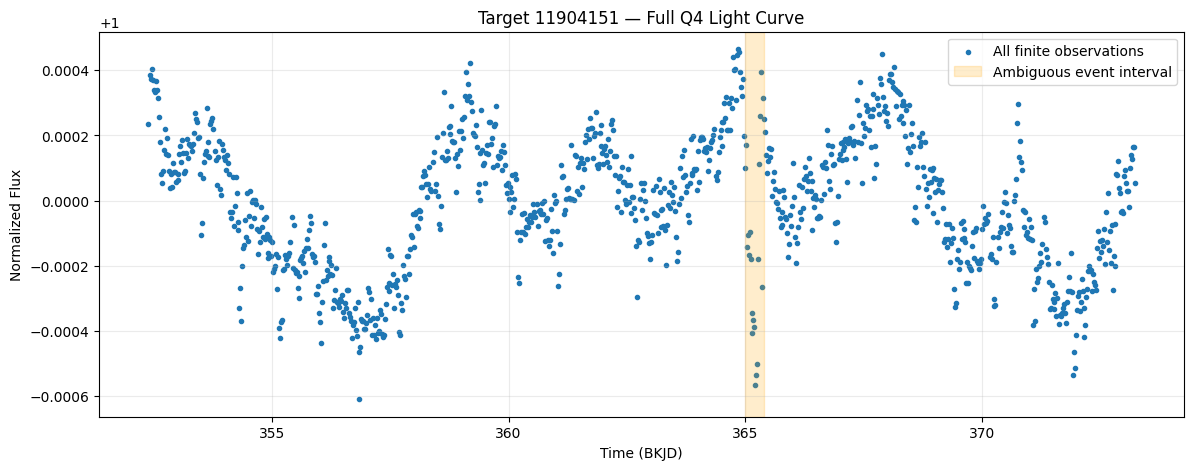

In [46]:
# Inspect the complete time series around the suspected event
target_id = 11904151

lc = next(
    item for item in pilot_lcs_clean
    if int(item.meta["TARGETID"]) == target_id
)

time = np.asarray(lc.time.value, dtype=float)

flux = np.asarray(
    lc.flux.value.filled(np.nan),
    dtype=float
)

quality = np.asarray(lc.quality.value, dtype=np.int64)

valid = np.isfinite(time) & np.isfinite(flux)

time = time[valid]
flux = flux[valid]
quality = quality[valid]

normalized_flux = flux / np.median(flux)

plt.figure(figsize=(14, 5))

plt.scatter(
    time,
    normalized_flux,
    s=9,
    label="All finite observations"
)

plt.axvspan(
    365.00,
    365.40,
    color="orange",
    alpha=0.2,
    label="Ambiguous event interval"
)

plt.xlabel("Time (BKJD)")
plt.ylabel("Normalized Flux")
plt.title("Target 11904151 — Full Q4 Light Curve")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

Target ID: 11904151
Best period (days): 0.8372837283728374
Best duration (hours): 2.0
Best epoch (BKJD): 352.67670495217993
Maximum BLS power: 1.183447929701398e-06


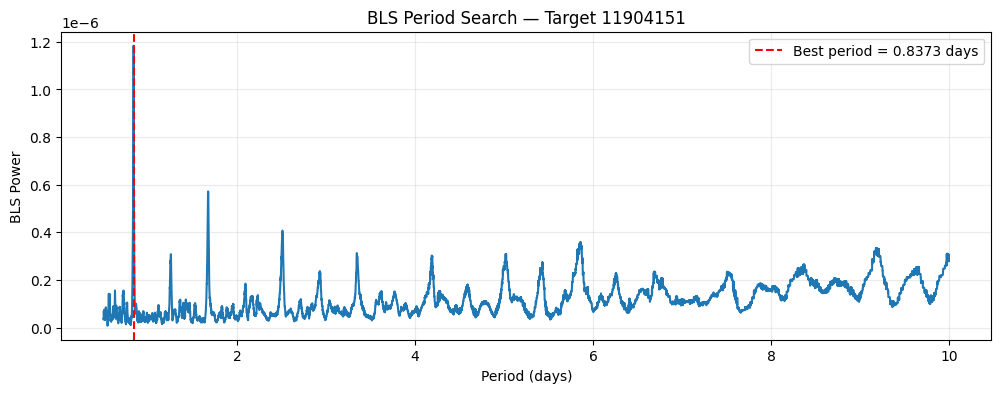

In [48]:
# BLS period search — compatible call

periods = np.linspace(0.5, 10.0, 10000)
durations = np.array([1, 2, 3, 4, 5]) / 24.0

bls = BoxLeastSquares(bls_time, bls_flux)

periodogram = bls.power(
    periods,
    durations
)

best_index = np.argmax(periodogram.power)

best_period = periodogram.period[best_index]
best_duration = periodogram.duration[best_index]
best_epoch = periodogram.transit_time[best_index]
best_power = periodogram.power[best_index]

print("Target ID:", target_id)
print("Best period (days):", best_period)
print("Best duration (hours):", best_duration * 24)
print("Best epoch (BKJD):", best_epoch)
print("Maximum BLS power:", best_power)

plt.figure(figsize=(12, 4))
plt.plot(periodogram.period, periodogram.power)

plt.axvline(
    best_period,
    color="red",
    linestyle="--",
    label=f"Best period = {best_period:.4f} days"
)

plt.xlabel("Period (days)")
plt.ylabel("BLS Power")
plt.title("BLS Period Search — Target 11904151")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

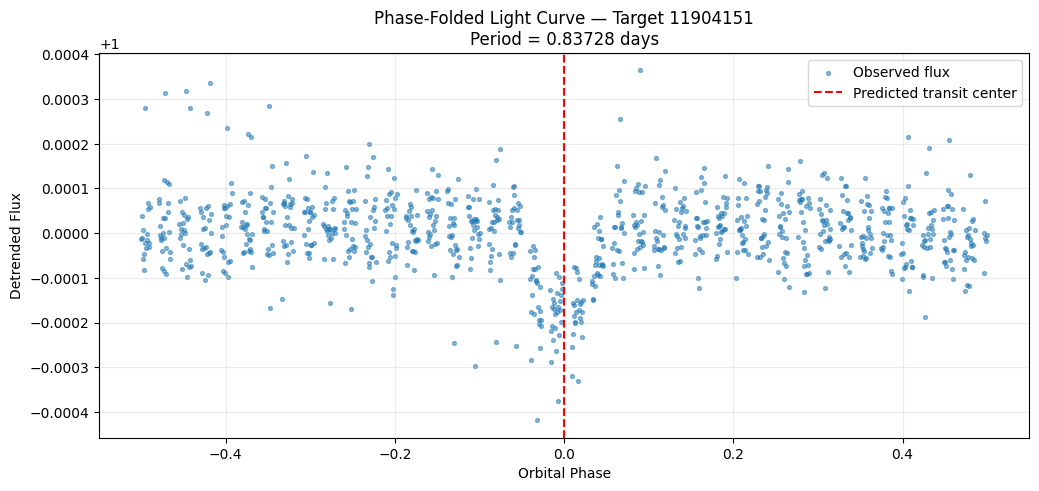

In [49]:
# inspect the phase-folded light curve
# Phase-fold the light curve at the strongest BLS period

phase = (
    (bls_time - best_epoch + best_period / 2)
    % best_period
) / best_period - 0.5

# Sort by phase for visualization
sort_idx = np.argsort(phase)

phase_sorted = phase[sort_idx]
flux_sorted = bls_flux[sort_idx]

plt.figure(figsize=(12, 5))

plt.scatter(
    phase_sorted,
    flux_sorted,
    s=8,
    alpha=0.5,
    label="Observed flux"
)

plt.axvline(
    0,
    color="red",
    linestyle="--",
    label="Predicted transit center"
)

plt.xlabel("Orbital Phase")
plt.ylabel("Detrended Flux")
plt.title(
    f"Phase-Folded Light Curve — Target {target_id}\n"
    f"Period = {best_period:.5f} days"
)

plt.legend()
plt.grid(alpha=0.25)
plt.show()

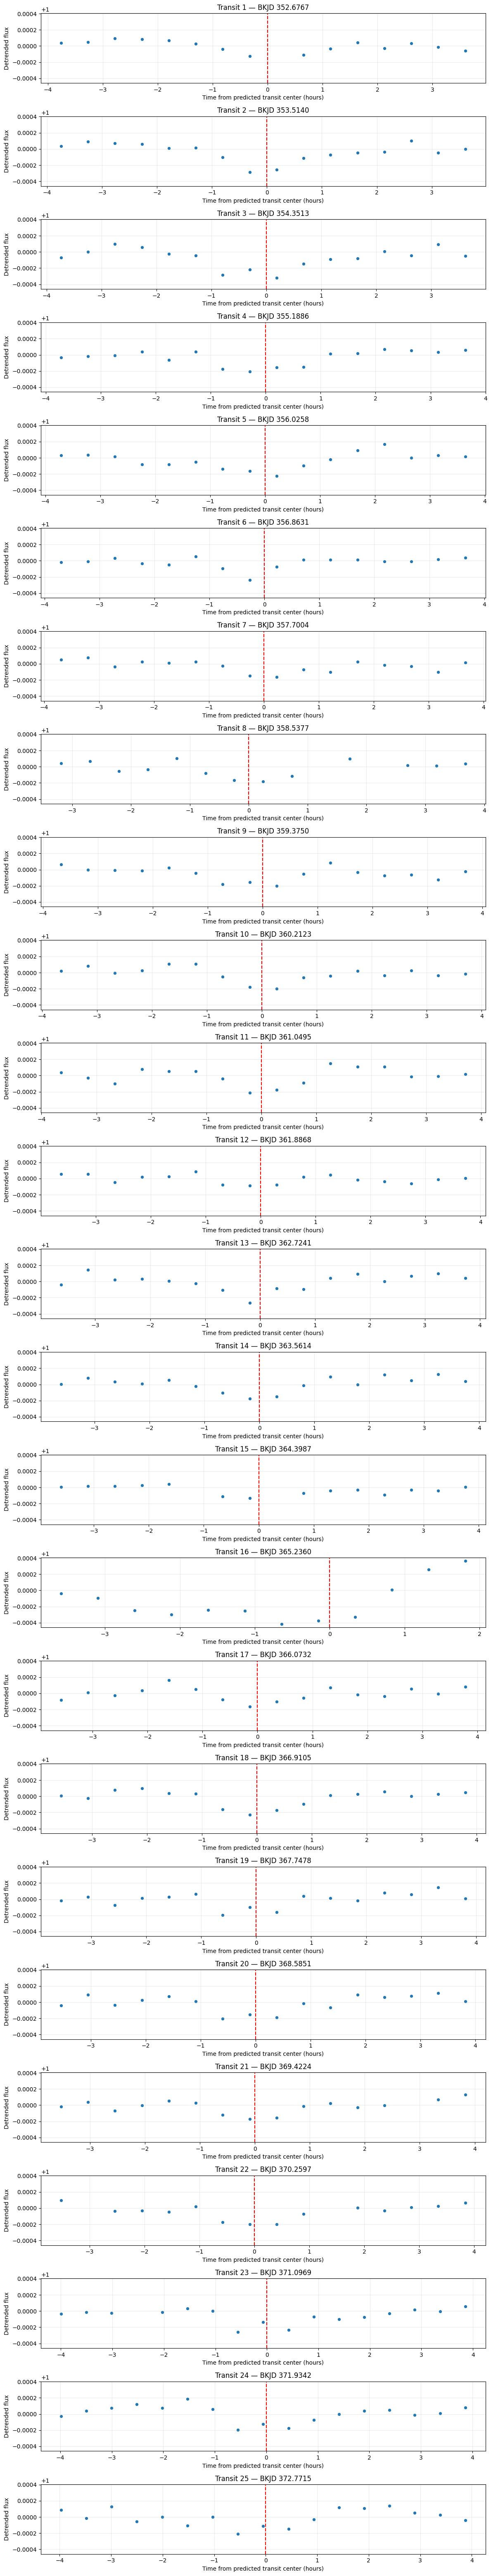

Number of predicted transits: 25


In [50]:
# inspect individual predicted transits
# Individual transit inspection
# Uses the current BLS period, epoch and duration.

transit_numbers = np.arange(
    np.ceil((bls_time.min() - best_epoch) / best_period),
    np.floor((bls_time.max() - best_epoch) / best_period) + 1
)

predicted_transit_times = (
    best_epoch + transit_numbers * best_period
)

half_window = 2 * best_duration

fig, axes = plt.subplots(
    len(predicted_transit_times),
    1,
    figsize=(12, 2.5 * len(predicted_transit_times)),
    sharey=True
)

if len(predicted_transit_times) == 1:
    axes = [axes]

for i, (ax, transit_time) in enumerate(
    zip(axes, predicted_transit_times)
):

    mask = (
        np.abs(bls_time - transit_time) <= half_window
    )

    local_time = bls_time[mask] - transit_time
    local_flux = bls_flux[mask]

    ax.scatter(
        local_time * 24,
        local_flux,
        s=18
    )

    ax.axvline(
        0,
        color="red",
        linestyle="--"
    )

    ax.set_title(
        f"Transit {i + 1} — BKJD {transit_time:.4f}"
    )

    ax.set_xlabel("Time from predicted transit center (hours)")
    ax.set_ylabel("Detrended flux")
    ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()

print("Number of predicted transits:", len(predicted_transit_times))

In [51]:
transit_numbers = np.arange(
    np.ceil((bls_time.min() - best_epoch) / best_period),
    np.floor((bls_time.max() - best_epoch) / best_period) + 1
)

predicted_transit_times = (
    best_epoch + transit_numbers * best_period
)

In [52]:
half_window = 2 * best_duration

In [53]:
mask = (
    np.abs(bls_time - transit_time) <= half_window
)

In [54]:
print("Best period (days):", best_period)
print("Best epoch (BKJD):", best_epoch)
print("Best duration (days):", best_duration)
print("Best duration (hours):", best_duration * 24)

print("\nNumber of predicted transit centers:",
      len(predicted_transit_times))

print("\nObservation baseline:")
print("Start:", bls_time.min())
print("End:", bls_time.max())

print("\nInspection window (hours):",
      half_window * 24, "on each side")

Best period (days): 0.8372837283728374
Best epoch (BKJD): 352.67670495217993
Best duration (days): 0.08333333333333333
Best duration (hours): 2.0

Number of predicted transit centers: 25

Observation baseline:
Start: 352.3975382855133
End: 373.21904601071583

Inspection window (hours): 4.0 on each side


In [55]:
coverage_records = []

for i, transit_time in enumerate(predicted_transit_times):

    mask = (
        np.abs(bls_time - transit_time) <= half_window
    )

    local_time = bls_time[mask]

    coverage_records.append({
        "Transit_Number": i + 1,
        "Transit_Center_BKJD": transit_time,
        "Observations_in_Window": len(local_time),
        "First_Observation_Hours": (
            (local_time.min() - transit_time) * 24
            if len(local_time) > 0 else np.nan
        ),
        "Last_Observation_Hours": (
            (local_time.max() - transit_time) * 24
            if len(local_time) > 0 else np.nan
        )
    })

coverage_df = pd.DataFrame(coverage_records)

display(coverage_df)

print("Minimum observations in a window:",
      coverage_df["Observations_in_Window"].min())

print("Maximum observations in a window:",
      coverage_df["Observations_in_Window"].max())

print("Windows with fewer than 5 observations:",
      (coverage_df["Observations_in_Window"] < 5).sum())

,Transit_Number,Transit_Center_BKJD,Observations_in_Window,First_Observation_Hours,Last_Observation_Hours
0,1,352.676705,15,-3.757623,3.598322
1,2,353.513989,16,-3.746184,3.609763
2,3,354.351272,16,-3.734739,3.621211
3,4,355.188556,16,-3.723283,3.632667
4,5,356.025840,16,-3.711822,3.644133
5,6,356.863124,16,-3.700354,3.655607
6,7,357.700407,16,-3.688878,3.667084
7,8,358.537691,13,-3.186996,3.678573
8,9,359.374975,16,-3.665896,3.690066
9,10,360.212259,16,-3.654399,3.701571


Minimum observations in a window: 12
Maximum observations in a window: 17
Windows with fewer than 5 observations: 0


In [56]:
# inspect cadence gaps and in-transit sampling
sampling_records = []

for i, transit_time in enumerate(predicted_transit_times):

    mask = np.abs(bls_time - transit_time) <= half_window

    local_time = bls_time[mask]
    local_flux = bls_flux[mask]

    # Convert relative time into hours
    relative_hours = (local_time - transit_time) * 24

    # Count observations inside nominal transit duration
    in_transit = np.abs(relative_hours) <= (
        best_duration * 24 / 2
    )

    # Calculate gaps between consecutive observations
    time_gaps = np.diff(local_time) * 24

    sampling_records.append({
        "Transit_Number": i + 1,
        "Total_Points": len(local_time),
        "In_Transit_Points": np.sum(in_transit),
        "Before_Transit_Points": np.sum(relative_hours < -1),
        "After_Transit_Points": np.sum(relative_hours > 1),
        "Maximum_Cadence_Gap_Hours": (
            np.max(time_gaps) if len(time_gaps) > 0 else np.nan
        )
    })

sampling_df = pd.DataFrame(sampling_records)

display(sampling_df)

print(
    "Events with fewer than 3 in-transit observations:",
    (sampling_df["In_Transit_Points"] < 3).sum()
)

print(
    "Events with cadence gaps above 1 hour:",
    (sampling_df["Maximum_Cadence_Gap_Hours"] > 1).sum()
)


,Transit_Number,Total_Points,In_Transit_Points,Before_Transit_Points,After_Transit_Points,Maximum_Cadence_Gap_Hours
0,1,15,3,6,6,0.980793
1,2,16,4,6,6,0.490399
2,3,16,4,6,6,0.490399
3,4,16,4,6,6,0.490399
4,5,16,4,6,6,0.490399
5,6,16,4,6,6,0.490400
6,7,16,4,6,6,0.490400
7,8,13,4,5,4,0.980795
8,9,16,4,6,6,0.490400
9,10,16,4,6,6,0.490400


Events with fewer than 3 in-transit observations: 0
Events with cadence gaps above 1 hour: 0


In [57]:
# measure the depth of each individual event
event_depth_records = []

for i, transit_time in enumerate(predicted_transit_times):

    # Select observations within +/- 4 hours
    mask = np.abs(bls_time - transit_time) <= half_window

    local_time = bls_time[mask]
    local_flux = bls_flux[mask]

    relative_hours = (local_time - transit_time) * 24

    # Nominal 2-hour transit: +/- 1 hour
    in_transit = np.abs(relative_hours) <= 1

    out_of_transit = ~in_transit

    if np.sum(in_transit) < 3 or np.sum(out_of_transit) < 3:
        continue

    # Robust local baseline and transit level
    baseline_flux = np.median(local_flux[out_of_transit])
    transit_flux = np.median(local_flux[in_transit])

    # Positive depth means flux decreases during transit
    measured_depth = baseline_flux - transit_flux

    event_depth_records.append({
        "Transit_Number": i + 1,
        "Transit_Center_BKJD": transit_time,
        "In_Transit_Points": np.sum(in_transit),
        "Out_Of_Transit_Points": np.sum(out_of_transit),
        "Local_Baseline": baseline_flux,
        "Median_In_Transit_Flux": transit_flux,
        "Measured_Depth": measured_depth
    })

event_depth_df = pd.DataFrame(event_depth_records)

display(event_depth_df)

print("Events evaluated:", len(event_depth_df))
print("Events with positive measured depth:",
      (event_depth_df["Measured_Depth"] > 0).sum())

print("Median measured depth:",
      event_depth_df["Measured_Depth"].median())

,Transit_Number,Transit_Center_BKJD,In_Transit_Points,Out_Of_Transit_Points,Local_Baseline,Median_In_Transit_Flux,Measured_Depth
0,1,352.676705,3,12,1.000034,0.999892,0.000142
1,2,353.513989,4,12,1.000011,0.999816,0.000195
2,3,354.351272,4,12,0.999965,0.999748,0.000217
3,4,355.188556,4,12,1.000025,0.999834,0.000191
4,5,356.025840,4,12,1.000016,0.999848,0.000168
5,6,356.863124,4,12,1.000004,0.999914,0.000090
6,7,357.700407,4,12,1.000014,0.999890,0.000123
7,8,358.537691,4,9,1.000035,0.999856,0.000178
8,9,359.374975,4,12,0.999983,0.999831,0.000152
9,10,360.212259,4,12,1.000019,0.999879,0.000140


Events evaluated: 25
Events with positive measured depth: 25
Median measured depth: 0.00016802547685812463


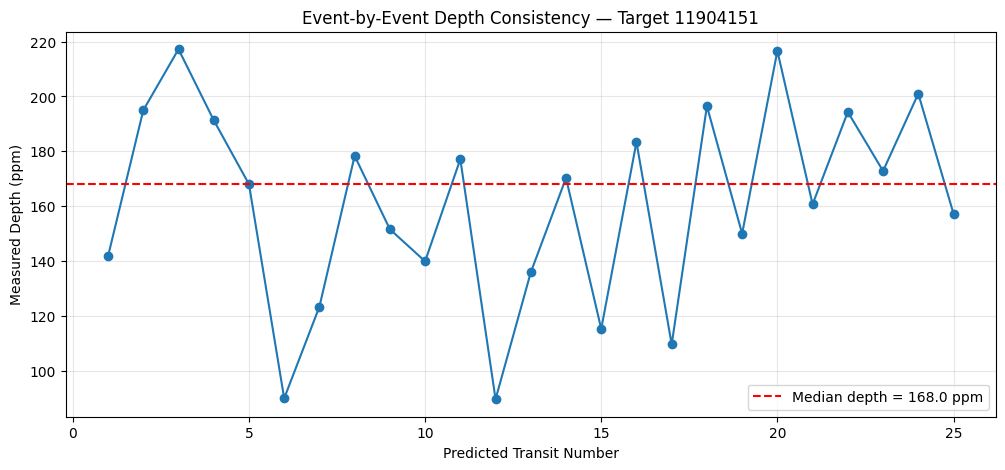

Depth standard deviation (ppm): 36.26186086650326
Depth coefficient of variation: 0.22511039168306315


In [58]:
# visualize individual measured depths
# Plot measured depth across predicted transit events

plt.figure(figsize=(12, 5))

plt.plot(
    event_depth_df["Transit_Number"],
    event_depth_df["Measured_Depth"] * 1e6,
    "o-",
    markersize=6
)

median_depth_ppm = (
    event_depth_df["Measured_Depth"].median() * 1e6
)

plt.axhline(
    median_depth_ppm,
    color="red",
    linestyle="--",
    label=f"Median depth = {median_depth_ppm:.1f} ppm"
)

plt.xlabel("Predicted Transit Number")
plt.ylabel("Measured Depth (ppm)")
plt.title("Event-by-Event Depth Consistency — Target 11904151")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

print(
    "Depth standard deviation (ppm):",
    event_depth_df["Measured_Depth"].std() * 1e6
)

print(
    "Depth coefficient of variation:",
    event_depth_df["Measured_Depth"].std()
    / event_depth_df["Measured_Depth"].mean()
)

In [60]:
print("Available columns:")
print(event_depth_df.columns.tolist())

display(event_depth_df.head())

Available columns:
['Transit_Number', 'Transit_Center_BKJD', 'In_Transit_Points', 'Out_Of_Transit_Points', 'Local_Baseline', 'Median_In_Transit_Flux', 'Measured_Depth']


,Transit_Number,Transit_Center_BKJD,In_Transit_Points,Out_Of_Transit_Points,Local_Baseline,Median_In_Transit_Flux,Measured_Depth
0,1,352.676705,3,12,1.000034,0.999892,0.000142
1,2,353.513989,4,12,1.000011,0.999816,0.000195
2,3,354.351272,4,12,0.999965,0.999748,0.000217
3,4,355.188556,4,12,1.000025,0.999834,0.000191
4,5,356.025840,4,12,1.000016,0.999848,0.000168


In [61]:
# Calculate approximate uncertainty for each transit

transit_uncertainties = []

for _, row in event_depth_df.iterrows():

    center = row["Transit_Center_BKJD"]

    # Same local window used in the previous event analysis
    local_mask = np.abs(bls_time - center) <= 2 * best_duration

    # In-transit observations
    in_mask = (
        local_mask &
        (np.abs(bls_time - center) <= best_duration / 2)
    )

    # Out-of-transit observations
    out_mask = local_mask & (~in_mask)

    in_flux = bls_flux[in_mask]
    out_flux = bls_flux[out_mask]

    n_in = len(in_flux)
    n_out = len(out_flux)

    if n_in < 2 or n_out < 2:
        transit_uncertainties.append(np.nan)
        continue

    sigma_in = np.std(in_flux, ddof=1)
    sigma_out = np.std(out_flux, ddof=1)

    depth_uncertainty = np.sqrt(
        (sigma_in**2 / n_in) +
        (sigma_out**2 / n_out)
    )

    transit_uncertainties.append(depth_uncertainty)


event_depth_df["Depth_Uncertainty"] = transit_uncertainties

event_depth_df["Depth_Significance"] = (
    event_depth_df["Measured_Depth"] /
    event_depth_df["Depth_Uncertainty"]
)

display(
    event_depth_df[
        [
            "Transit_Number",
            "Measured_Depth",
            "Depth_Uncertainty",
            "Depth_Significance"
        ]
    ].round(6)
)

,Transit_Number,Measured_Depth,Depth_Uncertainty,Depth_Significance
0,1,0.000142,0.000030,4.728666
1,2,0.000195,0.000050,3.863502
2,3,0.000217,0.000042,5.165698
3,4,0.000191,0.000018,10.856096
4,5,0.000168,0.000034,4.985755
5,6,0.000090,0.000053,1.694599
6,7,0.000123,0.000036,3.466528
7,8,0.000178,0.000030,5.934894
8,9,0.000152,0.000037,4.118772
9,10,0.000140,0.000041,3.414609


Odd transit count: 13
Even transit count: 12

Odd median depth (ppm): 151.61611073277737
Even median depth (ppm): 187.3529767007498

Absolute depth difference (ppm): 35.736865967972435


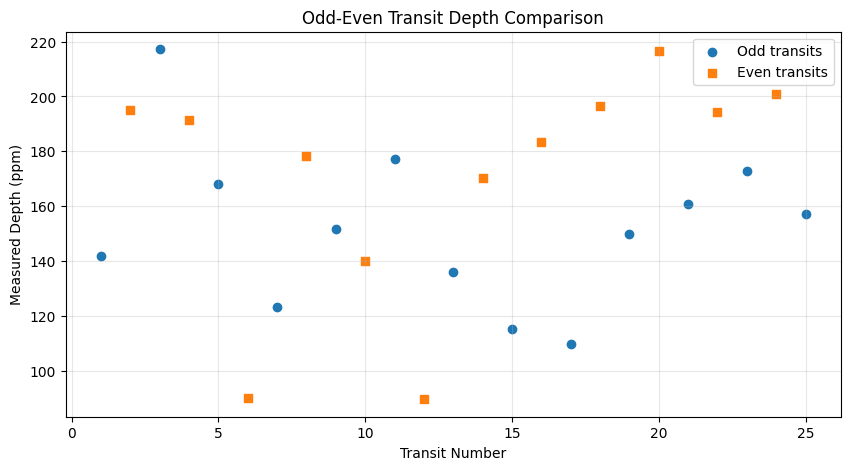

In [62]:
# Separate odd and even numbered transit events

odd_events = event_depth_df[
    event_depth_df["Transit_Number"] % 2 == 1
]

even_events = event_depth_df[
    event_depth_df["Transit_Number"] % 2 == 0
]

# Calculate median depths
odd_median = odd_events["Measured_Depth"].median()
even_median = even_events["Measured_Depth"].median()

# Calculate difference
depth_difference = abs(odd_median - even_median)

print("Odd transit count:", len(odd_events))
print("Even transit count:", len(even_events))

print("\nOdd median depth (ppm):", odd_median * 1e6)
print("Even median depth (ppm):", even_median * 1e6)

print("\nAbsolute depth difference (ppm):",
      depth_difference * 1e6)

# Visual comparison
plt.figure(figsize=(10, 5))

plt.scatter(
    odd_events["Transit_Number"],
    odd_events["Measured_Depth"] * 1e6,
    label="Odd transits",
    marker="o"
)

plt.scatter(
    even_events["Transit_Number"],
    even_events["Measured_Depth"] * 1e6,
    label="Even transits",
    marker="s"
)

plt.xlabel("Transit Number")
plt.ylabel("Measured Depth (ppm)")
plt.title("Odd-Even Transit Depth Comparison")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [63]:
# Bootstrap odd-even median depth difference

np.random.seed(42)

odd_depths = odd_events["Measured_Depth"].to_numpy()
even_depths = even_events["Measured_Depth"].to_numpy()

n_bootstrap = 10000
bootstrap_differences = []

for _ in range(n_bootstrap):

    odd_sample = np.random.choice(
        odd_depths,
        size=len(odd_depths),
        replace=True
    )

    even_sample = np.random.choice(
        even_depths,
        size=len(even_depths),
        replace=True
    )

    difference = (
        np.median(even_sample) -
        np.median(odd_sample)
    )

    bootstrap_differences.append(difference)

bootstrap_differences = np.array(bootstrap_differences)

ci_lower, ci_upper = np.percentile(
    bootstrap_differences,
    [2.5, 97.5]
)

observed_difference = np.median(even_depths) - np.median(odd_depths)

print("Observed even - odd difference (ppm):",
      observed_difference * 1e6)

print("Bootstrap 95% CI (ppm):",
      ci_lower * 1e6,
      "to",
      ci_upper * 1e6)

print("Fraction of bootstrap differences <= 0:",
      np.mean(bootstrap_differences <= 0))

Observed even - odd difference (ppm): 35.736865967972435
Bootstrap 95% CI (ppm): -2.1998681799528796 to 56.94488702334688
Fraction of bootstrap differences <= 0: 0.0282


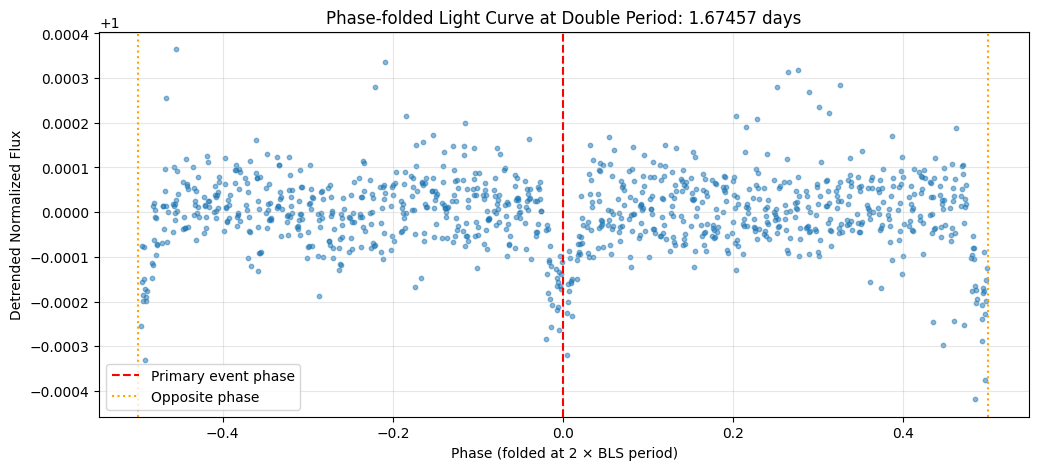

BLS period: 0.8372837283728374
Double period: 1.6745674567456748


In [64]:
# Compare phase-folded light curves at P and 2P

candidate_period = best_period
double_period = 2 * candidate_period

# Phase fold at twice the BLS period
phase_2p = (
    (bls_time - best_epoch + double_period / 2)
    % double_period
) / double_period - 0.5

plt.figure(figsize=(12, 5))

plt.scatter(
    phase_2p,
    bls_flux,
    s=10,
    alpha=0.5
)

plt.axvline(0, color="red", linestyle="--",
            label="Primary event phase")

plt.axvline(-0.5, color="orange", linestyle=":",
            label="Opposite phase")

plt.axvline(0.5, color="orange", linestyle=":")

plt.xlabel("Phase (folded at 2 × BLS period)")
plt.ylabel("Detrended Normalized Flux")
plt.title(
    f"Phase-folded Light Curve at Double Period: "
    f"{double_period:.5f} days"
)

plt.grid(alpha=0.3)
plt.legend()
plt.show()

print("BLS period:", candidate_period)
print("Double period:", double_period)

In [65]:
# Measure the two depths quantitatively
# Compare transit depths at phase 0 and phase 0.5

def calculate_phase_depth(center_phase):

    # Circular distance handles the phase boundary at -0.5 / +0.5
    phase_distance = (
        (phase_2p - center_phase + 0.5) % 1
    ) - 0.5

    # Transit region: half the estimated transit duration
    in_mask = (
        np.abs(phase_distance) <=
        best_duration / (2 * double_period)
    )

    # Local baseline: observations 1–2 transit durations
    # away from the event center
    out_mask = (
        (np.abs(phase_distance) >
         best_duration / double_period) &
        (np.abs(phase_distance) <=
         2 * best_duration / double_period)
    )

    in_flux = bls_flux[in_mask]
    out_flux = bls_flux[out_mask]

    depth = np.median(out_flux) - np.median(in_flux)

    return {
        "In_Points": len(in_flux),
        "Out_Points": len(out_flux),
        "Baseline_Flux": np.median(out_flux),
        "In_Transit_Flux": np.median(in_flux),
        "Depth_ppm": depth * 1e6
    }


primary_result = calculate_phase_depth(0.0)
opposite_result = calculate_phase_depth(0.5)

print("Event at phase 0:")
print(primary_result)

print("\nEvent at phase 0.5:")
print(opposite_result)

print("\nDepth difference (ppm):",
      abs(primary_result["Depth_ppm"] -
          opposite_result["Depth_ppm"]))

Event at phase 0:
{'In_Points': 50, 'Out_Points': 104, 'Baseline_Flux': np.float64(1.0000056036876348), 'In_Transit_Flux': np.float64(0.9998632192413424), 'Depth_ppm': np.float64(142.38444629244285)}

Event at phase 0.5:
{'In_Points': 48, 'Out_Points': 90, 'Baseline_Flux': np.float64(1.0000213898999584), 'In_Transit_Flux': np.float64(0.9998456050284793), 'Depth_ppm': np.float64(175.78487147906773)}

Depth difference (ppm): 33.40042518662489


,Test_Period_Days,Best_Duration_Hours,BLS_Power
0,0.837284,2.0,1.183448e-06
1,1.674567,2.0,5.715026e-07


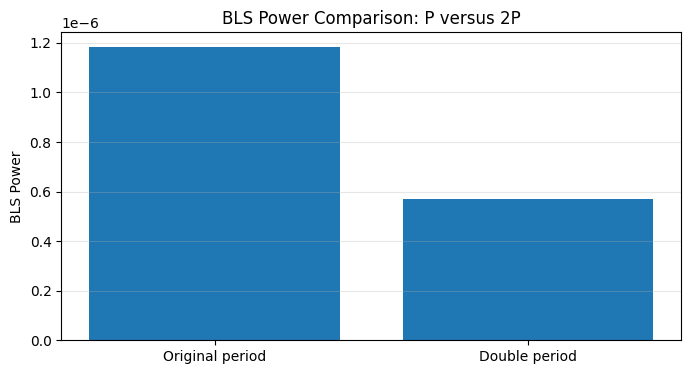

In [66]:
# Compare BLS power at the two candidate periods
# Compare BLS power at P and 2P

test_periods = np.array([
    best_period,
    2 * best_period
])

comparison_bls = bls.power(
    test_periods,
    durations
)

comparison_df = pd.DataFrame({
    "Test_Period_Days": comparison_bls.period,
    "Best_Duration_Hours": comparison_bls.duration * 24,
    "BLS_Power": comparison_bls.power
})

display(comparison_df)

plt.figure(figsize=(8, 4))

plt.bar(
    ["Original period", "Double period"],
    comparison_bls.power
)

plt.ylabel("BLS Power")
plt.title("BLS Power Comparison: P versus 2P")
plt.grid(axis="y", alpha=0.3)
plt.show()

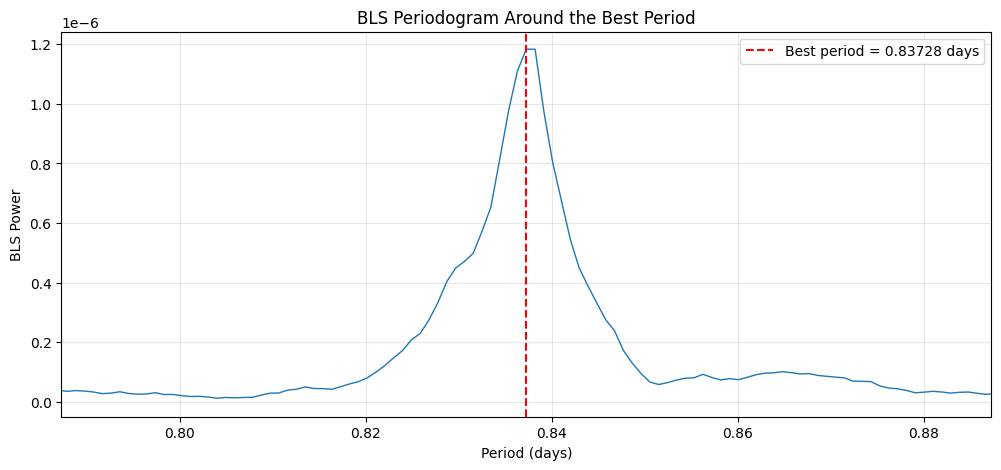

In [67]:
# Inspect the BLS periodogram around the strongest peak
# Plot BLS periodogram around the best period

plt.figure(figsize=(12, 5))

plt.plot(
    periodogram.period,
    periodogram.power,
    linewidth=1
)

plt.axvline(
    best_period,
    color="red",
    linestyle="--",
    label=f"Best period = {best_period:.5f} days"
)

plt.xlim(
    best_period - 0.05,
    best_period + 0.05
)

plt.xlabel("Period (days)")
plt.ylabel("BLS Power")
plt.title("BLS Periodogram Around the Best Period")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [68]:
# Step 4.1 — Build the 10-target quality-control summary
# Step 4.1: Target-level quality-control summary

quality_summary = []

# Additional quality flags selected for exclusion
BAD_QUALITY_MASK = 128 | 2048

for i, lc in enumerate(pilot_lcs):

    # Extract target information
    target_id = lc.meta.get("KEPLERID", f"Target_{i+1}")

    # Extract arrays
    time = np.ma.filled(np.ma.asarray(lc.time.value), np.nan)
    flux = np.ma.filled(np.ma.asarray(lc.flux.value), np.nan)
    quality = np.asarray(lc.quality, dtype=np.int64)

    # Identify valid observations
    finite_mask = np.isfinite(time) & np.isfinite(flux)

    # Identify observations containing selected quality flags
    bad_quality_mask = (quality & BAD_QUALITY_MASK) != 0

    # Apply the additional quality filter
    retained_mask = finite_mask & (~bad_quality_mask)

    # Calculate counts
    total = len(time)
    valid = np.sum(finite_mask)
    invalid = total - valid

    flag_128 = np.sum(finite_mask & ((quality & 128) != 0))
    flag_2048 = np.sum(finite_mask & ((quality & 2048) != 0))

    flagged_either = np.sum(finite_mask & bad_quality_mask)
    retained = np.sum(retained_mask)

    # Calculate time coverage
    if retained > 1:
        baseline_days = (
            np.max(time[retained_mask]) -
            np.min(time[retained_mask])
        )
    else:
        baseline_days = np.nan

    quality_summary.append({
        "Target_ID": target_id,
        "Total_Cadences": total,
        "Valid_Cadences": valid,
        "Invalid_Cadences": invalid,
        "Flag_128": flag_128,
        "Flag_2048": flag_2048,
        "Flagged_Either": flagged_either,
        "Retained_Cadences": retained,
        "Retention_Percent": retained / total * 100,
        "Baseline_Days": baseline_days
    })

quality_summary_df = pd.DataFrame(quality_summary)

display(
    quality_summary_df.round(3)
)

,Target_ID,Total_Cadences,Valid_Cadences,Invalid_Cadences,Flag_128,Flag_2048,Flagged_Either,Retained_Cadences,Retention_Percent,Baseline_Days
0,11904151,1011,1008,3,29,1,29,979,96.835,20.822
1,11904148,1011,1008,3,19,0,19,989,97.824,20.822
2,11904099,1011,1008,3,15,2,15,993,98.220,20.822
3,11904085,1011,1008,3,51,2,51,957,94.659,20.822
4,11904071,1011,1008,3,13,0,13,995,98.417,20.822
5,11904090,1011,1008,3,10,0,10,998,98.714,20.822
6,11904101,1011,1008,3,15,1,15,993,98.220,20.822
7,11904249,1011,1008,3,22,1,22,986,97.527,20.822
8,11904271,1011,1008,3,14,1,14,994,98.318,20.822
9,11904260,1011,1008,3,24,1,24,984,97.329,20.822


In [69]:
# Verify the filtered light curves
# Step 4.2: Create quality-controlled light curves

quality_controlled_data = {}

BAD_QUALITY_MASK = 128 | 2048

for i, lc in enumerate(pilot_lcs):

    target_id = int(lc.meta["KEPLERID"])

    time = np.ma.filled(
        np.ma.asarray(lc.time.value), np.nan
    )

    flux = np.ma.filled(
        np.ma.asarray(lc.flux.value), np.nan
    )

    quality = np.asarray(lc.quality, dtype=np.int64)

    # Finite observations
    finite_mask = np.isfinite(time) & np.isfinite(flux)

    # Additional quality filtering
    bad_mask = (quality & BAD_QUALITY_MASK) != 0

    keep_mask = finite_mask & (~bad_mask)

    # Store filtered arrays without changing original data
    quality_controlled_data[target_id] = {
        "time": time[keep_mask],
        "flux": flux[keep_mask],
        "quality": quality[keep_mask],
        "original_count": len(time),
        "valid_count": int(finite_mask.sum()),
        "retained_count": int(keep_mask.sum())
    }

print("Quality-controlled targets:",
      len(quality_controlled_data))

for target_id, data in quality_controlled_data.items():

    print(
        f"Target {target_id}: "
        f"{data['retained_count']} retained observations"
    )

Quality-controlled targets: 10
Target 11904151: 979 retained observations
Target 11904148: 989 retained observations
Target 11904099: 993 retained observations
Target 11904085: 957 retained observations
Target 11904071: 995 retained observations
Target 11904090: 998 retained observations
Target 11904101: 993 retained observations
Target 11904249: 986 retained observations
Target 11904271: 994 retained observations
Target 11904260: 984 retained observations


In [70]:
# Step 4.3: Normalize and detrend all quality-controlled targets

preprocessed_data = {}

for target_id, data in quality_controlled_data.items():

    # Create a LightCurve from quality-controlled observations
    lc_clean = lk.LightCurve(
        time=data["time"],
        flux=data["flux"]
    )

    # Normalize using median flux
    lc_normalized = lc_clean.normalize()

    # Detrend using a 51-cadence window
    lc_detrended = lc_normalized.flatten(
        window_length=51,
        polyorder=2
    )

    # Extract arrays
    time = np.asarray(lc_detrended.time.value)
    normalized_flux = np.asarray(lc_normalized.flux.value)
    detrended_flux = np.asarray(lc_detrended.flux.value)

    # Store results
    preprocessed_data[target_id] = {
        "time": time,
        "normalized_flux": normalized_flux,
        "detrended_flux": detrended_flux,
        "observation_count": len(time)
    }

    # Robust scatter estimate
    median_flux = np.median(detrended_flux)

    mad_scatter = 1.4826 * np.median(
        np.abs(detrended_flux - median_flux)
    )

    print(
        f"Target {target_id} | "
        f"Observations: {len(time)} | "
        f"Median: {median_flux:.6f} | "
        f"MAD scatter: {mad_scatter:.6f}"
    )

print("\nTotal preprocessed targets:", len(preprocessed_data))

Target 11904151 | Observations: 979 | Median: 1.000004 | MAD scatter: 0.000072
Target 11904148 | Observations: 989 | Median: 1.000010 | MAD scatter: 0.000472
Target 11904099 | Observations: 993 | Median: 1.000001 | MAD scatter: 0.000223
Target 11904085 | Observations: 957 | Median: 0.999999 | MAD scatter: 0.000097
Target 11904071 | Observations: 995 | Median: 0.999996 | MAD scatter: 0.000192
Target 11904090 | Observations: 998 | Median: 0.999999 | MAD scatter: 0.000284
Target 11904101 | Observations: 993 | Median: 0.999998 | MAD scatter: 0.000397
Target 11904249 | Observations: 986 | Median: 0.999999 | MAD scatter: 0.000292
Target 11904271 | Observations: 994 | Median: 0.999993 | MAD scatter: 0.000279
Target 11904260 | Observations: 984 | Median: 0.999963 | MAD scatter: 0.000493

Total preprocessed targets: 10


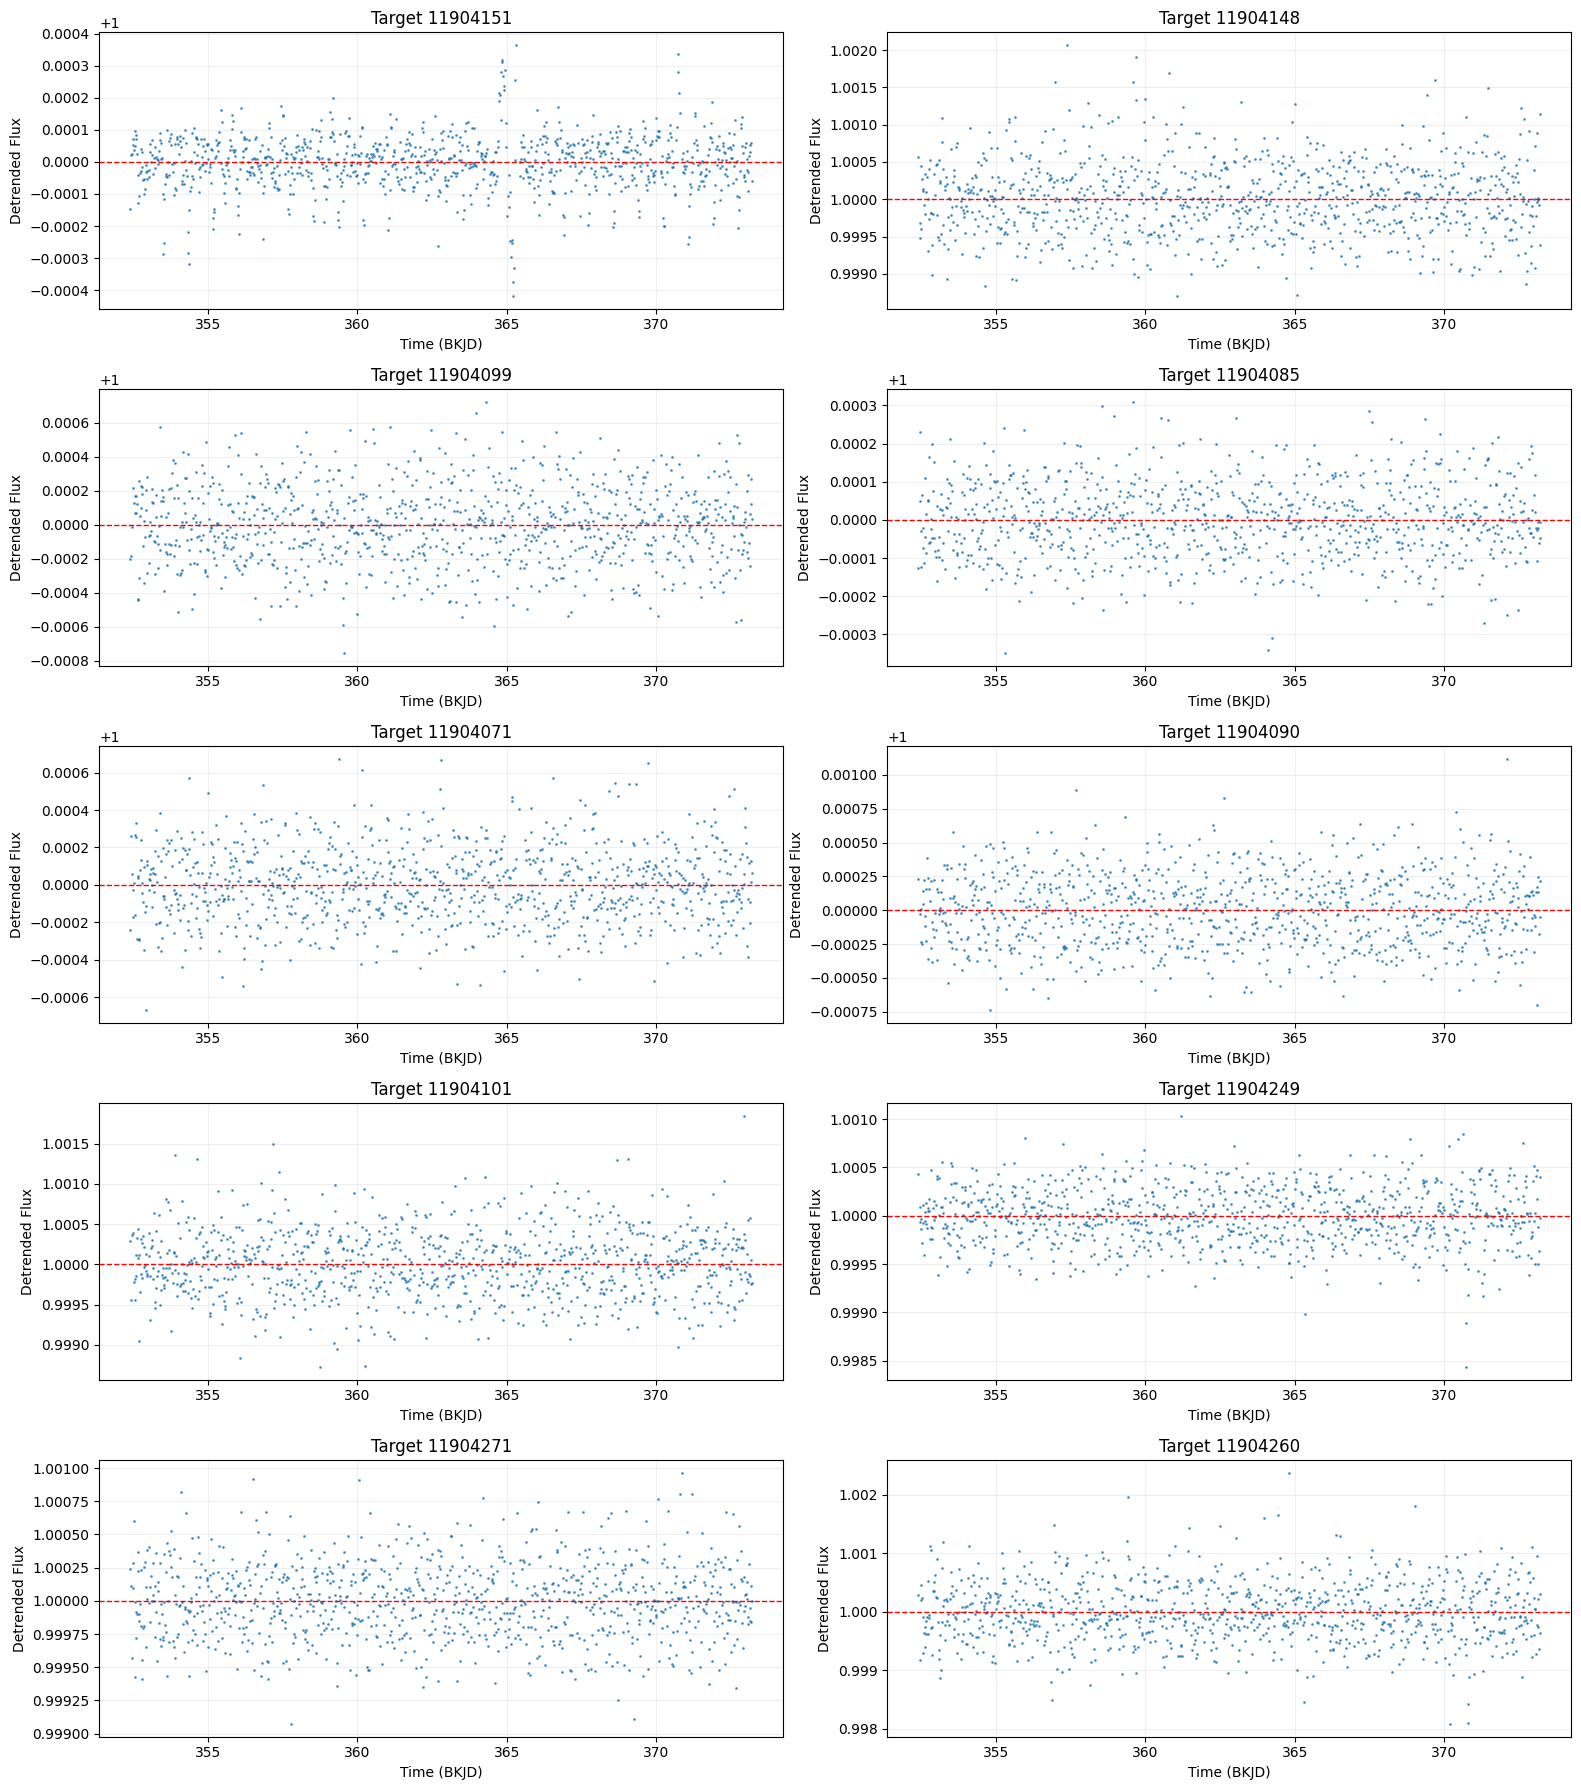

In [71]:
# Step 4.4: Visual inspection of all detrended targets

fig, axes = plt.subplots(
    5, 2,
    figsize=(16, 18)
)

axes = axes.flatten()

for ax, (target_id, data) in zip(
    axes, preprocessed_data.items()
):

    ax.plot(
        data["time"],
        data["detrended_flux"],
        ".",
        markersize=2,
        alpha=0.7
    )

    ax.axhline(
        1.0,
        color="red",
        linestyle="--",
        linewidth=1
    )

    ax.set_title(f"Target {target_id}")
    ax.set_xlabel("Time (BKJD)")
    ax.set_ylabel("Detrended Flux")
    ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

In [72]:
# Step 4.5: Robust outlier analysis

outlier_summary = []

for target_id, data in preprocessed_data.items():

    flux = data["detrended_flux"]

    median_flux = np.median(flux)

    mad = np.median(
        np.abs(flux - median_flux)
    )

    robust_sigma = 1.4826 * mad

    # Robust Z-score
    if robust_sigma > 0:
        robust_z = (
            flux - median_flux
        ) / robust_sigma

        outlier_mask = np.abs(robust_z) > 5
    else:
        outlier_mask = np.zeros(
            len(flux), dtype=bool
        )

    outlier_count = np.sum(outlier_mask)

    outlier_percentage = (
        outlier_count / len(flux)
    ) * 100

    outlier_summary.append({
        "Target_ID": target_id,
        "MAD_Scatter": mad,
        "Robust_Sigma": robust_sigma,
        "Outlier_Count": outlier_count,
        "Outlier_Percentage": outlier_percentage
    })

outlier_summary_df = pd.DataFrame(outlier_summary)

display(outlier_summary_df.round(6))

,Target_ID,MAD_Scatter,Robust_Sigma,Outlier_Count,Outlier_Percentage
0,11904151,0.000048,0.000072,3,0.306435
1,11904148,0.000319,0.000472,0,0.000000
2,11904099,0.000150,0.000223,0,0.000000
3,11904085,0.000065,0.000097,0,0.000000
4,11904071,0.000129,0.000192,0,0.000000
5,11904090,0.000192,0.000284,0,0.000000
6,11904101,0.000267,0.000397,0,0.000000
7,11904249,0.000197,0.000292,1,0.101420
8,11904271,0.000188,0.000279,0,0.000000
9,11904260,0.000333,0.000493,0,0.000000


In [73]:
# Step 4.6: Inspect individual robust outliers

outlier_details = []

for target_id, data in preprocessed_data.items():

    time = data["time"]
    flux = data["detrended_flux"]

    median_flux = np.median(flux)
    mad = np.median(np.abs(flux - median_flux))
    robust_sigma = 1.4826 * mad

    if robust_sigma == 0:
        continue

    robust_z = (flux - median_flux) / robust_sigma

    outlier_indices = np.where(
        np.abs(robust_z) > 5
    )[0]

    for idx in outlier_indices:

        outlier_details.append({
            "Target_ID": target_id,
            "Time_BKJD": time[idx],
            "Detrended_Flux": flux[idx],
            "Robust_Z": robust_z[idx],
            "Direction": (
                "Negative" if robust_z[idx] < 0
                else "Positive"
            )
        })

outlier_details_df = pd.DataFrame(outlier_details)

display(outlier_details_df.round(7))

,Target_ID,Time_BKJD,Detrended_Flux,Robust_Z,Direction
0,11904151,365.209177,0.999581,-5.904526,Negative
1,11904151,365.229610,0.999625,-5.291864,Negative
2,11904151,365.311343,1.000365,5.039035,Positive
3,11904249,370.746610,0.998433,-5.358487,Negative


In [74]:
# Step 4.7: Inspect local context around outliers

outlier_context = []

for _, row in outlier_details_df.iterrows():

    target_id = int(row["Target_ID"])
    event_time = row["Time_BKJD"]

    data = quality_controlled_data[target_id]

    time = data["time"]
    flux = data["flux"]
    quality = data["quality"]

    # Find nearest observation
    center_idx = np.argmin(np.abs(time - event_time))

    # Select 5 observations before and after
    start = max(0, center_idx - 5)
    end = min(len(time), center_idx + 6)

    print(f"\nTarget: {target_id}")
    print(f"Outlier time: {event_time:.6f} BKJD")

    local_df = pd.DataFrame({
        "Time_BKJD": time[start:end],
        "Raw_Flux": flux[start:end],
        "Quality_Flag": quality[start:end]
    })

    display(local_df.round(6))

    outlier_context.append(local_df.assign(Target_ID=target_id))



Target: 11904151
Outlier time: 365.209177 BKJD


,Time_BKJD,Raw_Flux,Quality_Flag
0,365.107010,574860.6250,0
1,365.127443,574766.3125,0
2,365.147877,574729.8125,0
3,365.168310,574753.6875,0
4,365.188743,574741.7500,0
5,365.209177,574638.8125,16
6,365.229610,574656.9375,16
7,365.250043,574675.7500,16
8,365.270476,574861.1875,16
9,365.290910,575028.5000,16



Target: 11904151
Outlier time: 365.229610 BKJD


,Time_BKJD,Raw_Flux,Quality_Flag
0,365.127443,574766.3125,0
1,365.147877,574729.8125,0
2,365.168310,574753.6875,0
3,365.188743,574741.7500,0
4,365.209177,574638.8125,16
5,365.229610,574656.9375,16
6,365.250043,574675.7500,16
7,365.270476,574861.1875,16
8,365.290910,575028.5000,16
9,365.311343,575114.6250,16



Target: 11904151
Outlier time: 365.311343 BKJD


,Time_BKJD,Raw_Flux,Quality_Flag
0,365.209177,574638.8125,16
1,365.229610,574656.9375,16
2,365.250043,574675.7500,16
3,365.270476,574861.1875,16
4,365.290910,575028.5000,16
5,365.311343,575114.6250,16
6,365.433943,575044.5625,16
7,365.454376,575012.6875,16
8,365.474809,575034.1250,0
9,365.495243,575058.4375,0



Target: 11904249
Outlier time: 370.746610 BKJD


,Time_BKJD,Raw_Flux,Quality_Flag
0,370.644443,26528.017578,0
1,370.664877,26530.480469,8208
2,370.685310,26528.388672,16
3,370.705744,26523.492188,8208
4,370.726177,26507.621094,16
5,370.746610,26495.611328,8208
6,370.787477,26515.900391,16
7,370.807910,26524.154297,16
8,370.828344,26532.302734,16
9,370.848777,26540.919922,16


In [75]:
# Step 4.8: Compare quality-filtering policies

OLD_MASK = 128 | 2048
EXPANDED_MASK = 128 | 2048 | 8192

mask_comparison = []

for i, lc in enumerate(pilot_lcs):

    target_id = int(lc.meta["KEPLERID"])

    time = np.ma.filled(
        np.ma.asarray(lc.time.value), np.nan
    )

    flux = np.ma.filled(
        np.ma.asarray(lc.flux.value), np.nan
    )

    quality = np.asarray(lc.quality, dtype=np.int64)

    finite = np.isfinite(time) & np.isfinite(flux)

    old_bad = (quality & OLD_MASK) != 0
    expanded_bad = (quality & EXPANDED_MASK) != 0

    mask_comparison.append({
        "Target_ID": target_id,
        "Valid": int(finite.sum()),
        "Old_Excluded": int((finite & old_bad).sum()),
        "Expanded_Excluded": int((finite & expanded_bad).sum()),
        "Additional_Excluded": int(
            (finite & expanded_bad & ~old_bad).sum()
        ),
        "Expanded_Retained": int(
            (finite & ~expanded_bad).sum()
        )
    })

mask_comparison_df = pd.DataFrame(mask_comparison)

display(mask_comparison_df)

,Target_ID,Valid,Old_Excluded,Expanded_Excluded,Additional_Excluded,Expanded_Retained
0,11904151,1008,29,67,38,941
1,11904148,1008,19,43,24,965
2,11904099,1008,15,46,31,962
3,11904085,1008,51,98,47,910
4,11904071,1008,13,39,26,969
5,11904090,1008,10,37,27,971
6,11904101,1008,15,37,22,971
7,11904249,1008,22,56,34,952
8,11904271,1008,14,38,24,970
9,11904260,1008,24,52,28,956


In [76]:
# Step 4.9: Create two quality-control versions

quality_versions = {
    "primary": {},
    "expanded": {}
}

PRIMARY_MASK = 128 | 2048
EXPANDED_MASK = 128 | 2048 | 8192

for lc in pilot_lcs:

    target_id = int(lc.meta["KEPLERID"])

    time = np.ma.filled(
        np.ma.asarray(lc.time.value), np.nan
    )

    flux = np.ma.filled(
        np.ma.asarray(lc.flux.value), np.nan
    )

    quality = np.asarray(lc.quality, dtype=np.int64)

    finite = np.isfinite(time) & np.isfinite(flux)

    primary_keep = finite & (
        (quality & PRIMARY_MASK) == 0
    )

    expanded_keep = finite & (
        (quality & EXPANDED_MASK) == 0
    )

    quality_versions["primary"][target_id] = {
        "time": time[primary_keep],
        "flux": flux[primary_keep],
        "quality": quality[primary_keep]
    }

    quality_versions["expanded"][target_id] = {
        "time": time[expanded_keep],
        "flux": flux[expanded_keep],
        "quality": quality[expanded_keep]
    }

print("Primary targets:", len(quality_versions["primary"]))
print("Expanded targets:", len(quality_versions["expanded"]))

for target_id in quality_versions["primary"]:

    primary_n = len(
        quality_versions["primary"][target_id]["time"]
    )

    expanded_n = len(
        quality_versions["expanded"][target_id]["time"]
    )

    print(
        f"{target_id}: "
        f"Primary={primary_n}, "
        f"Expanded={expanded_n}"
    )

Primary targets: 10
Expanded targets: 10
11904151: Primary=979, Expanded=941
11904148: Primary=989, Expanded=965
11904099: Primary=993, Expanded=962
11904085: Primary=957, Expanded=910
11904071: Primary=995, Expanded=969
11904090: Primary=998, Expanded=971
11904101: Primary=993, Expanded=971
11904249: Primary=986, Expanded=952
11904271: Primary=994, Expanded=970
11904260: Primary=984, Expanded=956


In [77]:
# Step 4.10: Normalize and detrend both QC versions

preprocessed_versions = {
    "primary": {},
    "expanded": {}
}

for version in ["primary", "expanded"]:

    print(f"\nProcessing {version.upper()} version")

    for target_id, data in quality_versions[version].items():

        lc = lk.LightCurve(
            time=data["time"],
            flux=data["flux"]
        )

        # Normalize
        lc_normalized = lc.normalize()

        # Detrend using identical settings
        lc_detrended = lc_normalized.flatten(
            window_length=51,
            polyorder=2
        )

        time = np.asarray(lc_detrended.time.value)
        normalized_flux = np.asarray(
            lc_normalized.flux.value
        )
        detrended_flux = np.asarray(
            lc_detrended.flux.value
        )

        preprocessed_versions[version][target_id] = {
            "time": time,
            "normalized_flux": normalized_flux,
            "detrended_flux": detrended_flux
        }

        median_flux = np.median(detrended_flux)

        mad_scatter = 1.4826 * np.median(
            np.abs(detrended_flux - median_flux)
        )

        print(
            f"{target_id}: "
            f"N={len(time)}, "
            f"Median={median_flux:.6f}, "
            f"MAD={mad_scatter:.6f}"
        )

print("\nBoth preprocessing versions completed.")


Processing PRIMARY version
11904151: N=979, Median=1.000004, MAD=0.000072
11904148: N=989, Median=1.000010, MAD=0.000472
11904099: N=993, Median=1.000001, MAD=0.000223
11904085: N=957, Median=0.999999, MAD=0.000097
11904071: N=995, Median=0.999996, MAD=0.000192
11904090: N=998, Median=0.999999, MAD=0.000284
11904101: N=993, Median=0.999998, MAD=0.000397
11904249: N=986, Median=0.999999, MAD=0.000292
11904271: N=994, Median=0.999993, MAD=0.000279
11904260: N=984, Median=0.999963, MAD=0.000493

Processing EXPANDED version
11904151: N=941, Median=1.000003, MAD=0.000070
11904148: N=965, Median=1.000007, MAD=0.000464
11904099: N=962, Median=0.999999, MAD=0.000225
11904085: N=910, Median=0.999998, MAD=0.000098
11904071: N=969, Median=0.999997, MAD=0.000194
11904090: N=971, Median=1.000001, MAD=0.000285
11904101: N=971, Median=1.000005, MAD=0.000401
11904249: N=952, Median=0.999996, MAD=0.000289
11904271: N=970, Median=0.999997, MAD=0.000274
11904260: N=956, Median=0.999963, MAD=0.000497

Bo

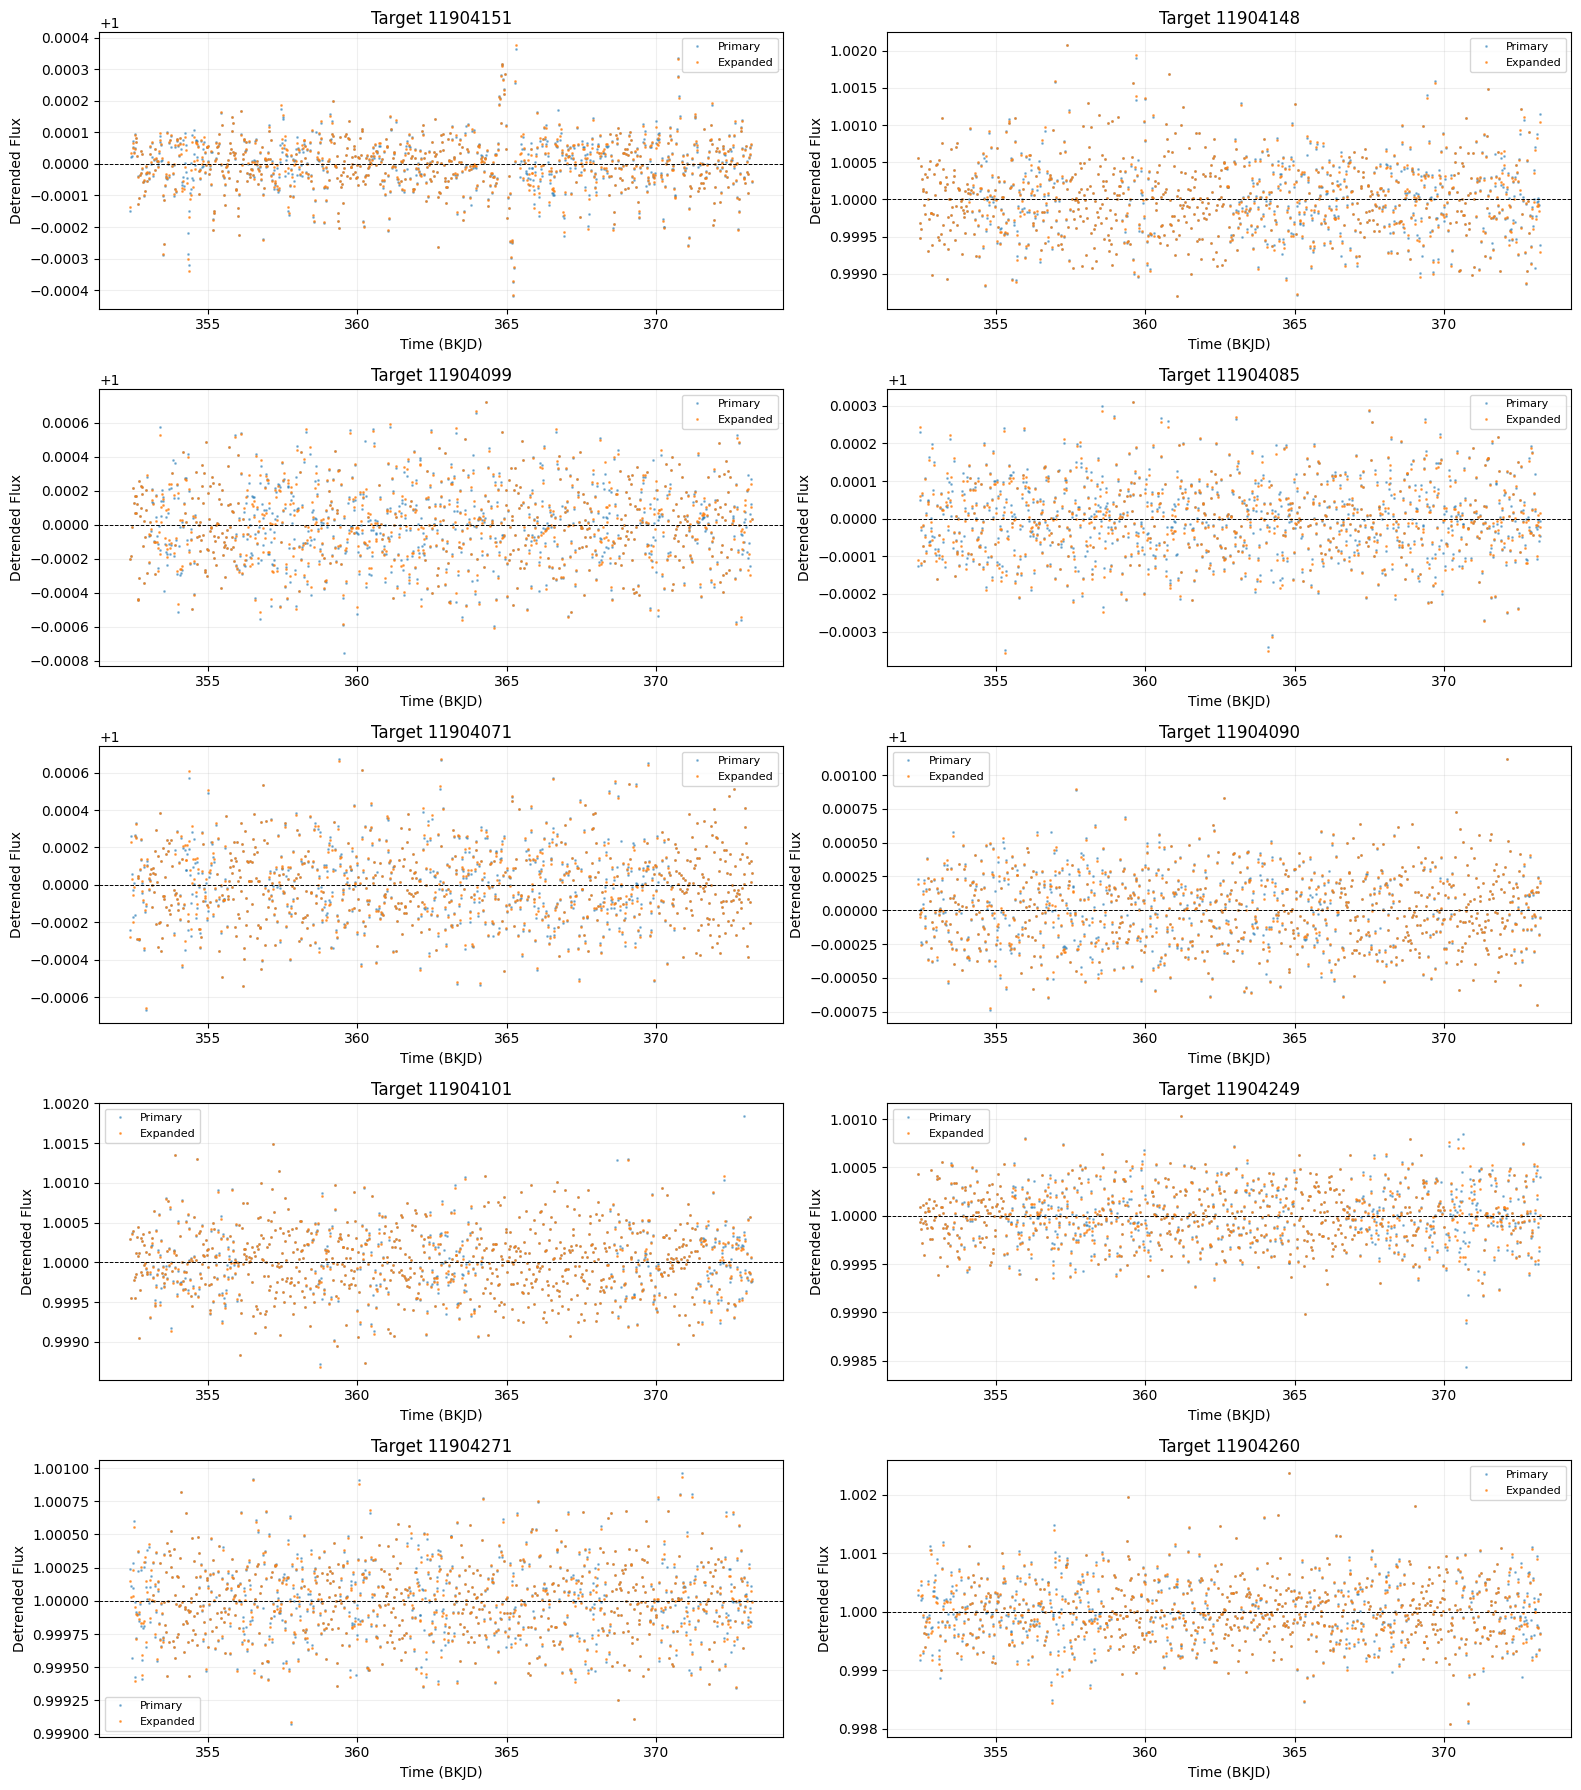

In [78]:
# Step 4.11: Visual comparison of primary and expanded filtering

fig, axes = plt.subplots(
    5, 2,
    figsize=(16, 18)
)

axes = axes.flatten()

for ax, target_id in zip(
    axes, preprocessed_versions["primary"].keys()
):

    primary = preprocessed_versions["primary"][target_id]
    expanded = preprocessed_versions["expanded"][target_id]

    ax.plot(
        primary["time"],
        primary["detrended_flux"],
        ".",
        markersize=2,
        alpha=0.45,
        label="Primary"
    )

    ax.plot(
        expanded["time"],
        expanded["detrended_flux"],
        ".",
        markersize=2,
        alpha=0.65,
        label="Expanded"
    )

    ax.axhline(1.0, color="black", linestyle="--", linewidth=0.7)

    ax.set_title(f"Target {target_id}")
    ax.set_xlabel("Time (BKJD)")
    ax.set_ylabel("Detrended Flux")
    ax.legend(fontsize=8)
    ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

In [79]:
# Step 4.12: Compare time sampling between QC versions

sampling_comparison = []

for target_id in quality_versions["primary"]:

    primary_time = np.sort(
        quality_versions["primary"][target_id]["time"]
    )

    expanded_time = np.sort(
        quality_versions["expanded"][target_id]["time"]
    )

    # Cadence differences in days
    primary_gaps = np.diff(primary_time)
    expanded_gaps = np.diff(expanded_time)

    # Expected Kepler long-cadence interval
    expected_cadence = 1800 / 86400

    sampling_comparison.append({
        "Target_ID": target_id,
        "Primary_N": len(primary_time),
        "Expanded_N": len(expanded_time),
        "Primary_Median_Gap_Hours":
            np.median(primary_gaps) * 24,
        "Expanded_Median_Gap_Hours":
            np.median(expanded_gaps) * 24,
        "Primary_Gaps_Above_1h":
            np.sum(primary_gaps > 1/24),
        "Expanded_Gaps_Above_1h":
            np.sum(expanded_gaps > 1/24),
        "Expected_Cadence_Minutes":
            expected_cadence * 24 * 60
    })

sampling_comparison_df = pd.DataFrame(sampling_comparison)

display(sampling_comparison_df.round(4))

,Target_ID,Primary_N,Expanded_N,Primary_Median_Gap_Hours,Expanded_Median_Gap_Hours,Primary_Gaps_Above_1h,Expanded_Gaps_Above_1h,Expected_Cadence_Minutes
0,11904151,979,941,0.4904,0.4904,2,10,30.0
1,11904148,989,965,0.4904,0.4904,0,1,30.0
2,11904099,993,962,0.4904,0.4904,0,2,30.0
3,11904085,957,910,0.4904,0.4904,5,9,30.0
4,11904071,995,969,0.4904,0.4904,0,0,30.0
5,11904090,998,971,0.4904,0.4904,0,3,30.0
6,11904101,993,971,0.4904,0.4904,0,0,30.0
7,11904249,986,952,0.4904,0.4904,0,3,30.0
8,11904271,994,970,0.4904,0.4904,0,1,30.0
9,11904260,984,956,0.4904,0.4904,1,3,30.0


In [80]:
# Step 4.13: Verify preprocessing inputs

print("Number of targets:", len(preprocessed_versions["primary"]))

for target_id in preprocessed_versions["primary"]:

    primary = preprocessed_versions["primary"][target_id]
    expanded = preprocessed_versions["expanded"][target_id]

    print(
        f"{target_id}: "
        f"Primary time={len(primary['time'])}, "
        f"Primary flux={len(primary['normalized_flux'])}, "
        f"Expanded time={len(expanded['time'])}, "
        f"Expanded flux={len(expanded['normalized_flux'])}"
    )

    assert len(primary["time"]) == len(primary["normalized_flux"])
    assert len(primary["time"]) == len(primary["detrended_flux"])

    assert len(expanded["time"]) == len(expanded["normalized_flux"])
    assert len(expanded["time"]) == len(expanded["detrended_flux"])

print("All arrays passed the length checks.")

Number of targets: 10
11904151: Primary time=979, Primary flux=979, Expanded time=941, Expanded flux=941
11904148: Primary time=989, Primary flux=989, Expanded time=965, Expanded flux=965
11904099: Primary time=993, Primary flux=993, Expanded time=962, Expanded flux=962
11904085: Primary time=957, Primary flux=957, Expanded time=910, Expanded flux=910
11904071: Primary time=995, Primary flux=995, Expanded time=969, Expanded flux=969
11904090: Primary time=998, Primary flux=998, Expanded time=971, Expanded flux=971
11904101: Primary time=993, Primary flux=993, Expanded time=971, Expanded flux=971
11904249: Primary time=986, Primary flux=986, Expanded time=952, Expanded flux=952
11904271: Primary time=994, Primary flux=994, Expanded time=970, Expanded flux=970
11904260: Primary time=984, Primary flux=984, Expanded time=956, Expanded flux=956
All arrays passed the length checks.


In [81]:
# Step 4.14: Single transit injection-recovery test

target_id = 11904151

data = quality_versions["primary"][target_id]

time = data["time"]
flux = data["flux"]

# Normalize original flux
original_lc = lk.LightCurve(time=time, flux=flux)
original_normalized = original_lc.normalize()

# Define artificial transit
injection_depth = 0.001       # 1000 ppm
injection_duration = 3 / 24   # 3 hours in days

# Choose the middle of the observation baseline
injection_center = (time.min() + time.max()) / 2

# Create box-shaped transit model
in_transit = (
    np.abs(time - injection_center)
    <= injection_duration / 2
)

print("Target ID:", target_id)
print("Injection center (BKJD):", injection_center)
print("Duration (hours):", injection_duration * 24)
print("Injected depth (ppm):", injection_depth * 1e6)
print("In-transit observations:", in_transit.sum())

# Inject transit into normalized flux
injected_flux = original_normalized.flux.value.copy()

injected_flux[in_transit] *= (1 - injection_depth)

# Detrend original and injected curves independently
original_detrended = original_normalized.flatten(
    window_length=51,
    polyorder=2
)

injected_lc = lk.LightCurve(
    time=time,
    flux=injected_flux
)

injected_detrended = injected_lc.flatten(
    window_length=51,
    polyorder=2
)

# Compare detrended curves
original_values = np.asarray(original_detrended.flux.value)
injected_values = np.asarray(injected_detrended.flux.value)

# Differential signal: positive values indicate recovered dimming
difference = original_values - injected_values

# Estimate recovered depth using local baseline
local_window = np.abs(time - injection_center) <= 2 * injection_duration

local_in = local_window & in_transit
local_out = local_window & (~in_transit)

recovered_depth = (
    np.median(difference[local_in])
    - np.median(difference[local_out])
)

recovery_percent = recovered_depth / injection_depth * 100

print("\n--- Recovery Results ---")
print("Injected depth (ppm):", injection_depth * 1e6)
print("Recovered depth (ppm):", recovered_depth * 1e6)
print("Recovery percentage:", recovery_percent)


Target ID: 11904151
Injection center (BKJD): 362.80829214811456
Duration (hours): 3.0
Injected depth (ppm): 1000.0
In-transit observations: 6

--- Recovery Results ---
Injected depth (ppm): 1000.0
Recovered depth (ppm): 966.2672787207338
Recovery percentage: 96.62672787207339


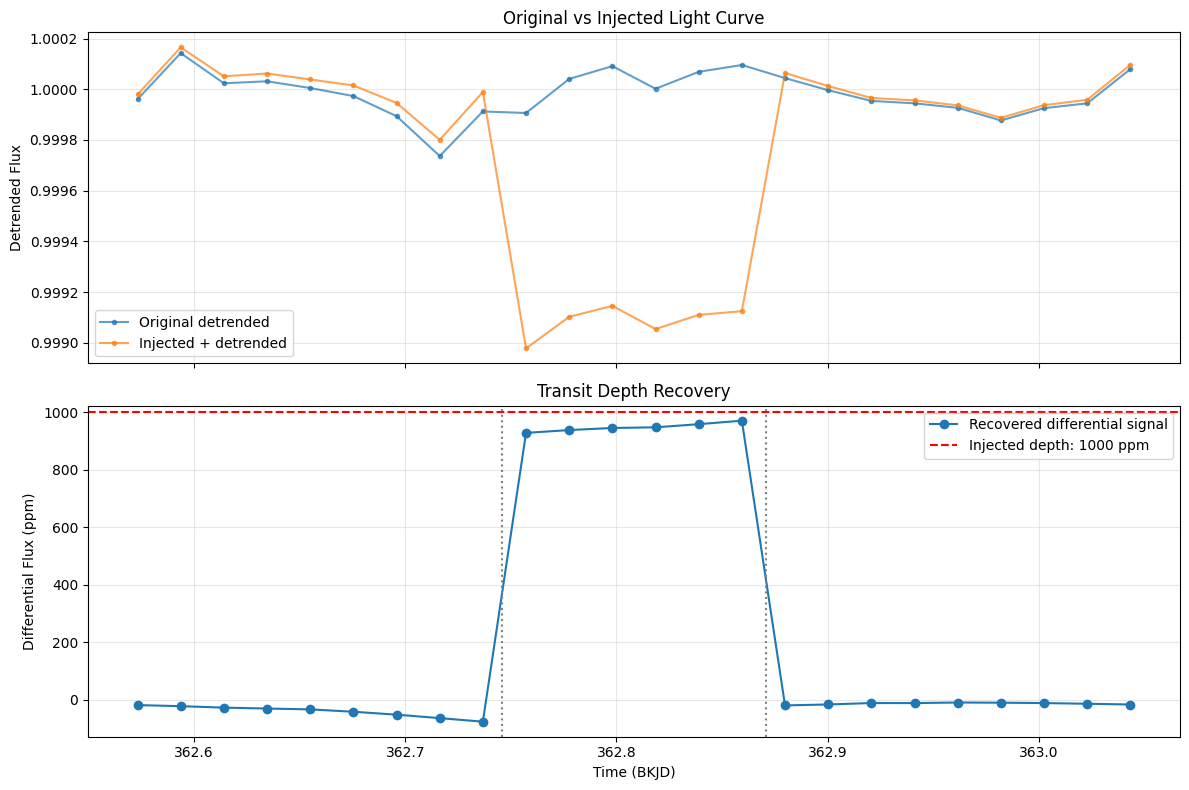

In [82]:
# Step 4.15: Visual inspection of injection recovery

plot_window = 0.25  # days on either side of injection center

local_plot = (
    np.abs(time - injection_center) <= plot_window
)

fig, axes = plt.subplots(
    2, 1,
    figsize=(12, 8),
    sharex=True
)

# Original and injected detrended curves
axes[0].plot(
    time[local_plot],
    original_values[local_plot],
    ".-",
    label="Original detrended",
    alpha=0.7
)

axes[0].plot(
    time[local_plot],
    injected_values[local_plot],
    ".-",
    label="Injected + detrended",
    alpha=0.7
)

axes[0].set_ylabel("Detrended Flux")
axes[0].set_title("Original vs Injected Light Curve")
axes[0].legend()
axes[0].grid(alpha=0.3)

# Differential signal
axes[1].plot(
    time[local_plot],
    difference[local_plot] * 1e6,
    "o-",
    label="Recovered differential signal"
)

axes[1].axhline(
    injection_depth * 1e6,
    color="red",
    linestyle="--",
    label="Injected depth: 1000 ppm"
)

axes[1].axvline(
    injection_center - injection_duration / 2,
    color="gray",
    linestyle=":"
)

axes[1].axvline(
    injection_center + injection_duration / 2,
    color="gray",
    linestyle=":"
)

axes[1].set_xlabel("Time (BKJD)")
axes[1].set_ylabel("Differential Flux (ppm)")
axes[1].set_title("Transit Depth Recovery")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [83]:
# Step 4.16: Repeat injection at multiple locations

target_id = 11904151

data = quality_versions["primary"][target_id]
time = data["time"]
flux = data["flux"]

original_lc = lk.LightCurve(time=time, flux=flux)
original_normalized = original_lc.normalize()

original_detrended = original_normalized.flatten(
    window_length=51,
    polyorder=2
)

original_values = np.asarray(original_detrended.flux.value)

injection_depth = 0.001
injection_duration = 3 / 24

# Select eight centers away from the data boundaries
centers = np.linspace(
    time.min() + 0.15 * (time.max() - time.min()),
    time.max() - 0.15 * (time.max() - time.min()),
    8
)

results = []

for center in centers:

    in_transit = (
        np.abs(time - center) <= injection_duration / 2
    )

    injected_flux = original_normalized.flux.value.copy()
    injected_flux[in_transit] *= (1 - injection_depth)

    injected_lc = lk.LightCurve(
        time=time,
        flux=injected_flux
    )

    injected_detrended = injected_lc.flatten(
        window_length=51,
        polyorder=2
    )

    injected_values = np.asarray(
        injected_detrended.flux.value
    )

    difference = original_values - injected_values

    local_window = (
        np.abs(time - center) <= 2 * injection_duration
    )

    local_in = local_window & in_transit
    local_out = local_window & (~in_transit)

    if local_in.sum() < 3 or local_out.sum() < 3:
        continue

    recovered_depth = (
        np.median(difference[local_in])
        - np.median(difference[local_out])
    )

    recovery_percent = (
        recovered_depth / injection_depth
    ) * 100

    results.append({
        "Injection_Center": center,
        "In_Transit_Points": in_transit.sum(),
        "Recovered_Depth_ppm": recovered_depth * 1e6,
        "Recovery_Percent": recovery_percent
    })

recovery_df = pd.DataFrame(results)

display(recovery_df.round(3))

print("\n--- Overall Recovery Summary ---")
print("Successful injections:", len(recovery_df))
print("Mean recovery (%):", recovery_df["Recovery_Percent"].mean())
print("Median recovery (%):", recovery_df["Recovery_Percent"].median())
print("Standard deviation (%):", recovery_df["Recovery_Percent"].std())
print("Minimum recovery (%):", recovery_df["Recovery_Percent"].min())
print("Maximum recovery (%):", recovery_df["Recovery_Percent"].max())

,Injection_Center,In_Transit_Points,Recovered_Depth_ppm,Recovery_Percent
0,355.521,6,980.830,98.083
1,357.603,6,996.849,99.685
2,359.685,6,1011.822,101.182
3,361.767,6,1034.641,103.464
4,363.849,6,949.047,94.905
5,365.932,6,1027.644,102.764
6,368.014,6,1018.708,101.871
7,370.096,5,1024.225,102.423



--- Overall Recovery Summary ---
Successful injections: 8
Mean recovery (%): 100.54706475035383
Median recovery (%): 101.52647296308714
Standard deviation (%): 2.872267177114504
Minimum recovery (%): 94.90472903253
Maximum recovery (%): 103.46410501478331


In [84]:
# Step 4.17: Injection-recovery across all 10 targets

injection_depth = 0.001
injection_duration = 3 / 24

multi_target_results = []

for target_id, data in quality_versions["primary"].items():

    time = data["time"]
    flux = data["flux"]

    original_lc = lk.LightCurve(time=time, flux=flux)
    original_normalized = original_lc.normalize()

    original_detrended = original_normalized.flatten(
        window_length=51,
        polyorder=2
    )

    original_values = np.asarray(
        original_detrended.flux.value
    )

    # Four injection centers per target
    baseline = time.max() - time.min()

    centers = np.linspace(
        time.min() + 0.2 * baseline,
        time.max() - 0.2 * baseline,
        4
    )

    for center in centers:

        in_transit = (
            np.abs(time - center)
            <= injection_duration / 2
        )

        local_window = (
            np.abs(time - center)
            <= 2 * injection_duration
        )

        local_in = local_window & in_transit
        local_out = local_window & (~in_transit)

        if in_transit.sum() < 3 or local_out.sum() < 3:
            continue

        injected_flux = original_normalized.flux.value.copy()

        injected_flux[in_transit] *= (
            1 - injection_depth
        )

        injected_lc = lk.LightCurve(
            time=time,
            flux=injected_flux
        )

        injected_detrended = injected_lc.flatten(
            window_length=51,
            polyorder=2
        )

        injected_values = np.asarray(
            injected_detrended.flux.value
        )

        difference = original_values - injected_values

        recovered_depth = (
            np.median(difference[local_in])
            - np.median(difference[local_out])
        )

        recovery_percent = (
            recovered_depth / injection_depth
        ) * 100

        multi_target_results.append({
            "Target_ID": target_id,
            "Injection_Center": center,
            "In_Transit_Points": in_transit.sum(),
            "Recovered_Depth_ppm": recovered_depth * 1e6,
            "Recovery_Percent": recovery_percent
        })

multi_target_df = pd.DataFrame(multi_target_results)

display(
    multi_target_df.round(3)
)

print("\nTotal successful injections:", len(multi_target_df))
print("Mean recovery (%):", multi_target_df["Recovery_Percent"].mean())
print("Median recovery (%):", multi_target_df["Recovery_Percent"].median())
print("Standard deviation (%):", multi_target_df["Recovery_Percent"].std())

print("\n--- Recovery by Target ---")

target_recovery_summary = (
    multi_target_df
    .groupby("Target_ID")["Recovery_Percent"]
    .agg(["count", "mean", "std", "min", "max"])
    .round(3)
)

display(target_recovery_summary)

,Target_ID,Injection_Center,In_Transit_Points,Recovered_Depth_ppm,Recovery_Percent
0,11904151,356.562,6,1009.594,100.959
1,11904151,360.726,5,985.497,98.550
2,11904151,364.890,6,984.700,98.470
3,11904151,369.055,6,988.013,98.801
4,11904148,356.562,6,986.689,98.669
5,11904148,360.726,5,1002.737,100.274
6,11904148,364.890,6,955.250,95.525
7,11904148,369.055,6,998.042,99.804
8,11904099,356.562,6,895.530,89.553
9,11904099,360.726,5,964.197,96.420



Total successful injections: 40
Mean recovery (%): 98.15829954972182
Median recovery (%): 98.46345233853748
Standard deviation (%): 2.860632252263043

--- Recovery by Target ---


,count,mean,std,min,max
Target_ID,,,,,
11904071,4,97.721,0.806,96.953,98.418
11904085,4,101.093,2.464,98.739,104.277
11904090,4,98.315,1.319,96.360,99.112
11904099,4,95.035,7.632,88.887,105.282
11904101,4,97.816,0.844,96.820,98.572
11904148,4,98.568,2.138,95.525,100.274
11904151,4,99.195,1.185,98.470,100.959
11904249,4,97.583,1.694,96.331,100.043
11904260,4,97.824,1.369,96.699,99.612


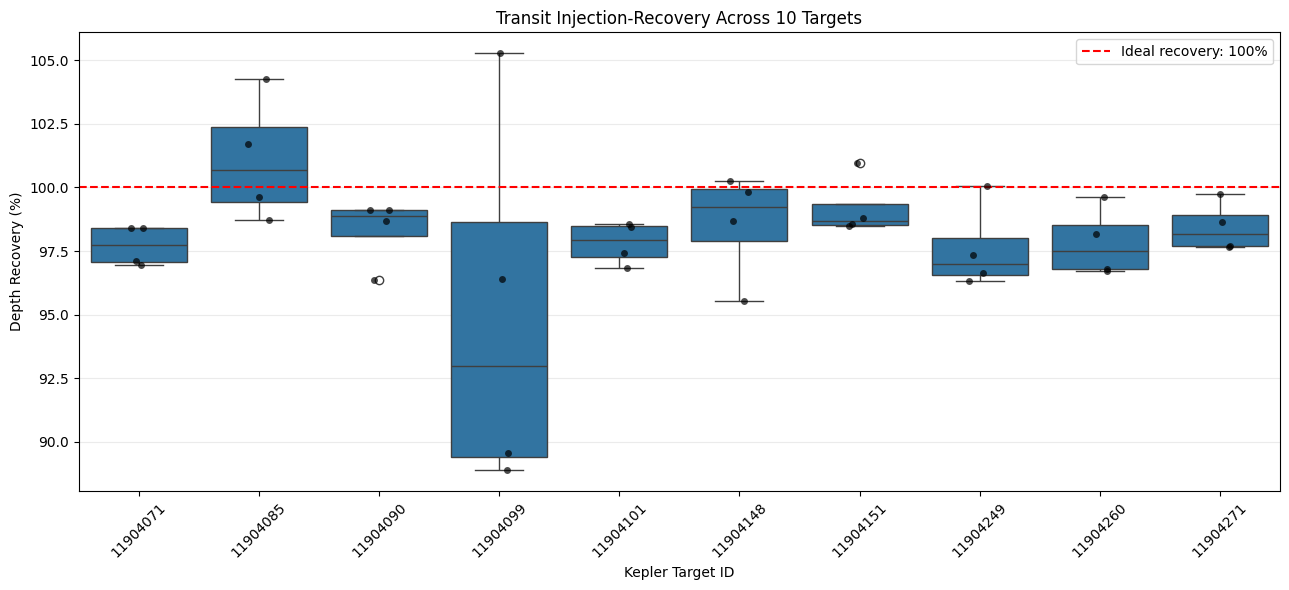

In [85]:
# Step 4.18: Recovery distribution by target

plt.figure(figsize=(13, 6))

sns.boxplot(
    data=multi_target_df,
    x="Target_ID",
    y="Recovery_Percent"
)

sns.stripplot(
    data=multi_target_df,
    x="Target_ID",
    y="Recovery_Percent",
    color="black",
    size=5,
    alpha=0.7
)

plt.axhline(
    100,
    color="red",
    linestyle="--",
    label="Ideal recovery: 100%"
)

plt.xticks(rotation=45)
plt.ylabel("Depth Recovery (%)")
plt.xlabel("Kepler Target ID")
plt.title("Transit Injection-Recovery Across 10 Targets")
plt.legend()
plt.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()

In [86]:

# Step 4.19: Transit depth sensitivity experiment

depth_values = [0.0005, 0.001, 0.002]  # 500, 1000, 2000 ppm
injection_duration = 3 / 24             # 3 hours

depth_sensitivity_results = []

for target_id, data in quality_versions["primary"].items():

    time = data["time"]
    flux = data["flux"]

    # Normalize original light curve
    original_lc = lk.LightCurve(time=time, flux=flux)
    original_normalized = original_lc.normalize()

    # Detrend original curve once
    original_detrended = original_normalized.flatten(
        window_length=51,
        polyorder=2
    )

    original_values = np.asarray(
        original_detrended.flux.value
    )

    # Four injection locations
    baseline = time.max() - time.min()

    centers = np.linspace(
        time.min() + 0.2 * baseline,
        time.max() - 0.2 * baseline,
        4
    )

    for depth in depth_values:

        for center in centers:

            in_transit = (
                np.abs(time - center)
                <= injection_duration / 2
            )

            local_window = (
                np.abs(time - center)
                <= 2 * injection_duration
            )

            local_in = local_window & in_transit
            local_out = local_window & (~in_transit)

            if in_transit.sum() < 3 or local_out.sum() < 3:
                continue

            # Inject transit
            injected_flux = original_normalized.flux.value.copy()

            injected_flux[in_transit] *= (1 - depth)

            injected_lc = lk.LightCurve(
                time=time,
                flux=injected_flux
            )

            # Apply same detrending procedure
            injected_detrended = injected_lc.flatten(
                window_length=51,
                polyorder=2
            )

            injected_values = np.asarray(
                injected_detrended.flux.value
            )

            # Differential signal
            difference = original_values - injected_values

            recovered_depth = (
                np.median(difference[local_in])
                - np.median(difference[local_out])
            )

            recovery_percent = (
                recovered_depth / depth
            ) * 100

            depth_sensitivity_results.append({
                "Target_ID": target_id,
                "Injected_Depth_ppm": depth * 1e6,
                "Injection_Center": center,
                "In_Transit_Points": in_transit.sum(),
                "Recovered_Depth_ppm": recovered_depth * 1e6,
                "Recovery_Percent": recovery_percent
            })

depth_sensitivity_df = pd.DataFrame(
    depth_sensitivity_results
)

print("Total successful injections:", len(depth_sensitivity_df))

display(depth_sensitivity_df.round(3))


Total successful injections: 120


,Target_ID,Injected_Depth_ppm,Injection_Center,In_Transit_Points,Recovered_Depth_ppm,Recovery_Percent
0,11904151,500.0,356.562,6,509.614,101.923
1,11904151,500.0,360.726,5,485.553,97.111
2,11904151,500.0,364.890,6,509.183,101.837
3,11904151,500.0,369.055,6,488.025,97.605
4,11904151,1000.0,356.562,6,1009.594,100.959
...,...,...,...,...,...,...
115,11904260,1000.0,369.055,6,981.784,98.178
116,11904260,2000.0,356.562,6,1955.384,97.769
117,11904260,2000.0,360.726,5,1972.911,98.646
118,11904260,2000.0,364.890,6,2000.429,100.021


In [87]:
depth_summary = (
    depth_sensitivity_df
    .groupby("Injected_Depth_ppm")["Recovery_Percent"]
    .agg(["count", "mean", "median", "std", "min", "max"])
    .round(3)
)

display(depth_summary)

,count,mean,median,std,min,max
Injected_Depth_ppm,,,,,,
500.0,40,97.383,97.096,2.645,87.128,103.435
1000.0,40,98.158,98.463,2.861,88.887,105.282
2000.0,40,99.734,99.821,2.099,93.412,105.696


In [88]:

# Step 4.20: Transit duration sensitivity experiment

duration_values_hours = [2, 3, 5]
injection_depth = 0.001  # 1000 ppm

duration_sensitivity_results = []

for target_id, data in quality_versions["primary"].items():

    time = data["time"]
    flux = data["flux"]

    # Normalize original light curve
    original_lc = lk.LightCurve(time=time, flux=flux)
    original_normalized = original_lc.normalize()

    # Detrend original curve
    original_detrended = original_normalized.flatten(
        window_length=51,
        polyorder=2
    )

    original_values = np.asarray(
        original_detrended.flux.value
    )

    baseline = time.max() - time.min()

    # Four injection locations
    centers = np.linspace(
        time.min() + 0.2 * baseline,
        time.max() - 0.2 * baseline,
        4
    )

    for duration_hours in duration_values_hours:

        duration_days = duration_hours / 24

        for center in centers:

            in_transit = (
                np.abs(time - center) <= duration_days / 2
            )

            local_window = (
                np.abs(time - center) <= 2 * duration_days
            )

            local_in = local_window & in_transit
            local_out = local_window & (~in_transit)

            if in_transit.sum() < 3 or local_out.sum() < 3:
                continue

            # Inject transit
            injected_flux = (
                original_normalized.flux.value.copy()
            )

            injected_flux[in_transit] *= (
                1 - injection_depth
            )

            injected_lc = lk.LightCurve(
                time=time,
                flux=injected_flux
            )

            # Apply the same detrending
            injected_detrended = injected_lc.flatten(
                window_length=51,
                polyorder=2
            )

            injected_values = np.asarray(
                injected_detrended.flux.value
            )

            # Differential signal
            difference = original_values - injected_values

            recovered_depth = (
                np.median(difference[local_in])
                - np.median(difference[local_out])
            )

            recovery_percent = (
                recovered_depth / injection_depth
            ) * 100

            duration_sensitivity_results.append({
                "Target_ID": target_id,
                "Duration_Hours": duration_hours,
                "Injection_Center": center,
                "In_Transit_Points": in_transit.sum(),
                "Recovered_Depth_ppm": recovered_depth * 1e6,
                "Recovery_Percent": recovery_percent
            })

duration_sensitivity_df = pd.DataFrame(
    duration_sensitivity_results
)

print(
    "Total successful injections:",
    len(duration_sensitivity_df)
)

display(duration_sensitivity_df.round(3))


Total successful injections: 120


,Target_ID,Duration_Hours,Injection_Center,In_Transit_Points,Recovered_Depth_ppm,Recovery_Percent
0,11904151,2,356.562,4,1012.057,101.206
1,11904151,2,360.726,3,994.392,99.439
2,11904151,2,364.890,4,915.802,91.580
3,11904151,2,369.055,4,999.233,99.923
4,11904151,3,356.562,6,1009.594,100.959
...,...,...,...,...,...,...
115,11904260,3,369.055,6,981.784,98.178
116,11904260,5,356.562,10,818.845,81.885
117,11904260,5,360.726,9,869.666,86.967
118,11904260,5,364.890,10,860.035,86.004


In [89]:
duration_summary = (
    duration_sensitivity_df
    .groupby("Duration_Hours")["Recovery_Percent"]
    .agg(["count", "mean", "median", "std", "min", "max"])
    .round(3)
)

display(duration_summary)

,count,mean,median,std,min,max
Duration_Hours,,,,,,
2,40,99.424,99.676,1.965,91.580,103.604
3,40,98.158,98.463,2.861,88.887,105.282
5,40,89.976,90.642,10.537,50.963,105.125


In [90]:
# Step 4.21: Investigate poor recovery for 5-hour transits

five_hour_results = duration_sensitivity_df[
    duration_sensitivity_df["Duration_Hours"] == 5
].copy()

print("--- Five worst recovery experiments ---")

display(
    five_hour_results
    .sort_values("Recovery_Percent")
    .head(10)
    .round(3)
)

print("\n--- Five best recovery experiments ---")

display(
    five_hour_results
    .sort_values("Recovery_Percent", ascending=False)
    .head(5)
    .round(3)
)

print("\n--- Recovery grouped by target ---")

display(
    five_hour_results
    .groupby("Target_ID")["Recovery_Percent"]
    .agg(["count", "mean", "std", "min", "max"])
    .round(3)
)

--- Five worst recovery experiments ---


,Target_ID,Duration_Hours,Injection_Center,In_Transit_Points,Recovered_Depth_ppm,Recovery_Percent
94,11904249,5,364.890,10,509.632,50.963
95,11904249,5,369.055,10,566.153,56.615
35,11904099,5,369.055,10,812.916,81.292
116,11904260,5,356.562,10,818.845,81.885
22,11904148,5,364.890,10,824.319,82.432
32,11904099,5,356.562,10,835.063,83.506
93,11904249,5,360.726,10,844.056,84.406
34,11904099,5,364.890,10,846.581,84.658
71,11904090,5,369.055,10,851.425,85.143
107,11904271,5,369.055,10,855.021,85.502



--- Five best recovery experiments ---


,Target_ID,Duration_Hours,Injection_Center,In_Transit_Points,Recovered_Depth_ppm,Recovery_Percent
45,11904085,5,360.726,8,1051.248,105.125
70,11904090,5,364.890,10,1021.243,102.124
44,11904085,5,356.562,10,1007.699,100.770
68,11904090,5,356.562,10,998.572,99.857
57,11904071,5,360.726,10,990.138,99.014



--- Recovery grouped by target ---


,count,mean,std,min,max
Target_ID,,,,,
11904071,4,96.219,5.225,88.385,99.014
11904085,4,100.672,3.173,98.302,105.125
11904090,4,96.280,7.614,85.143,102.124
11904099,4,85.005,3.961,81.292,90.564
11904101,4,91.673,4.950,85.777,95.780
11904148,4,89.973,5.825,82.432,96.118
11904151,4,94.908,3.366,90.278,98.343
11904249,4,69.438,18.225,50.963,85.767
11904260,4,85.621,2.579,81.885,87.631


In [91]:

# Step 4.22: Test detrending-window sensitivity

target_id = 11904249
injection_center = 364.890
injection_depth = 0.001
injection_duration = 5 / 24

data = quality_versions["primary"][target_id]

time = data["time"]
flux = data["flux"]

# Normalize original light curve
original_lc = lk.LightCurve(time=time, flux=flux)
original_normalized = original_lc.normalize()

original_flux = np.asarray(
    original_normalized.flux.value
)

# Inject the same transit into the original normalized flux
in_transit = (
    np.abs(time - injection_center)
    <= injection_duration / 2
)

injected_flux = original_flux.copy()
injected_flux[in_transit] *= (1 - injection_depth)

local_window = (
    np.abs(time - injection_center)
    <= 2 * injection_duration
)

local_in = local_window & in_transit
local_out = local_window & (~in_transit)

print("In-transit observations:", in_transit.sum())
print("Local baseline observations:", local_out.sum())

window_results = []
window_curves = {}

for window_length in [51, 101, 151]:

    # Detrend original curve
    original_detrended = original_normalized.flatten(
        window_length=window_length,
        polyorder=2
    )

    # Detrend injected curve
    injected_lc = lk.LightCurve(
        time=time,
        flux=injected_flux
    )

    injected_detrended = injected_lc.flatten(
        window_length=window_length,
        polyorder=2
    )

    original_values = np.asarray(
        original_detrended.flux.value
    )

    injected_values = np.asarray(
        injected_detrended.flux.value
    )

    difference = original_values - injected_values

    recovered_depth = (
        np.median(difference[local_in])
        - np.median(difference[local_out])
    )

    recovery_percent = (
        recovered_depth / injection_depth
    ) * 100

    window_results.append({
        "Window_Length": window_length,
        "Window_Duration_Hours": window_length * 29.4 / 60,
        "Recovered_Depth_ppm": recovered_depth * 1e6,
        "Recovery_Percent": recovery_percent
    })

    window_curves[window_length] = {
        "original": original_values,
        "injected": injected_values,
        "difference": difference
    }

window_comparison_df = pd.DataFrame(window_results)

display(window_comparison_df.round(3))


In-transit observations: 10
Local baseline observations: 31


,Window_Length,Window_Duration_Hours,Recovered_Depth_ppm,Recovery_Percent
0,51,24.99,506.520,50.652
1,101,49.49,658.826,65.883
2,151,73.99,858.154,85.815


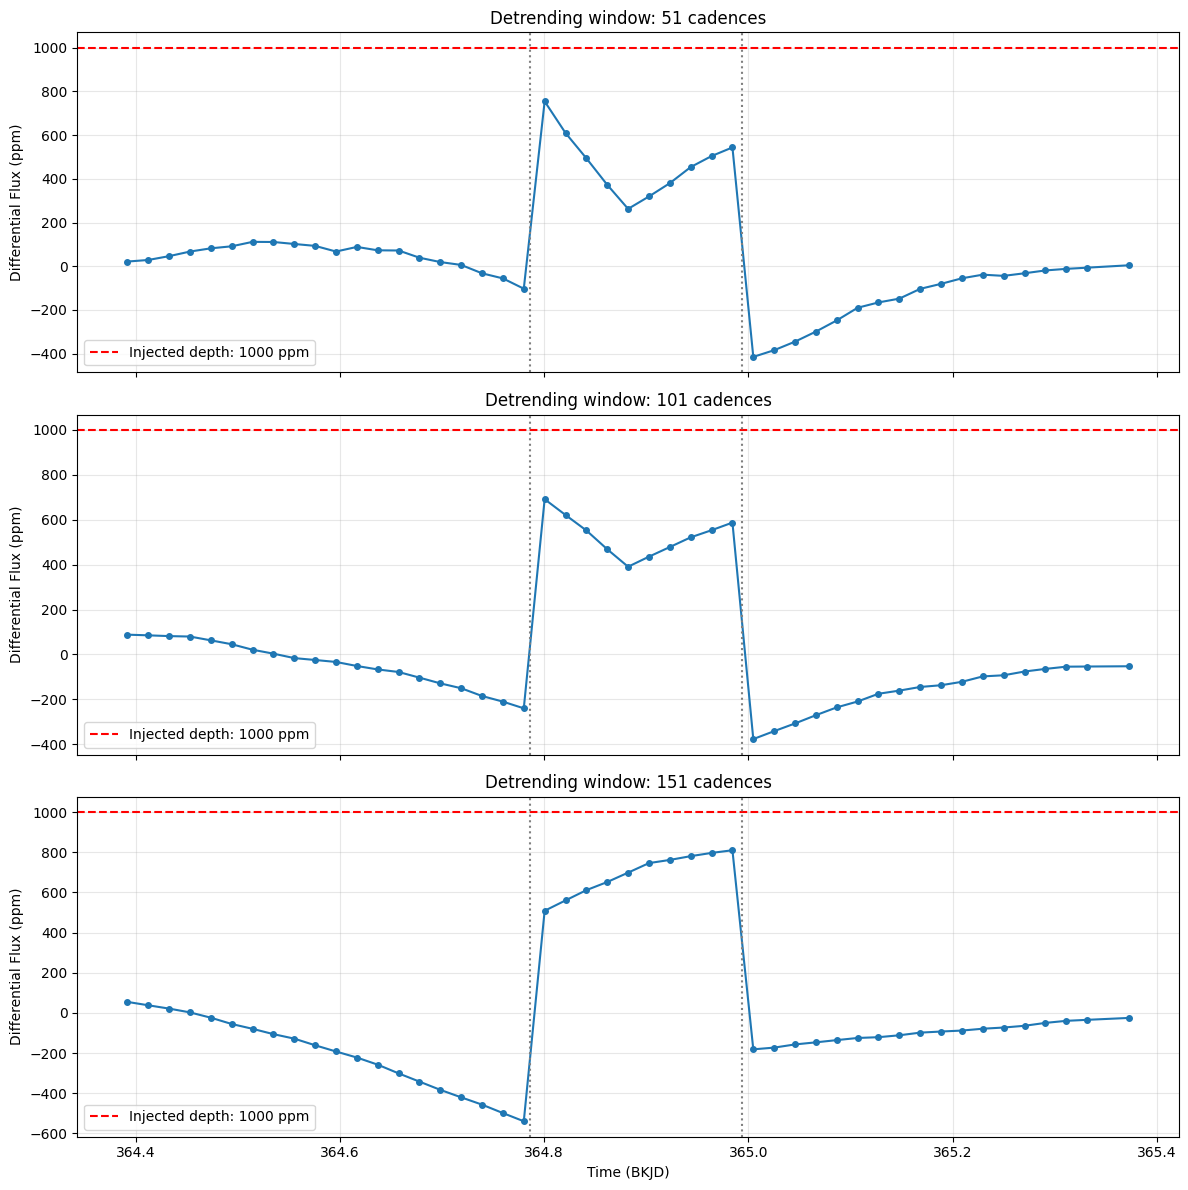

In [92]:
# Visualize differential recovery for each window

fig, axes = plt.subplots(
    3, 1,
    figsize=(12, 12),
    sharex=True
)

plot_mask = (
    np.abs(time - injection_center) <= 0.5
)

for ax, window_length in zip(
    axes, [51, 101, 151]
):

    difference = window_curves[window_length]["difference"]

    ax.plot(
        time[plot_mask],
        difference[plot_mask] * 1e6,
        "o-",
        markersize=4
    )

    ax.axhline(
        1000,
        color="red",
        linestyle="--",
        label="Injected depth: 1000 ppm"
    )

    ax.axvline(
        injection_center - injection_duration / 2,
        color="gray",
        linestyle=":"
    )

    ax.axvline(
        injection_center + injection_duration / 2,
        color="gray",
        linestyle=":"
    )

    ax.set_title(f"Detrending window: {window_length} cadences")
    ax.set_ylabel("Differential Flux (ppm)")
    ax.legend()
    ax.grid(alpha=0.3)

axes[-1].set_xlabel("Time (BKJD)")

plt.tight_layout()
plt.show()

In [93]:

# Step 4.23: Compare differential signal before and after detrending

# Differential signal before detrending
raw_difference = original_flux - injected_flux

print("BEFORE DETRENDING")
print(
    "Median in-transit difference (ppm):",
    np.median(raw_difference[local_in]) * 1e6
)
print(
    "Median out-of-transit difference (ppm):",
    np.median(raw_difference[local_out]) * 1e6
)

print("\nAFTER DETRENDING")

for window_length in [51, 101, 151]:

    difference = window_curves[window_length]["difference"]

    inside = np.median(difference[local_in]) * 1e6
    outside = np.median(difference[local_out]) * 1e6

    measured_depth = inside - outside

    print(f"\nWindow: {window_length} cadences")
    print(f"Median inside transit: {inside:.3f} ppm")
    print(f"Median outside transit: {outside:.3f} ppm")
    print(f"Measured differential depth: {measured_depth:.3f} ppm")


BEFORE DETRENDING
Median in-transit difference (ppm): 998.5864
Median out-of-transit difference (ppm): 0.0

AFTER DETRENDING

Window: 51 cadences
Median inside transit: 473.997 ppm
Median outside transit: -32.523 ppm
Measured differential depth: 506.520 ppm

Window: 101 cadences
Median inside transit: 537.097 ppm
Median outside transit: -121.729 ppm
Measured differential depth: 658.826 ppm

Window: 151 cadences
Median inside transit: 722.564 ppm
Median outside transit: -135.590 ppm
Measured differential depth: 858.154 ppm


In [94]:

# Step 4.24: Compare independent and shared detrending trends

shared_trend_results = []

for window_length in [51, 101, 151]:

    # Estimate trend using the original light curve
    original_flat, original_trend = original_normalized.flatten(
        window_length=window_length,
        polyorder=2,
        return_trend=True
    )

    # Apply the SAME trend to the injected light curve
    shared_trend_injected = (
        injected_lc / original_trend
    )

    original_values = np.asarray(
        original_flat.flux.value
    )

    shared_injected_values = np.asarray(
        shared_trend_injected.flux.value
    )

    # Differential signal using the shared trend
    shared_difference = (
        original_values - shared_injected_values
    )

    inside = np.median(shared_difference[local_in]) * 1e6
    outside = np.median(shared_difference[local_out]) * 1e6

    measured_depth = inside - outside

    shared_trend_results.append({
        "Window_Length": window_length,
        "Inside_Difference_ppm": inside,
        "Outside_Difference_ppm": outside,
        "Recovered_Depth_ppm": measured_depth,
        "Recovery_Percent": measured_depth / 1000 * 100
    })

shared_trend_df = pd.DataFrame(shared_trend_results)

display(shared_trend_df.round(3))


,Window_Length,Inside_Difference_ppm,Outside_Difference_ppm,Recovered_Depth_ppm,Recovery_Percent
0,51,999.939,0.0,999.939,99.994
1,101,999.832,0.0,999.832,99.983
2,151,999.671,0.0,999.671,99.967


In [95]:

# Step 4.25: Injection after detrending

# Use the original detrended curve from the 51-cadence experiment
baseline_flux = np.asarray(
    original_detrended.flux.value
)

# Inject into the detrended flux
post_detrend_injected = baseline_flux.copy()

post_detrend_injected[in_transit] *= (
    1 - injection_depth
)

# Differential signal
post_detrend_difference = (
    baseline_flux - post_detrend_injected
)

# Measure recovered depth
inside_depth = np.median(
    post_detrend_difference[local_in]
)

outside_depth = np.median(
    post_detrend_difference[local_out]
)

post_detrend_recovered = (
    inside_depth - outside_depth
)

post_detrend_recovery = (
    post_detrend_recovered / injection_depth
) * 100

print("Injected depth (ppm):", injection_depth * 1e6)
print("In-transit difference (ppm):", inside_depth * 1e6)
print("Out-of-transit difference (ppm):", outside_depth * 1e6)
print("Recovered depth (ppm):", post_detrend_recovered * 1e6)
print("Recovery (%):", post_detrend_recovery)


Injected depth (ppm): 1000.0
In-transit difference (ppm): 999.7011146571366
Out-of-transit difference (ppm): 0.0
Recovered depth (ppm): 999.7011146571366
Recovery (%): 99.97011146571366


In [96]:

# Step 4.26: Inspect processed light curves

print("Number of processed targets:",
      len(preprocessed_versions["primary"]))

print("\nTarget-level data summary:")

for target_id, data in preprocessed_versions["primary"].items():

    time = data["time"]
    flux = data["detrended_flux"]

    print(
        f"Target {target_id} | "
        f"Observations: {len(time)} | "
        f"Time baseline: {time.max() - time.min():.3f} days | "
        f"Flux range: {flux.min():.6f} to {flux.max():.6f}"
    )



Number of processed targets: 10

Target-level data summary:
Target 11904151 | Observations: 979 | Time baseline: 20.822 days | Flux range: 0.999581 to 1.000365
Target 11904148 | Observations: 989 | Time baseline: 20.822 days | Flux range: 0.998700 to 1.002071
Target 11904099 | Observations: 993 | Time baseline: 20.822 days | Flux range: 0.999246 to 1.000724
Target 11904085 | Observations: 957 | Time baseline: 20.822 days | Flux range: 0.999651 to 1.000309
Target 11904071 | Observations: 995 | Time baseline: 20.822 days | Flux range: 0.999331 to 1.000673
Target 11904090 | Observations: 998 | Time baseline: 20.822 days | Flux range: 0.999261 to 1.001119
Target 11904101 | Observations: 993 | Time baseline: 20.822 days | Flux range: 0.998723 to 1.001844
Target 11904249 | Observations: 986 | Time baseline: 20.822 days | Flux range: 0.998433 to 1.001034
Target 11904271 | Observations: 994 | Time baseline: 20.822 days | Flux range: 0.999071 to 1.000963
Target 11904260 | Observations: 984 | Ti

In [97]:

# Step 4.27: Check cadence consistency

cadence_results = []

for target_id, data in preprocessed_versions["primary"].items():

    time = np.sort(data["time"])

    time_differences = np.diff(time)
    median_cadence = np.median(time_differences)

    cadence_results.append({
        "Target_ID": target_id,
        "Observations": len(time),
        "Median_Cadence_Minutes": median_cadence * 24 * 60,
        "Maximum_Gap_Hours": time_differences.max() * 24,
        "Gaps_Above_1_Hour": np.sum(
            time_differences > 1 / 24
        )
    })

cadence_df = pd.DataFrame(cadence_results)

display(cadence_df.round(3))

print("\nOverall median cadence (minutes):",
      cadence_df["Median_Cadence_Minutes"].median())


,Target_ID,Observations,Median_Cadence_Minutes,Maximum_Gap_Hours,Gaps_Above_1_Hour
0,11904151,979,29.424,2.942,2
1,11904148,989,29.424,0.981,0
2,11904099,993,29.424,0.981,0
3,11904085,957,29.424,1.962,5
4,11904071,995,29.424,0.981,0
5,11904090,998,29.424,0.981,0
6,11904101,993,29.424,0.981,0
7,11904249,986,29.424,0.981,0
8,11904271,994,29.424,0.981,0
9,11904260,984,29.424,1.471,1



Overall median cadence (minutes): 29.423923941794783


In [98]:

# Step 4.28: Define and verify phase-folding configuration

INJECTED_PERIOD = 3.0
INJECTED_DURATION_HOURS = 3.0
INJECTED_DEPTH = 0.001

OUTPUT_POINTS = 200
WINDOW_DURATION_MULTIPLIER = 4

duration_days = INJECTED_DURATION_HOURS / 24

total_window_days = (
    WINDOW_DURATION_MULTIPLIER * duration_days
)

half_window_days = total_window_days / 2

half_phase_window = half_window_days / INJECTED_PERIOD

expected_transits = (
    (20.822 / INJECTED_PERIOD)
)

print("Orbital period:", INJECTED_PERIOD, "days")
print("Transit duration:", INJECTED_DURATION_HOURS, "hours")
print("Transit depth:", INJECTED_DEPTH * 1e6, "ppm")

print("Total phase window:", total_window_days * 24, "hours")
print("Half-window:", half_window_days * 24, "hours")

print("Phase interval:")
print(-half_phase_window, "to", half_phase_window)

print("Output points:", OUTPUT_POINTS)
print("Approximate transits across baseline:", expected_transits)


Orbital period: 3.0 days
Transit duration: 3.0 hours
Transit depth: 1000.0 ppm
Total phase window: 12.0 hours
Half-window: 6.0 hours
Phase interval:
-0.08333333333333333 to 0.08333333333333333
Output points: 200
Approximate transits across baseline: 6.940666666666666


In [99]:

# Step 4.29: Inject a periodic transit into one target

target_id = 11904151

data = preprocessed_versions["primary"][target_id]

time = np.asarray(data["time"])
flux = np.asarray(data["detrended_flux"]).copy()

# Set epoch at the midpoint of the observation baseline
injection_epoch = (time.min() + time.max()) / 2

# Calculate phase relative to the injected ephemeris
phase = (
    (time - injection_epoch + INJECTED_PERIOD / 2)
    % INJECTED_PERIOD
) / INJECTED_PERIOD - 0.5

# Identify observations inside periodic transit windows
phase_duration = (
    INJECTED_DURATION_HOURS / 24
) / INJECTED_PERIOD

in_transit = np.abs(phase) <= phase_duration / 2

# Inject periodic box-shaped transits
injected_flux = flux.copy()

injected_flux[in_transit] *= (
    1 - INJECTED_DEPTH
)

print("Target ID:", target_id)
print("Injection epoch (BKJD):", injection_epoch)
print("Orbital period (days):", INJECTED_PERIOD)
print("Number of injected in-transit observations:", in_transit.sum())
print("Number of observed transit events:")

transit_numbers = np.round(
    (time[in_transit] - injection_epoch) / INJECTED_PERIOD
).astype(int)

print(len(np.unique(transit_numbers)))

print("Original flux observations:", len(flux))
print("Injected flux observations:", len(injected_flux))


Target ID: 11904151
Injection epoch (BKJD): 362.80829214811456
Orbital period (days): 3.0
Number of injected in-transit observations: 42
Number of observed transit events:
7
Original flux observations: 979
Injected flux observations: 979


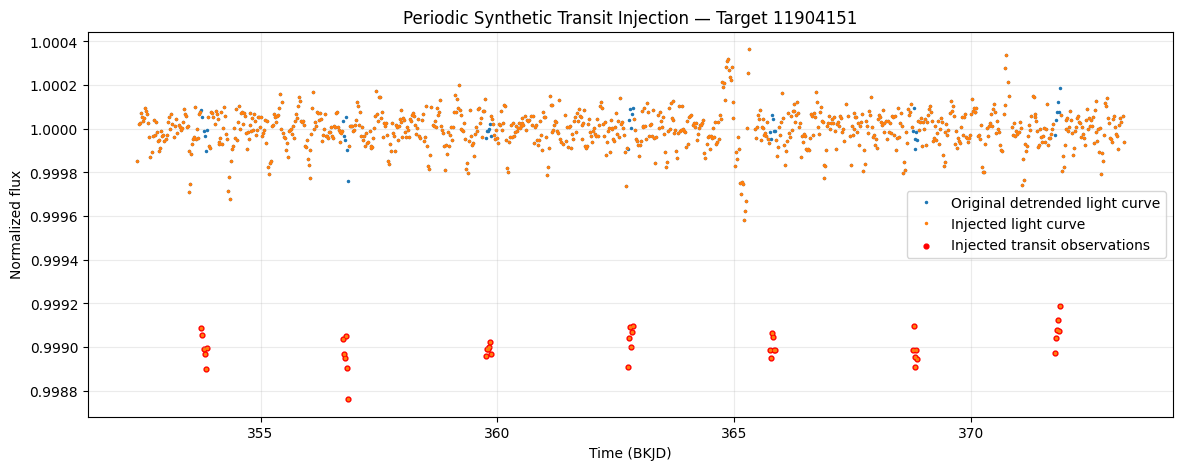

In [100]:
plt.figure(figsize=(14, 5))

plt.plot(
    time,
    flux,
    ".",
    markersize=3,
    label="Original detrended light curve"
)

plt.plot(
    time,
    injected_flux,
    ".",
    markersize=3,
    label="Injected light curve"
)

plt.scatter(
    time[in_transit],
    injected_flux[in_transit],
    color="red",
    s=12,
    label="Injected transit observations"
)

plt.xlabel("Time (BKJD)")
plt.ylabel("Normalized flux")
plt.title("Periodic Synthetic Transit Injection — Target 11904151")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

In [101]:

# Step 4.30: Verify individual injected transit events

transit_numbers = np.round(
    (time[in_transit] - injection_epoch) / INJECTED_PERIOD
).astype(int)

verification_rows = []

for transit_number in np.unique(transit_numbers):

    center = (
        injection_epoch
        + transit_number * INJECTED_PERIOD
    )

    event_mask = (
        in_transit
        & (np.round(
            (time - injection_epoch) / INJECTED_PERIOD
        ).astype(int) == transit_number)
    )

    original_event_flux = flux[event_mask]
    injected_event_flux = injected_flux[event_mask]

    measured_depth_ppm = np.median(
        (original_event_flux - injected_event_flux)
        / original_event_flux
    ) * 1e6

    verification_rows.append({
        "Transit_Number": transit_number,
        "Transit_Center_BKJD": center,
        "In_Transit_Points": event_mask.sum(),
        "Measured_Depth_ppm": measured_depth_ppm
    })

injection_verification_df = pd.DataFrame(
    verification_rows
)

display(injection_verification_df.round(3))

print("\nTotal observed events:",
      len(injection_verification_df))

print("Total in-transit points:",
      injection_verification_df["In_Transit_Points"].sum())

print("Mean measured depth (ppm):",
      injection_verification_df["Measured_Depth_ppm"].mean())

print("Standard deviation of measured depth (ppm):",
      injection_verification_df["Measured_Depth_ppm"].std())


,Transit_Number,Transit_Center_BKJD,In_Transit_Points,Measured_Depth_ppm
0,-3,353.808,6,1000.0
1,-2,356.808,6,1000.0
2,-1,359.808,6,1000.0
3,0,362.808,6,1000.0
4,1,365.808,6,1000.0
5,2,368.808,6,1000.0
6,3,371.808,6,1000.0



Total observed events: 7
Total in-transit points: 42
Mean measured depth (ppm): 999.9999999999983
Standard deviation of measured depth (ppm): 2.1071357775067765e-11


In [102]:

# Step 4.31: Phase-fold the injected light curve

# Calculate phase for every observation
phase_all = (
    (time - injection_epoch + INJECTED_PERIOD / 2)
    % INJECTED_PERIOD
) / INJECTED_PERIOD - 0.5

# Select the local phase window
phase_window = (
    INJECTED_DURATION_HOURS / 24
    * WINDOW_DURATION_MULTIPLIER
    / INJECTED_PERIOD
    / 2
)

local_mask = np.abs(phase_all) <= phase_window

local_phase = phase_all[local_mask]
local_flux = injected_flux[local_mask]

# Create 24 phase bins
OUTPUT_POINTS = 24

phase_edges = np.linspace(
    -phase_window,
    phase_window,
    OUTPUT_POINTS + 1
)

phase_centers = (
    phase_edges[:-1] + phase_edges[1:]
) / 2

folded_flux = np.full(OUTPUT_POINTS, np.nan)

for i in range(OUTPUT_POINTS):
    bin_mask = (
        (local_phase >= phase_edges[i])
        & (local_phase < phase_edges[i + 1])
    )

    if np.any(bin_mask):
        folded_flux[i] = np.median(local_flux[bin_mask])

print("Total observations:", len(time))
print("Observations in local phase window:", len(local_phase))
print("Output phase bins:", OUTPUT_POINTS)
print("Occupied bins:", np.isfinite(folded_flux).sum())
print("Empty bins:", np.isnan(folded_flux).sum())
print("Phase window:", -phase_window, "to", phase_window)


Total observations: 979
Observations in local phase window: 169
Output phase bins: 24
Occupied bins: 24
Empty bins: 0
Phase window: -0.08333333333333333 to 0.08333333333333333


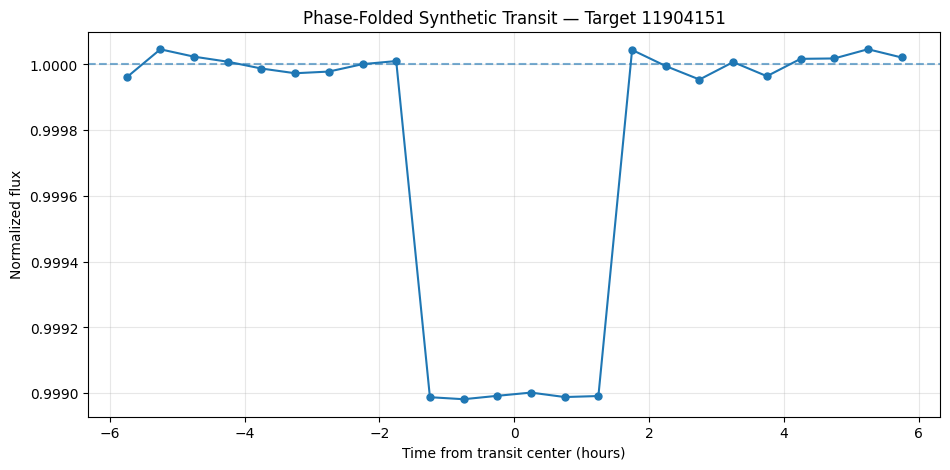

In [103]:
plt.figure(figsize=(11, 5))

plt.plot(
    phase_centers * INJECTED_PERIOD * 24,
    folded_flux,
    "o-",
    markersize=5
)

plt.axhline(1.0, linestyle="--", alpha=0.6)
plt.xlabel("Time from transit center (hours)")
plt.ylabel("Normalized flux")
plt.title("Phase-Folded Synthetic Transit — Target 11904151")
plt.grid(alpha=0.3)
plt.show()

In [104]:

# Step 4.32: Create the negative-control phase-folded sample

control_folded_flux = np.full(OUTPUT_POINTS, np.nan)

control_phase = phase_all[local_mask]
control_flux = flux[local_mask]

for i in range(OUTPUT_POINTS):

    bin_mask = (
        (control_phase >= phase_edges[i])
        & (control_phase < phase_edges[i + 1])
    )

    if np.any(bin_mask):
        control_folded_flux[i] = np.median(
            control_flux[bin_mask]
        )

# Compare positive and negative samples
comparison_df = pd.DataFrame({
    "Phase_Hours": phase_centers * INJECTED_PERIOD * 24,
    "Negative_Control": control_folded_flux,
    "Positive_Injected": folded_flux
})

display(comparison_df.round(7))

print("Negative-control occupied bins:",
      np.isfinite(control_folded_flux).sum())

print("Positive-sample occupied bins:",
      np.isfinite(folded_flux).sum())


,Phase_Hours,Negative_Control,Positive_Injected
0,-5.75,0.999961,0.999961
1,-5.25,1.000046,1.000046
2,-4.75,1.000024,1.000024
3,-4.25,1.000008,1.000008
4,-3.75,0.999988,0.999988
5,-3.25,0.999973,0.999973
6,-2.75,0.999978,0.999978
7,-2.25,1.000001,1.000001
8,-1.75,1.000010,1.000010
9,-1.25,0.999988,0.998988


Negative-control occupied bins: 24
Positive-sample occupied bins: 24


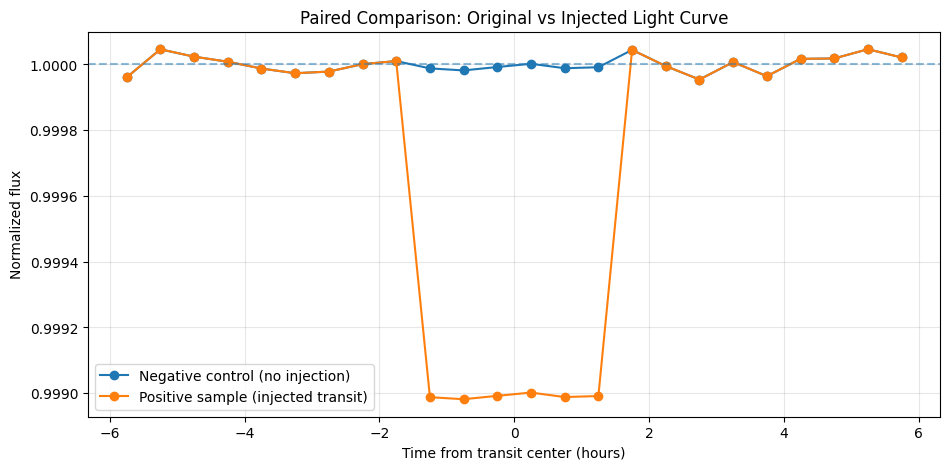

In [105]:
plt.figure(figsize=(11, 5))

plt.plot(
    phase_centers * INJECTED_PERIOD * 24,
    control_folded_flux,
    "o-",
    label="Negative control (no injection)"
)

plt.plot(
    phase_centers * INJECTED_PERIOD * 24,
    folded_flux,
    "o-",
    label="Positive sample (injected transit)"
)

plt.axhline(1.0, linestyle="--", alpha=0.5)
plt.xlabel("Time from transit center (hours)")
plt.ylabel("Normalized flux")
plt.title("Paired Comparison: Original vs Injected Light Curve")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [106]:

# Step 4.33: Quantify the injected signal in phase-folded bins

delta_ppm = (
    (control_folded_flux - folded_flux)
    / control_folded_flux
) * 1e6

paired_difference_df = pd.DataFrame({
    "Phase_Hours": phase_centers * INJECTED_PERIOD * 24,
    "Negative_Control": control_folded_flux,
    "Positive_Injected": folded_flux,
    "Injected_Difference_ppm": delta_ppm
})

display(paired_difference_df.round(3))

affected_bins = np.abs(delta_ppm) > 1

print("\nTotal phase bins:", OUTPUT_POINTS)
print("Bins with measurable injection effect:", affected_bins.sum())
print("Maximum measured difference (ppm):",
      np.nanmax(delta_ppm))
print("Minimum measured difference (ppm):",
      np.nanmin(delta_ppm))
print("Mean difference in affected bins (ppm):",
      np.nanmean(delta_ppm[affected_bins]))


,Phase_Hours,Negative_Control,Positive_Injected,Injected_Difference_ppm
0,-5.75,1.0,1.000,0.0
1,-5.25,1.0,1.000,0.0
2,-4.75,1.0,1.000,0.0
3,-4.25,1.0,1.000,0.0
4,-3.75,1.0,1.000,0.0
5,-3.25,1.0,1.000,0.0
6,-2.75,1.0,1.000,0.0
7,-2.25,1.0,1.000,0.0
8,-1.75,1.0,1.000,0.0
9,-1.25,1.0,0.999,1000.0



Total phase bins: 24
Bins with measurable injection effect: 6
Maximum measured difference (ppm): 1000.0000000000117
Minimum measured difference (ppm): 0.0
Mean difference in affected bins (ppm): 999.9999999999656


In [107]:

# Step 4.34: Create the first labeled paired dataset

sample_records = [
    {
        "Target_ID": target_id,
        "Label": 0,
        "Label_Description": "No synthetic transit injected",
        "Flux": control_folded_flux.copy()
    },
    {
        "Target_ID": target_id,
        "Label": 1,
        "Label_Description": "Synthetic transit injected",
        "Flux": folded_flux.copy()
    }
]

# Convert to a structured dataset
X_pilot = np.array([
    record["Flux"] for record in sample_records
])

y_pilot = np.array([
    record["Label"] for record in sample_records
])

target_ids_pilot = np.array([
    record["Target_ID"] for record in sample_records
])

print("Feature array shape:", X_pilot.shape)
print("Label array shape:", y_pilot.shape)
print("Target ID array:", target_ids_pilot)
print("Labels:", y_pilot)

print("\nClass counts:")
print(pd.Series(y_pilot).value_counts().sort_index())

print("\nMissing values:", np.isnan(X_pilot).sum())



Feature array shape: (2, 24)
Label array shape: (2,)
Target ID array: [11904151 11904151]
Labels: [0 1]

Class counts:
0    1
1    1
Name: count, dtype: int64

Missing values: 0


In [108]:

# Step 4.35: Build paired phase-folded samples for all 10 targets

X_records = []
y_records = []
target_records = []

injection_metadata = []

for current_target_id, data in preprocessed_versions["primary"].items():

    current_time = np.asarray(data["time"])
    current_flux = np.asarray(data["detrended_flux"])

    # Target-specific injection epoch
    current_epoch = (
        current_time.min() + current_time.max()
    ) / 2

    # Phase folding
    current_phase = (
        (current_time - current_epoch + INJECTED_PERIOD / 2)
        % INJECTED_PERIOD
    ) / INJECTED_PERIOD - 0.5

    # Local transit window
    current_local_mask = (
        np.abs(current_phase) <= phase_window
    )

    local_phase_current = current_phase[current_local_mask]
    local_flux_current = current_flux[current_local_mask]

    # Inject periodic box-shaped transits
    current_duration_phase = (
        INJECTED_DURATION_HOURS / 24
    ) / INJECTED_PERIOD

    current_in_transit = (
        np.abs(current_phase)
        <= current_duration_phase / 2
    )

    injected_current_flux = current_flux.copy()

    injected_current_flux[current_in_transit] *= (
        1 - INJECTED_DEPTH
    )

    injected_local_flux = injected_current_flux[
        current_local_mask
    ]

    # Phase-bin negative and positive samples
    negative_sample = np.full(OUTPUT_POINTS, np.nan)
    positive_sample = np.full(OUTPUT_POINTS, np.nan)

    for i in range(OUTPUT_POINTS):

        bin_mask = (
            (local_phase_current >= phase_edges[i])
            & (local_phase_current < phase_edges[i + 1])
        )

        if np.any(bin_mask):
            negative_sample[i] = np.median(
                local_flux_current[bin_mask]
            )

            positive_sample[i] = np.median(
                injected_local_flux[bin_mask]
            )

    # Check that neither sample contains missing bins
    if (
        np.isnan(negative_sample).any()
        or np.isnan(positive_sample).any()
    ):
        print(
            "Skipped target due to empty bins:",
            current_target_id
        )
        continue

    # Add negative sample
    X_records.append(negative_sample)
    y_records.append(0)
    target_records.append(current_target_id)

    # Add positive sample
    X_records.append(positive_sample)
    y_records.append(1)
    target_records.append(current_target_id)

    injection_metadata.append({
        "Target_ID": current_target_id,
        "Epoch_BKJD": current_epoch,
        "Original_Observations": len(current_time),
        "Local_Observations": len(local_phase_current),
        "Injected_Observations": current_in_transit.sum()
    })

# Convert to NumPy arrays
X_pilot_all = np.asarray(X_records)
y_pilot_all = np.asarray(y_records)
target_ids_all = np.asarray(target_records)

injection_metadata_df = pd.DataFrame(injection_metadata)

print("Feature array shape:", X_pilot_all.shape)
print("Label array shape:", y_pilot_all.shape)
print("Unique targets:", len(np.unique(target_ids_all)))

print("\nClass counts:")
print(pd.Series(y_pilot_all).value_counts().sort_index())

print("\nMissing values:", np.isnan(X_pilot_all).sum())

display(injection_metadata_df.round(4))


Feature array shape: (20, 24)
Label array shape: (20,)
Unique targets: 10

Class counts:
0    10
1    10
Name: count, dtype: int64

Missing values: 0


,Target_ID,Epoch_BKJD,Original_Observations,Local_Observations,Injected_Observations
0,11904151,362.8083,979,169,42
1,11904148,362.8083,989,169,42
2,11904099,362.8083,993,170,43
3,11904085,362.8083,957,162,42
4,11904071,362.8083,995,168,42
5,11904090,362.8083,998,170,43
6,11904101,362.8083,993,169,42
7,11904249,362.8083,986,168,43
8,11904271,362.8083,994,169,42
9,11904260,362.8083,984,169,43


In [109]:

# Step 4.36: Expand the pilot sample to 50 targets

expanded_search = target_search[:50]

expanded_lcs = expanded_search.download_all(
    flux_column="pdcsap_flux"
)

print("Downloaded light curves:", len(expanded_lcs))

print("\nTarget IDs:")
for lc in expanded_lcs:
    print(int(lc.meta["KEPLERID"]))


Downloaded light curves: 50

Target IDs:
11904151
11904148
11904099
11904085
11904071
11904090
11904101
11904249
11904271
11904260
11904306
11904255
11904011
11904330
11904336
11953662
11904038
11904343
11903954
11853857
11953623
11903967
11953746
11904299
11854129
11904384
11953712
11953764
11953728
11953600
11853987
11953831
11853779
11903880
11904423
11953668
11904426
11904425
11953670
11904446
11853905
11853890
11953902
11904451
11853859
11904450
11953858
11953757
11953694
11903848


In [110]:

# Step 4.37: Quality control for 50 downloaded targets

PRIMARY_MASK = 128 | 2048
EXPANDED_MASK = 128 | 2048 | 8192

expanded_quality_versions = {
    "primary": {},
    "expanded": {}
}

quality_summary_rows = []

for lc in expanded_lcs:

    target_id = int(lc.meta["KEPLERID"])

    time_values = np.ma.filled(
        np.ma.asarray(lc.time.value), np.nan
    )

    flux_values = np.ma.filled(
        np.ma.asarray(lc.flux.value), np.nan
    )

    quality = np.asarray(lc.quality, dtype=np.int64)

    finite = (
        np.isfinite(time_values)
        & np.isfinite(flux_values)
    )

    primary_keep = (
        finite & ((quality & PRIMARY_MASK) == 0)
    )

    expanded_keep = (
        finite & ((quality & EXPANDED_MASK) == 0)
    )

    expanded_quality_versions["primary"][target_id] = {
        "time": time_values[primary_keep],
        "flux": flux_values[primary_keep],
        "quality": quality[primary_keep]
    }

    expanded_quality_versions["expanded"][target_id] = {
        "time": time_values[expanded_keep],
        "flux": flux_values[expanded_keep],
        "quality": quality[expanded_keep]
    }

    quality_summary_rows.append({
        "Target_ID": target_id,
        "Total_Cadences": len(time_values),
        "Valid_Cadences": finite.sum(),
        "Primary_Retained": primary_keep.sum(),
        "Expanded_Retained": expanded_keep.sum(),
        "Primary_Removed": finite.sum() - primary_keep.sum(),
        "Expanded_Removed": finite.sum() - expanded_keep.sum()
    })

expanded_quality_summary = pd.DataFrame(
    quality_summary_rows
)

print("Downloaded targets:",
      len(expanded_lcs))

print("Primary processed targets:",
      len(expanded_quality_versions["primary"]))

print("Expanded processed targets:",
      len(expanded_quality_versions["expanded"]))

print("Total valid cadences:",
      expanded_quality_summary["Valid_Cadences"].sum())

print("Total retained — primary:",
      expanded_quality_summary["Primary_Retained"].sum())

print("Total retained — expanded:",
      expanded_quality_summary["Expanded_Retained"].sum())

display(expanded_quality_summary)


Downloaded targets: 50
Primary processed targets: 50
Expanded processed targets: 50
Total valid cadences: 50400
Total retained — primary: 49450
Total retained — expanded: 47999


,Target_ID,Total_Cadences,Valid_Cadences,Primary_Retained,Expanded_Retained,Primary_Removed,Expanded_Removed
0,11904151,1011,1008,979,941,29,67
1,11904148,1011,1008,989,965,19,43
2,11904099,1011,1008,993,962,15,46
3,11904085,1011,1008,957,910,51,98
4,11904071,1011,1008,995,969,13,39
5,11904090,1011,1008,998,971,10,37
6,11904101,1011,1008,993,971,15,37
7,11904249,1011,1008,986,952,22,56
8,11904271,1011,1008,994,970,14,38
9,11904260,1011,1008,984,956,24,52


In [111]:

# Step 4.38: Normalize and detrend all 50 targets

preprocessed_expanded = {
    "primary": {},
    "expanded": {}
}

preprocessing_summary = []

for mask_name in ["primary", "expanded"]:

    for target_id, data in expanded_quality_versions[mask_name].items():

        lc = lk.LightCurve(
            time=data["time"],
            flux=data["flux"]
        )

        # Normalize PDCSAP flux
        normalized_lc = lc.normalize()

        # Detrend with the same window used in the pilot
        detrended_lc = normalized_lc.flatten(
            window_length=51,
            polyorder=2
        )

        detrended_flux = np.asarray(
            detrended_lc.flux.value
        )

        detrended_time = np.asarray(
            detrended_lc.time.value
        )

        valid = (
            np.isfinite(detrended_time)
            & np.isfinite(detrended_flux)
        )

        detrended_time = detrended_time[valid]
        detrended_flux = detrended_flux[valid]

        preprocessed_expanded[mask_name][target_id] = {
            "time": detrended_time,
            "normalized_flux": np.asarray(
                normalized_lc.flux.value
            ),
            "detrended_flux": detrended_flux
        }

        median_flux = np.median(detrended_flux)

        mad_scatter = (
            1.4826
            * np.median(
                np.abs(detrended_flux - median_flux)
            )
        )

        preprocessing_summary.append({
            "Mask": mask_name,
            "Target_ID": target_id,
            "Observations": len(detrended_flux),
            "Baseline_Days": (
                detrended_time.max() - detrended_time.min()
            ),
            "Median_Flux": median_flux,
            "MAD_Scatter": mad_scatter,
            "Flux_Min": detrended_flux.min(),
            "Flux_Max": detrended_flux.max()
        })

preprocessing_summary_df = pd.DataFrame(
    preprocessing_summary
)

print("Primary targets processed:",
      len(preprocessed_expanded["primary"]))

print("Expanded targets processed:",
      len(preprocessed_expanded["expanded"]))

print("Total preprocessing records:",
      len(preprocessing_summary_df))

print("\nProcessing counts:")
print(
    preprocessing_summary_df.groupby("Mask")["Target_ID"].count()
)

print("\nMissing detrended flux values:",
      preprocessing_summary_df.isna().sum().sum())

display(
    preprocessing_summary_df
    .groupby("Mask")
    .agg({
        "Observations": ["min", "median", "max"],
        "Baseline_Days": ["min", "median", "max"],
        "Median_Flux": ["min", "median", "max"],
        "MAD_Scatter": ["min", "median", "max"]
    }).round(7)
)


Primary targets processed: 50
Expanded targets processed: 50
Total preprocessing records: 100

Processing counts:
Mask
expanded    50
primary     50
Name: Target_ID, dtype: int64

Missing detrended flux values: 0


Observations              Baseline_Days                        \
                  min median   max           min     median        max   
Mask                                                                     
expanded          909  965.0   996     20.780637  20.821508  20.821512   
primary           957  991.0  1008     20.780637  20.821508  20.821512   

         Median_Flux                    MAD_Scatter                      
                 min    median      max         min    median       max  
Mask                                                                     
expanded    0.999963  0.999998  1.00038    0.000070  0.000363  0.001418  
primary     0.999962  0.999999  1.00035    0.000072  0.000362  0.001352

Median MAD scatter: 0.0003614593666240813
25th percentile: 0.00019408914238834777
75th percentile: 0.000489427607536934
Maximum MAD scatter: 0.0013518431918124742

Highest-scatter 10 targets:


,Target_ID,Observations,MAD_Scatter
29,11953600,1000,0.001352
16,11904038,965,0.001322
47,11953757,999,0.000824
41,11853890,988,0.000740
22,11953746,994,0.000726
42,11953902,986,0.000700
18,11903954,1000,0.000669
49,11903848,993,0.000557
33,11903880,990,0.000547
31,11953831,985,0.000504



Lowest-scatter 10 targets:


,Target_ID,Observations,MAD_Scatter
36,11904426,979,0.000152
44,11853859,1001,0.000122
20,11953623,981,0.000119
17,11904343,985,0.000118
32,11853779,983,0.000098
3,11904085,957,0.000097
40,11853905,981,0.000093
24,11854129,988,0.000087
10,11904306,966,0.000078
0,11904151,979,0.000072


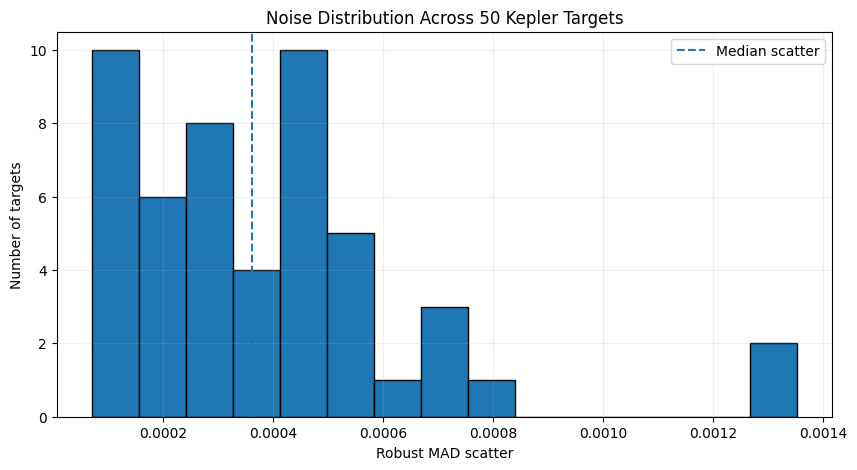

In [112]:

# Step 4.39: Analyze target-to-target noise variation

primary_summary = preprocessing_summary_df[
    preprocessing_summary_df["Mask"] == "primary"
].copy()

primary_summary = primary_summary.sort_values(
    "MAD_Scatter",
    ascending=False
)

median_scatter = primary_summary["MAD_Scatter"].median()
q1 = primary_summary["MAD_Scatter"].quantile(0.25)
q3 = primary_summary["MAD_Scatter"].quantile(0.75)

print("Median MAD scatter:", median_scatter)
print("25th percentile:", q1)
print("75th percentile:", q3)
print("Maximum MAD scatter:",
      primary_summary["MAD_Scatter"].max())

print("\nHighest-scatter 10 targets:")
display(
    primary_summary[
        ["Target_ID", "Observations", "MAD_Scatter"]
    ].head(10).round(7)
)

print("\nLowest-scatter 10 targets:")
display(
    primary_summary[
        ["Target_ID", "Observations", "MAD_Scatter"]
    ].tail(10).round(7)
)

plt.figure(figsize=(10, 5))

plt.hist(
    primary_summary["MAD_Scatter"],
    bins=15,
    edgecolor="black"
)

plt.axvline(
    median_scatter,
    linestyle="--",
    label="Median scatter"
)

plt.xlabel("Robust MAD scatter")
plt.ylabel("Number of targets")
plt.title("Noise Distribution Across 50 Kepler Targets")
plt.legend()
plt.grid(alpha=0.2)
plt.show()


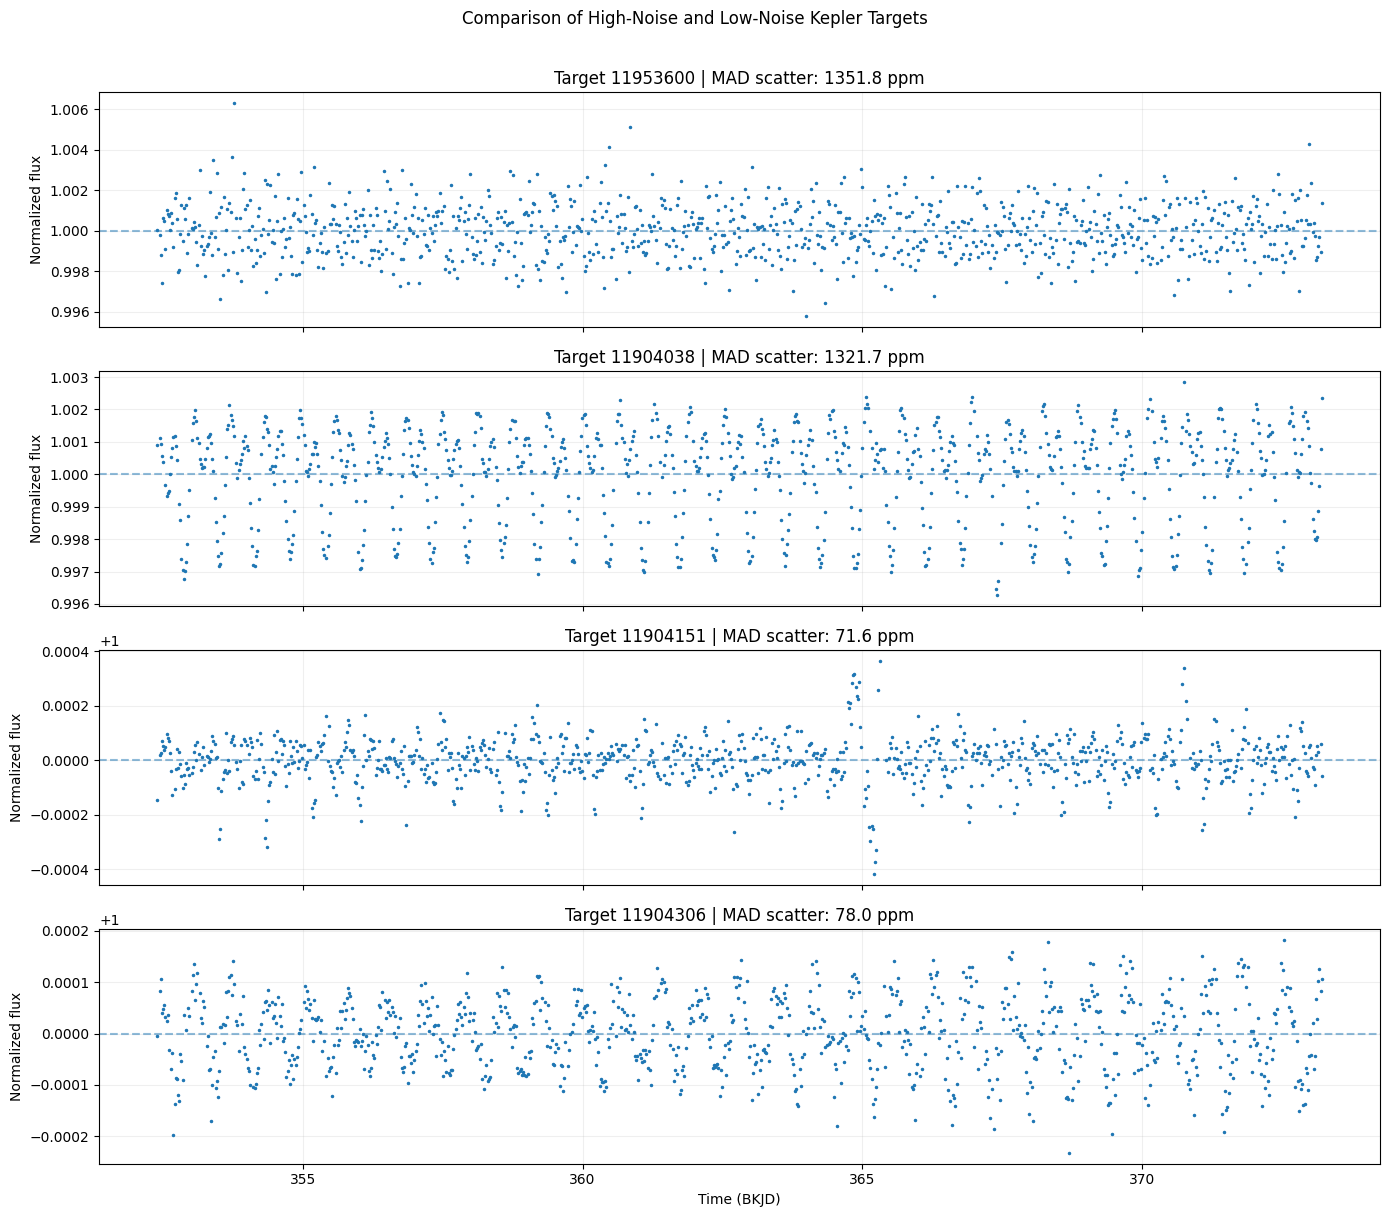

In [113]:

# Step 4.40: Compare high-noise and low-noise targets

selected_targets = [
    11953600,
    11904038,
    11904151,
    11904306
]

fig, axes = plt.subplots(
    4, 1,
    figsize=(14, 12),
    sharex=True
)

for ax, current_id in zip(axes, selected_targets):

    data = preprocessed_expanded["primary"][current_id]

    current_time = data["time"]
    current_flux = data["detrended_flux"]

    scatter_value = primary_summary.loc[
        primary_summary["Target_ID"] == current_id,
        "MAD_Scatter"
    ].iloc[0]

    ax.plot(
        current_time,
        current_flux,
        ".",
        markersize=3
    )

    ax.axhline(1.0, linestyle="--", alpha=0.5)

    ax.set_title(
        f"Target {current_id} | MAD scatter: "
        f"{scatter_value * 1e6:.1f} ppm"
    )

    ax.set_ylabel("Normalized flux")
    ax.grid(alpha=0.2)

axes[-1].set_xlabel("Time (BKJD)")

plt.suptitle(
    "Comparison of High-Noise and Low-Noise Kepler Targets",
    y=1.01
)

plt.tight_layout()
plt.show()


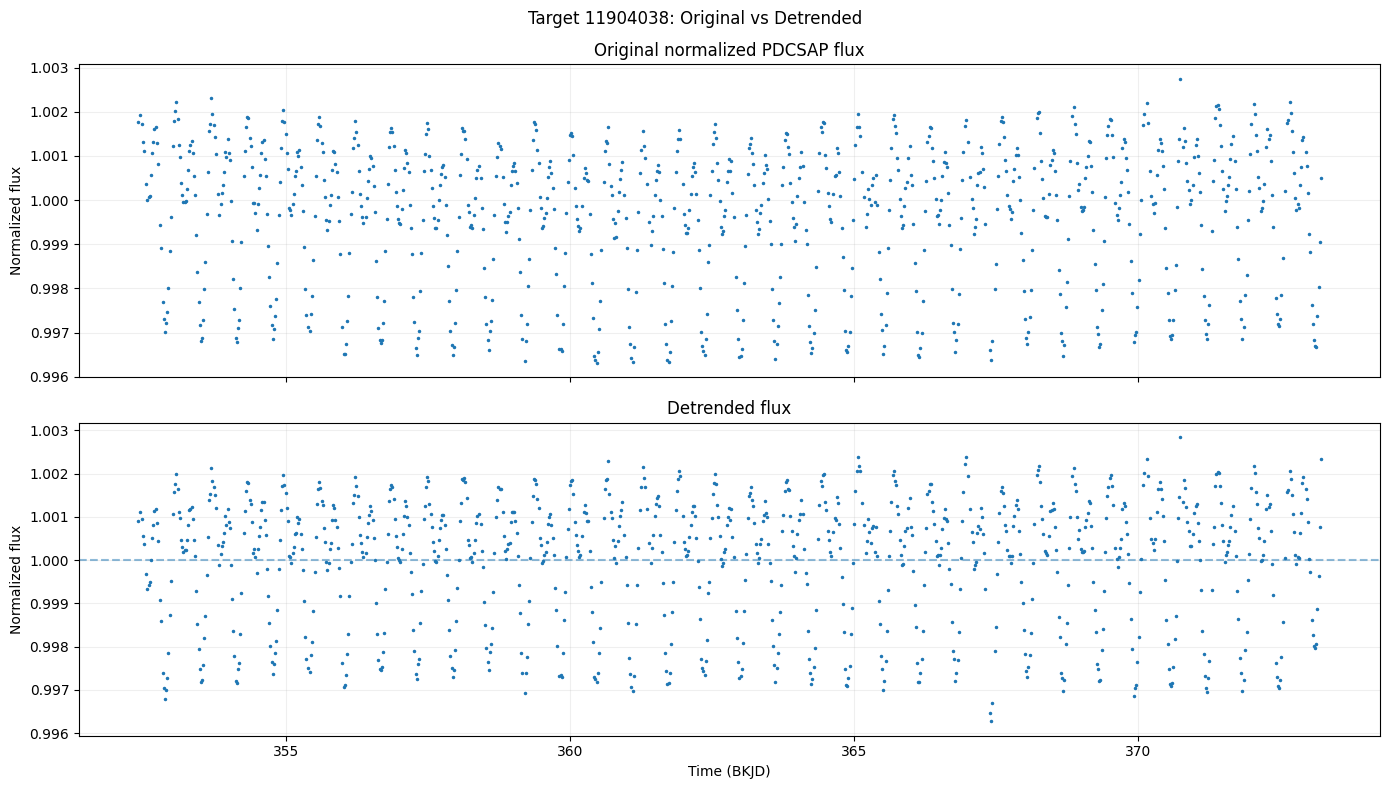

In [114]:

# Step 4.41: Compare original and detrended light curve
# for the target with repeated downward features.

target_id = 11904038

raw_data = expanded_quality_versions["primary"][target_id]
processed_data = preprocessed_expanded["primary"][target_id]

raw_time = np.asarray(raw_data["time"])
raw_flux = np.asarray(raw_data["flux"])

# Normalize the original flux for comparison
raw_normalized = raw_flux / np.nanmedian(raw_flux)

processed_time = processed_data["time"]
processed_flux = processed_data["detrended_flux"]

fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)

axes[0].plot(raw_time, raw_normalized, ".", markersize=3)
axes[0].set_title("Original normalized PDCSAP flux")
axes[0].set_ylabel("Normalized flux")
axes[0].grid(alpha=0.2)

axes[1].plot(processed_time, processed_flux, ".", markersize=3)
axes[1].axhline(1.0, linestyle="--", alpha=0.5)
axes[1].set_title("Detrended flux")
axes[1].set_xlabel("Time (BKJD)")
axes[1].set_ylabel("Normalized flux")
axes[1].grid(alpha=0.2)

plt.suptitle(f"Target {target_id}: Original vs Detrended")
plt.tight_layout()
plt.show()


BLS results for Target: 11904038
--------------------------------
Best period: 0.632063 days
Best duration: 4.00 hours
Best epoch: 352.876708 BKJD
Transit depth: 3082.99 ppm
Maximum BLS power: 0.0422


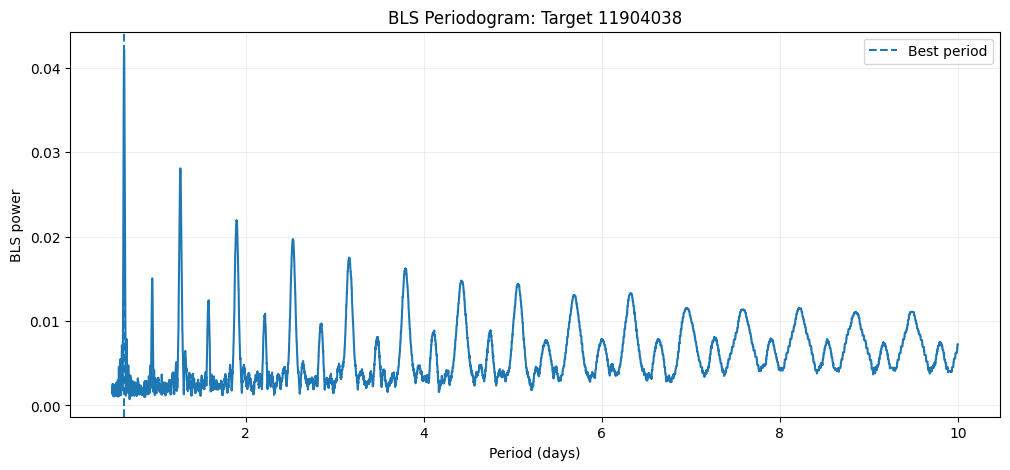

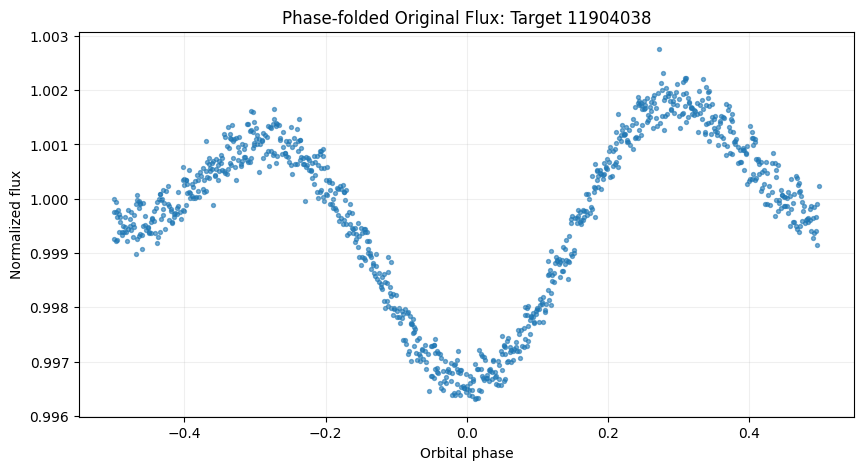

In [115]:

# Step 4.42: BLS analysis of Target 11904038
# Use original normalized PDCSAP flux, not detrended flux.

target_id = 11904038

raw_data = expanded_quality_versions["primary"][target_id]

time = np.asarray(raw_data["time"], dtype=float)
flux = np.asarray(raw_data["flux"], dtype=float)

# Normalize original flux
flux = flux / np.nanmedian(flux)

# Remove invalid values
valid = np.isfinite(time) & np.isfinite(flux)
time = time[valid]
flux = flux[valid]

# Sort observations by time
order = np.argsort(time)
time = time[order]
flux = flux[order]

# BLS model
bls = BoxLeastSquares(time, flux)

# Search periods from 0.5 to 10 days
periods = np.linspace(0.5, 10.0, 10000)

# Search transit durations from 1 to 5 hours
durations = np.array([1, 1.5, 2, 2.5, 3, 4, 5]) / 24

results = bls.power(
    periods,
    durations,
    objective="snr"
)

best_index = np.argmax(results.power)

best_period = results.period[best_index]
best_duration = results.duration[best_index]
best_epoch = results.transit_time[best_index]
best_depth = results.depth[best_index]
best_power = results.power[best_index]

print("BLS results for Target:", target_id)
print("--------------------------------")
print(f"Best period: {best_period:.6f} days")
print(f"Best duration: {best_duration * 24:.2f} hours")
print(f"Best epoch: {best_epoch:.6f} BKJD")
print(f"Transit depth: {best_depth * 1e6:.2f} ppm")
print(f"Maximum BLS power: {best_power:.4f}")

# Periodogram
plt.figure(figsize=(12, 5))
plt.plot(results.period, results.power)
plt.axvline(best_period, linestyle="--", label="Best period")
plt.xlabel("Period (days)")
plt.ylabel("BLS power")
plt.title("BLS Periodogram: Target 11904038")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

# Phase-folded original flux
phase = (
    (time - best_epoch + best_period / 2) % best_period
) / best_period - 0.5

plt.figure(figsize=(10, 5))
plt.scatter(phase, flux, s=8, alpha=0.6)
plt.xlabel("Orbital phase")
plt.ylabel("Normalized flux")
plt.title("Phase-folded Original Flux: Target 11904038")
plt.grid(alpha=0.2)
plt.show()


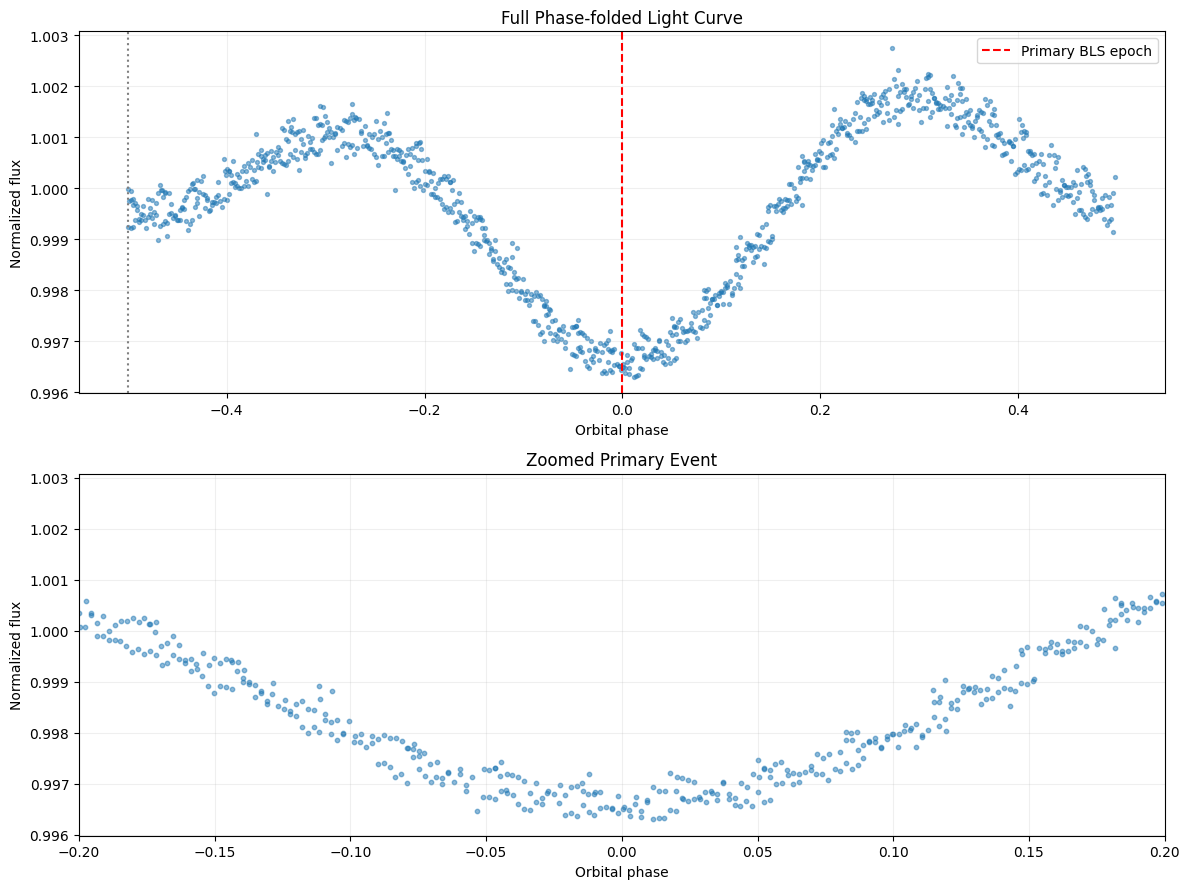

Phase-folded observations: 965
Best period: 0.6320632063206321
Expected secondary eclipse phase (circular orbit): approximately 0.5


In [116]:

# Step 4.43: Phase-folded light curve and possible secondary eclipse

phase = (
    (time - best_epoch + best_period / 2) % best_period
) / best_period - 0.5

# Sort by phase for easier visualization
order = np.argsort(phase)
phase_sorted = phase[order]
flux_sorted = flux[order]

fig, axes = plt.subplots(2, 1, figsize=(12, 9))

# Full orbital phase
axes[0].scatter(
    phase_sorted,
    flux_sorted,
    s=8,
    alpha=0.5
)
axes[0].axvline(0, color="red", linestyle="--",
                label="Primary BLS epoch")
axes[0].axvline(-0.5, color="gray", linestyle=":")
axes[0].set_xlabel("Orbital phase")
axes[0].set_ylabel("Normalized flux")
axes[0].set_title("Full Phase-folded Light Curve")
axes[0].legend()
axes[0].grid(alpha=0.2)

# Transit region around phase zero
axes[1].scatter(
    phase_sorted,
    flux_sorted,
    s=10,
    alpha=0.5
)
axes[1].set_xlim(-0.2, 0.2)
axes[1].set_xlabel("Orbital phase")
axes[1].set_ylabel("Normalized flux")
axes[1].set_title("Zoomed Primary Event")
axes[1].grid(alpha=0.2)

plt.tight_layout()
plt.show()

print("Phase-folded observations:", len(phase_sorted))
print("Best period:", best_period)
print("Expected secondary eclipse phase (circular orbit): approximately 0.5")


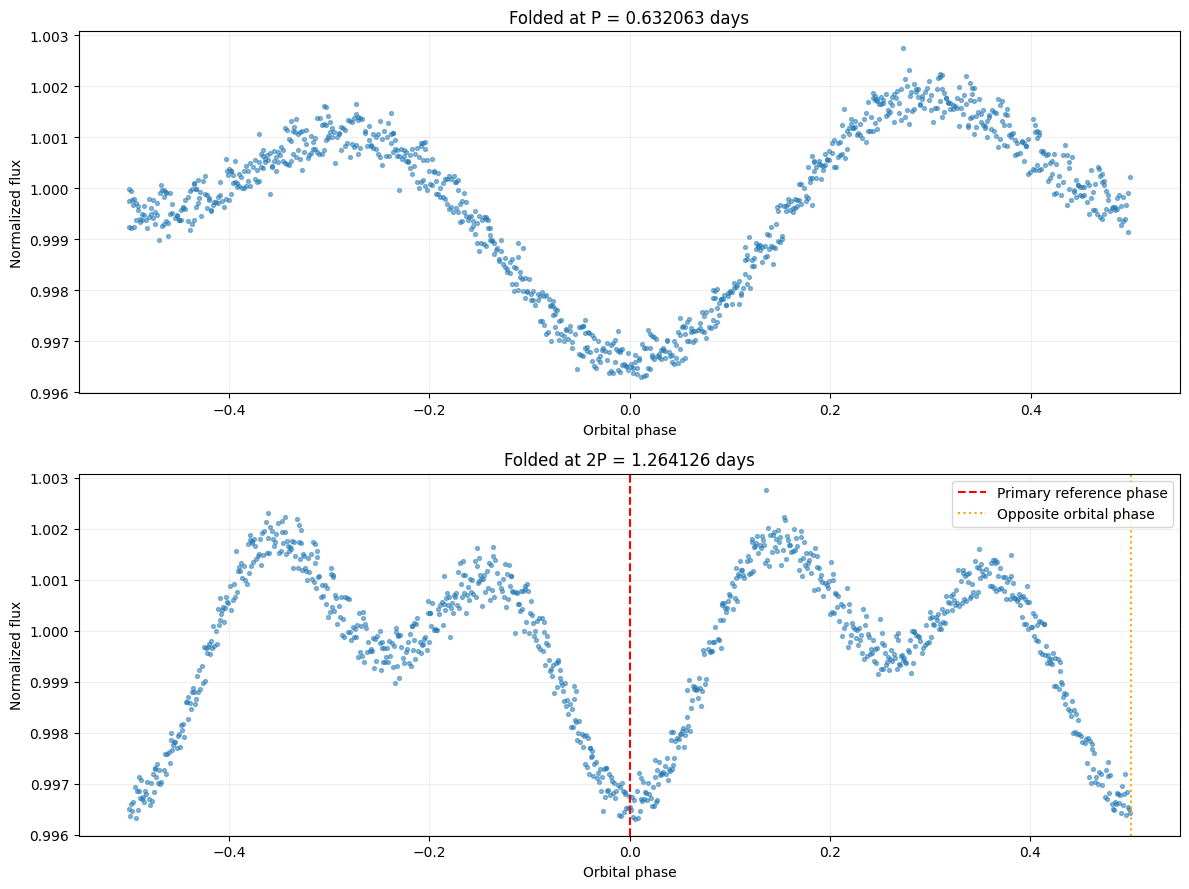

Period tested: 0.632063 days
Double period tested: 1.264126 days


In [117]:

# Step 4.44: Compare BLS period with twice the BLS period

period_1 = best_period
period_2 = 2 * best_period

phase_1 = (
    (time - best_epoch + period_1 / 2) % period_1
) / period_1 - 0.5

phase_2 = (
    (time - best_epoch + period_2 / 2) % period_2
) / period_2 - 0.5

fig, axes = plt.subplots(2, 1, figsize=(12, 9))

axes[0].scatter(phase_1, flux, s=8, alpha=0.5)
axes[0].set_title(f"Folded at P = {period_1:.6f} days")
axes[0].set_xlabel("Orbital phase")
axes[0].set_ylabel("Normalized flux")
axes[0].grid(alpha=0.2)

axes[1].scatter(phase_2, flux, s=8, alpha=0.5)
axes[1].axvline(0, color="red", linestyle="--",
                label="Primary reference phase")
axes[1].axvline(0.5, color="orange", linestyle=":",
                label="Opposite orbital phase")
axes[1].set_title(f"Folded at 2P = {period_2:.6f} days")
axes[1].set_xlabel("Orbital phase")
axes[1].set_ylabel("Normalized flux")
axes[1].legend()
axes[1].grid(alpha=0.2)

plt.tight_layout()
plt.show()

print(f"Period tested: {period_1:.6f} days")
print(f"Double period tested: {period_2:.6f} days")


In [118]:

# Step 4.45: Create a target review log

target_review_log = pd.DataFrame([
    {
        "Target_ID": 11904038,
        "Review_Status": "Unclassified",
        "Include_in_initial_training": False,
        "BLS_Period_days": best_period,
        "BLS_Duration_hours": best_duration * 24,
        "BLS_Depth_ppm": best_depth * 1e6,
        "Original_signal_present": True,
        "Phase_fold_morphology": "Broad smooth periodic variation",
        "Double_period_result": "No clear distinct secondary eclipse",
        "Reason": (
            "Periodic signal is not a clean isolated transit profile; "
            "possible stellar or binary-related variability."
        )
    }
])

display(target_review_log)


,Target_ID,Review_Status,Include_in_initial_training,BLS_Period_days,BLS_Duration_hours,BLS_Depth_ppm,Original_signal_present,Phase_fold_morphology,Double_period_result,Reason
0,11904038,Unclassified,False,0.632063,4.0,3082.988808,True,Broad smooth periodic variation,No clear distinct secondary eclipse,Periodic signal is not a clean isolated transi...


In [119]:

# Step 4.46: BLS screening across all 50 Kepler targets

period_grid = np.linspace(0.5, 10.0, 5000)
duration_grid = np.array([1, 1.5, 2, 2.5, 3, 4, 5]) / 24

bls_screening_results = []

for target_id, data in expanded_quality_versions["primary"].items():

    time_values = np.asarray(data["time"], dtype=float)
    flux_values = np.asarray(data["flux"], dtype=float)

    # Normalize original PDCSAP flux
    flux_values = flux_values / np.nanmedian(flux_values)

    valid = (
        np.isfinite(time_values) &
        np.isfinite(flux_values)
    )

    time_values = time_values[valid]
    flux_values = flux_values[valid]

    order = np.argsort(time_values)
    time_values = time_values[order]
    flux_values = flux_values[order]

    try:
        model = BoxLeastSquares(time_values, flux_values)

        result = model.power(
            period_grid,
            duration_grid,
            objective="snr"
        )

        best_idx = np.argmax(result.power)

        bls_screening_results.append({
            "Target_ID": target_id,
            "Observations": len(time_values),
            "Best_Period_days": float(result.period[best_idx]),
            "Best_Duration_hours": float(
                result.duration[best_idx] * 24
            ),
            "Best_Epoch_BKJD": float(
                result.transit_time[best_idx]
            ),
            "Depth_ppm": float(
                result.depth[best_idx] * 1e6
            ),
            "BLS_Power": float(result.power[best_idx]),
            "Status": "Screened"
        })

    except Exception as error:
        bls_screening_results.append({
            "Target_ID": target_id,
            "Observations": len(time_values),
            "Best_Period_days": np.nan,
            "Best_Duration_hours": np.nan,
            "Best_Epoch_BKJD": np.nan,
            "Depth_ppm": np.nan,
            "BLS_Power": np.nan,
            "Status": f"Error: {error}"
        })

bls_screening_df = pd.DataFrame(bls_screening_results)

bls_screening_df = bls_screening_df.merge(
    primary_summary[["Target_ID", "MAD_Scatter"]],
    on="Target_ID",
    how="left"
)

bls_screening_df = bls_screening_df.sort_values(
    "BLS_Power",
    ascending=False
).reset_index(drop=True)

print("Total targets screened:", len(bls_screening_df))
print("Successful BLS runs:",
      (bls_screening_df["Status"] == "Screened").sum())

display(
    bls_screening_df.round(6)
)


Total targets screened: 50
Successful BLS runs: 50


,Target_ID,Observations,Best_Period_days,Best_Duration_hours,Best_Epoch_BKJD,Depth_ppm,BLS_Power,Status,MAD_Scatter
0,11904038,965,0.633027,4.0,352.855875,3059.917150,0.042121,Screened,0.001322
1,11904099,993,7.480096,5.0,359.772537,8592.706563,0.038958,Screened,0.000223
2,11904011,982,4.515503,5.0,353.214206,5155.380823,0.036505,Screened,0.000167
3,11904271,994,9.847970,5.0,360.714206,3913.705608,0.018153,Screened,0.000279
4,11904260,984,7.662533,5.0,352.560037,2915.048503,0.016220,Screened,0.000493
5,11904249,986,9.055511,5.0,358.726708,2055.377076,0.009318,Screened,0.000292
6,11953600,1000,7.139928,4.0,358.855878,1735.760835,0.008735,Screened,0.001352
7,11904423,990,7.979896,5.0,352.539207,1441.629248,0.007900,Screened,0.000249
8,11953668,979,7.797459,5.0,357.730880,1465.043438,0.006641,Screened,0.000447
9,11853857,991,9.114423,5.0,352.539199,1117.523834,0.006219,Screened,0.000438


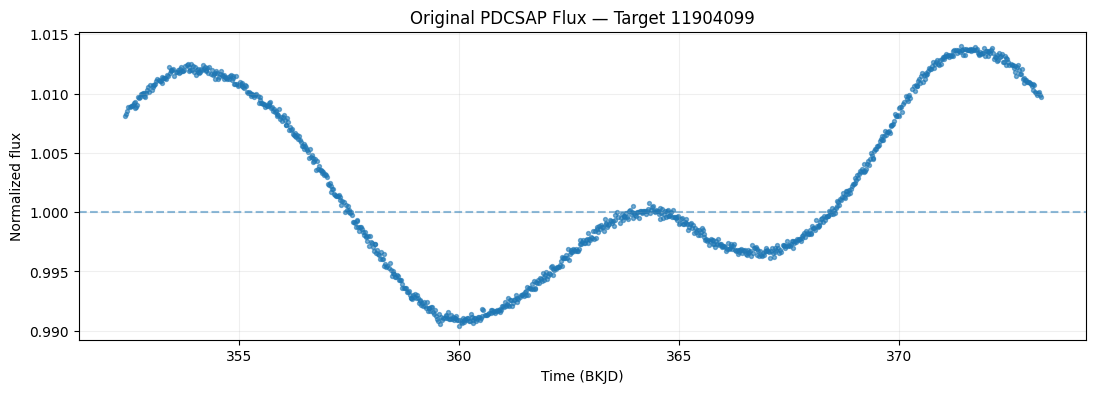

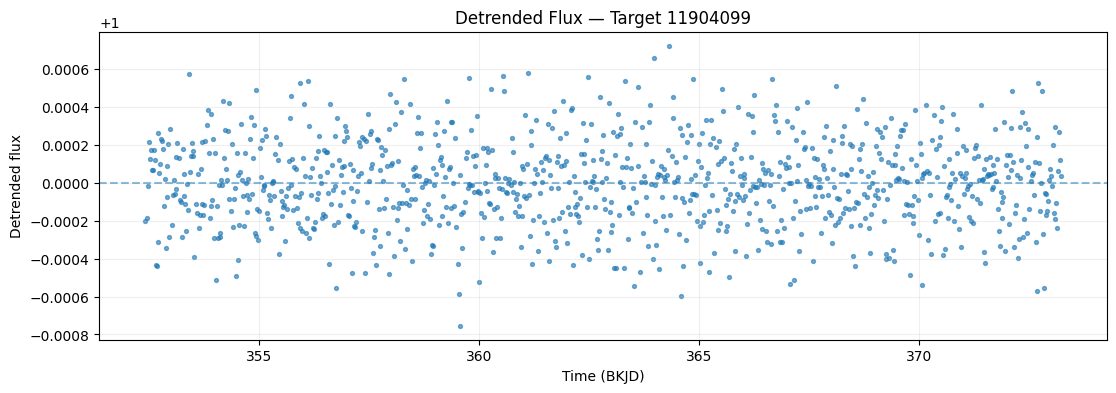

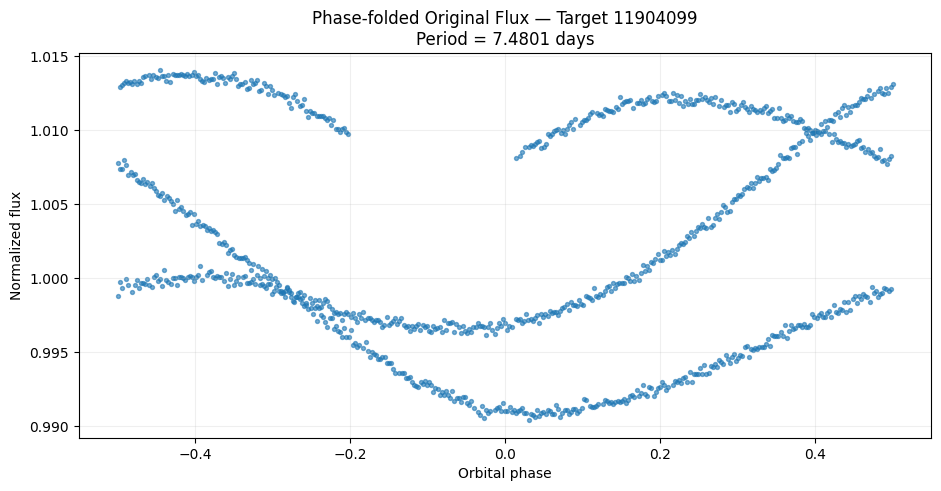

Target: 11904099
Period: 7.480096019203841
Duration (hours): 5.0
Depth (ppm): 8592.70656339705
BLS power: 0.03895813307033708


In [120]:

# Step 4.47: Visual review of Target 11904099

target_id = 11904099

raw_data = expanded_quality_versions["primary"][target_id]

time_review = np.asarray(raw_data["time"], dtype=float)
flux_review = np.asarray(raw_data["flux"], dtype=float)

flux_review = flux_review / np.nanmedian(flux_review)

valid = np.isfinite(time_review) & np.isfinite(flux_review)
time_review = time_review[valid]
flux_review = flux_review[valid]

order = np.argsort(time_review)
time_review = time_review[order]
flux_review = flux_review[order]

# Original normalized flux
plt.figure(figsize=(13, 4))
plt.scatter(time_review, flux_review, s=8, alpha=0.6)
plt.axhline(1.0, linestyle="--", alpha=0.5)
plt.xlabel("Time (BKJD)")
plt.ylabel("Normalized flux")
plt.title(f"Original PDCSAP Flux — Target {target_id}")
plt.grid(alpha=0.2)
plt.show()

# Detrended flux
processed = preprocessed_expanded["primary"][target_id]

plt.figure(figsize=(13, 4))
plt.scatter(
    processed["time"],
    processed["detrended_flux"],
    s=8,
    alpha=0.6
)
plt.axhline(1.0, linestyle="--", alpha=0.5)
plt.xlabel("Time (BKJD)")
plt.ylabel("Detrended flux")
plt.title(f"Detrended Flux — Target {target_id}")
plt.grid(alpha=0.2)
plt.show()

# BLS phase folding using the screening result
row = bls_screening_df[
    bls_screening_df["Target_ID"] == target_id
].iloc[0]

period_review = row["Best_Period_days"]
epoch_review = row["Best_Epoch_BKJD"]

phase_review = (
    (time_review - epoch_review + period_review / 2)
    % period_review
) / period_review - 0.5

plt.figure(figsize=(11, 5))
plt.scatter(phase_review, flux_review, s=8, alpha=0.6)
plt.xlabel("Orbital phase")
plt.ylabel("Normalized flux")
plt.title(
    f"Phase-folded Original Flux — Target {target_id}\n"
    f"Period = {period_review:.4f} days"
)
plt.grid(alpha=0.2)
plt.show()

print("Target:", target_id)
print("Period:", period_review)
print("Duration (hours):", row["Best_Duration_hours"])
print("Depth (ppm):", row["Depth_ppm"])
print("BLS power:", row["BLS_Power"])


In [121]:

# Step 4.48: Add Target 11904099 to the review log

new_review = pd.DataFrame([{
    "Target_ID": 11904099,
    "Review_Status": "Unclassified",
    "Include_in_initial_training": False,
    "BLS_Period_days": 7.480096,
    "BLS_Duration_hours": 5.0,
    "BLS_Depth_ppm": 8592.706563,
    "Original_signal_present": True,
    "Phase_fold_morphology": "Broad smooth variation",
    "Double_period_result": "Not yet tested",
    "Reason": (
        "Large-scale flux variation dominates the original light curve; "
        "folded profile does not show a clear isolated transit."
    )
}])

target_review_log = pd.concat(
    [target_review_log, new_review],
    ignore_index=True
)

display(target_review_log)


,Target_ID,Review_Status,Include_in_initial_training,BLS_Period_days,BLS_Duration_hours,BLS_Depth_ppm,Original_signal_present,Phase_fold_morphology,Double_period_result,Reason
0,11904038,Unclassified,False,0.632063,4.0,3082.988808,True,Broad smooth periodic variation,No clear distinct secondary eclipse,Periodic signal is not a clean isolated transi...
1,11904099,Unclassified,False,7.480096,5.0,8592.706563,True,Broad smooth variation,Not yet tested,Large-scale flux variation dominates the origi...


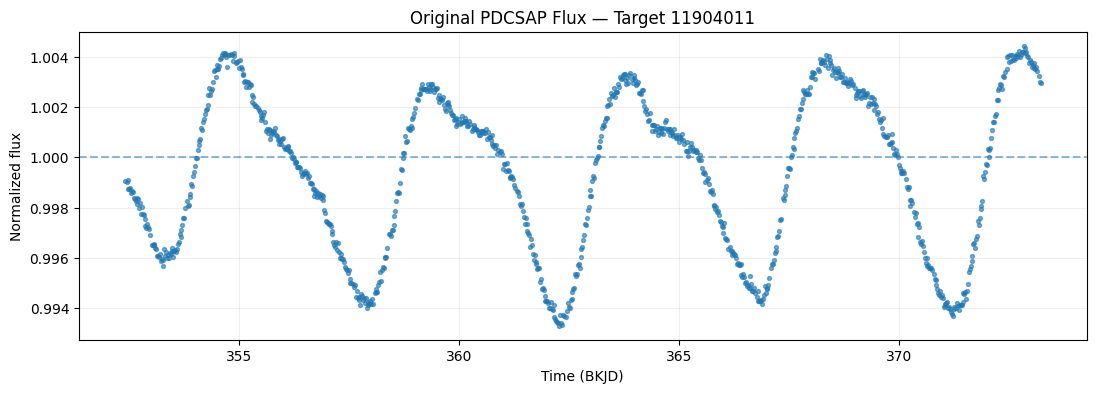

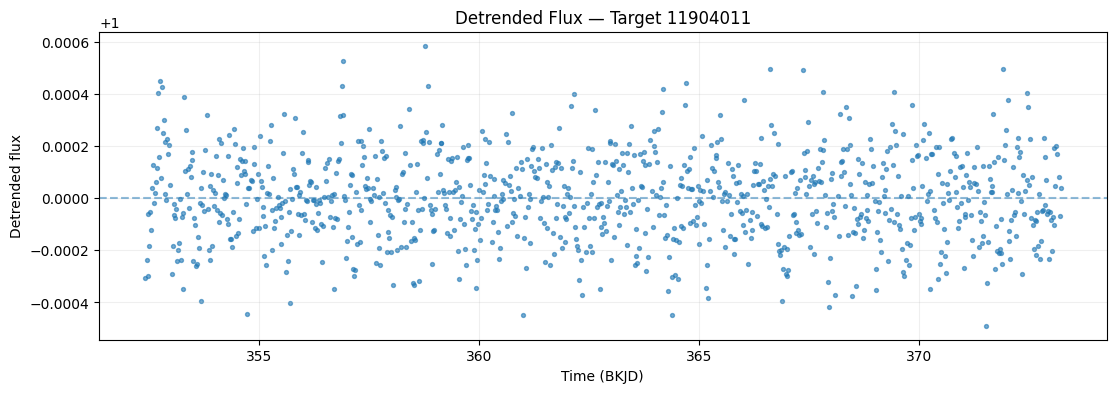

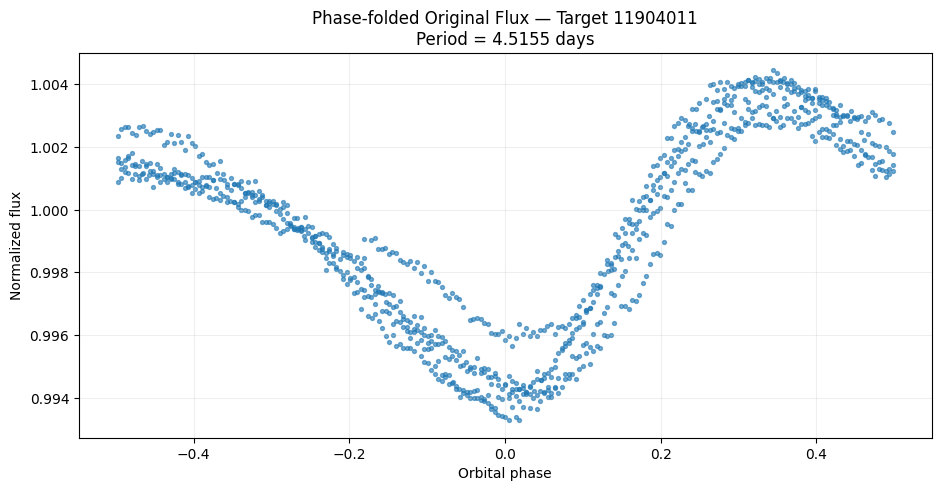

Target: 11904011
Period: 4.515503100620124
Duration (hours): 5.0
Depth (ppm): 5155.380823160639
BLS power: 0.03650486944959154


In [122]:

# Step 4.49: Visual review of Target 11904011

target_id = 11904011

raw_data = expanded_quality_versions["primary"][target_id]

time_review = np.asarray(raw_data["time"], dtype=float)
flux_review = np.asarray(raw_data["flux"], dtype=float)

flux_review = flux_review / np.nanmedian(flux_review)

valid = np.isfinite(time_review) & np.isfinite(flux_review)
time_review = time_review[valid]
flux_review = flux_review[valid]

order = np.argsort(time_review)
time_review = time_review[order]
flux_review = flux_review[order]

# Original normalized flux
plt.figure(figsize=(13, 4))
plt.scatter(time_review, flux_review, s=8, alpha=0.6)
plt.axhline(1.0, linestyle="--", alpha=0.5)
plt.xlabel("Time (BKJD)")
plt.ylabel("Normalized flux")
plt.title(f"Original PDCSAP Flux — Target {target_id}")
plt.grid(alpha=0.2)
plt.show()

# Detrended flux
processed = preprocessed_expanded["primary"][target_id]

plt.figure(figsize=(13, 4))
plt.scatter(
    processed["time"],
    processed["detrended_flux"],
    s=8,
    alpha=0.6
)
plt.axhline(1.0, linestyle="--", alpha=0.5)
plt.xlabel("Time (BKJD)")
plt.ylabel("Detrended flux")
plt.title(f"Detrended Flux — Target {target_id}")
plt.grid(alpha=0.2)
plt.show()

# Phase-folded original flux
row = bls_screening_df[
    bls_screening_df["Target_ID"] == target_id
].iloc[0]

period_review = row["Best_Period_days"]
epoch_review = row["Best_Epoch_BKJD"]

phase_review = (
    (time_review - epoch_review + period_review / 2)
    % period_review
) / period_review - 0.5

plt.figure(figsize=(11, 5))
plt.scatter(phase_review, flux_review, s=8, alpha=0.6)
plt.xlabel("Orbital phase")
plt.ylabel("Normalized flux")
plt.title(
    f"Phase-folded Original Flux — Target {target_id}\n"
    f"Period = {period_review:.4f} days"
)
plt.grid(alpha=0.2)
plt.show()

print("Target:", target_id)
print("Period:", period_review)
print("Duration (hours):", row["Best_Duration_hours"])
print("Depth (ppm):", row["Depth_ppm"])
print("BLS power:", row["BLS_Power"])


In [123]:

# Step 4.50: Add Target 11904011 to the review log

new_review = pd.DataFrame([{
    "Target_ID": 11904011,
    "Review_Status": "Unclassified",
    "Include_in_initial_training": False,
    "BLS_Period_days": 4.5155,
    "BLS_Duration_hours": 5.0,
    "BLS_Depth_ppm": 5155.4,
    "Original_signal_present": True,
    "Phase_fold_morphology": "Broad evolving periodic variation",
    "Double_period_result": "Not yet tested",
    "Reason": (
        "Broad smooth brightness variations dominate the light curve; "
        "no clear isolated transit morphology."
    )
}])

target_review_log = pd.concat(
    [target_review_log, new_review],
    ignore_index=True
)

display(target_review_log)


,Target_ID,Review_Status,Include_in_initial_training,BLS_Period_days,BLS_Duration_hours,BLS_Depth_ppm,Original_signal_present,Phase_fold_morphology,Double_period_result,Reason
0,11904038,Unclassified,False,0.632063,4.0,3082.988808,True,Broad smooth periodic variation,No clear distinct secondary eclipse,Periodic signal is not a clean isolated transi...
1,11904099,Unclassified,False,7.480096,5.0,8592.706563,True,Broad smooth variation,Not yet tested,Large-scale flux variation dominates the origi...
2,11904011,Unclassified,False,4.515500,5.0,5155.400000,True,Broad evolving periodic variation,Not yet tested,Broad smooth brightness variations dominate th...


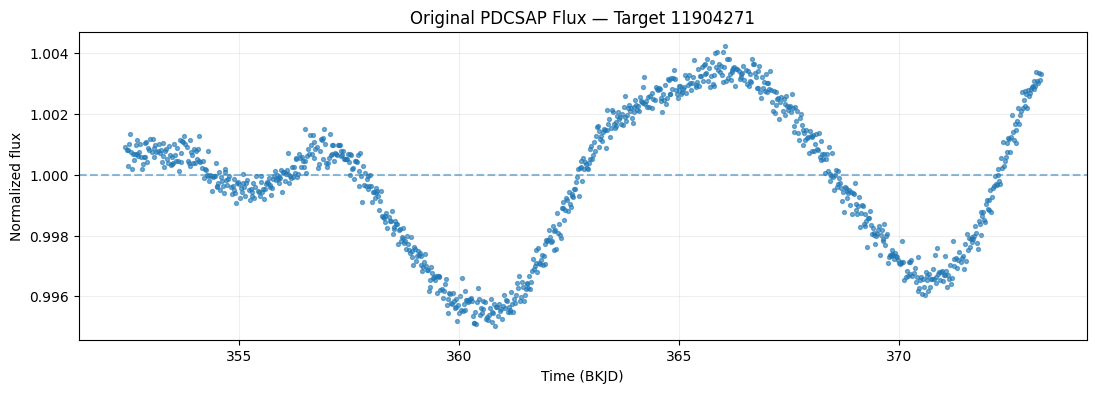

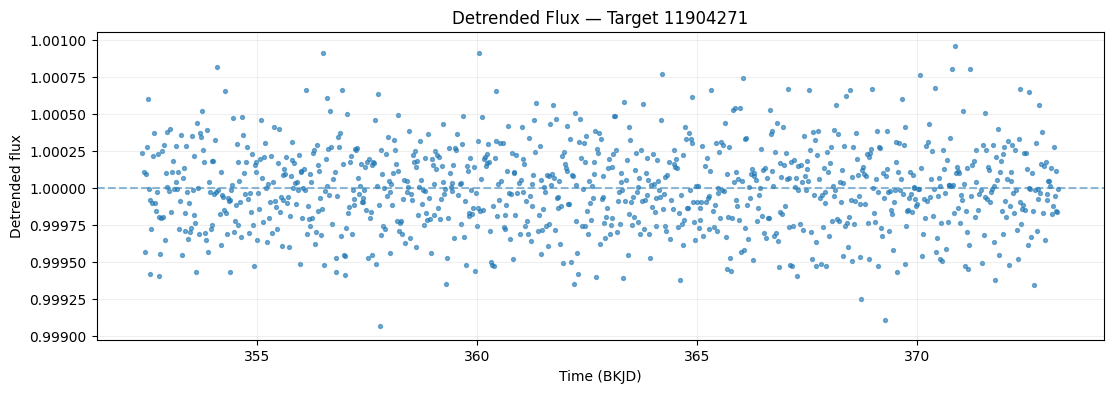

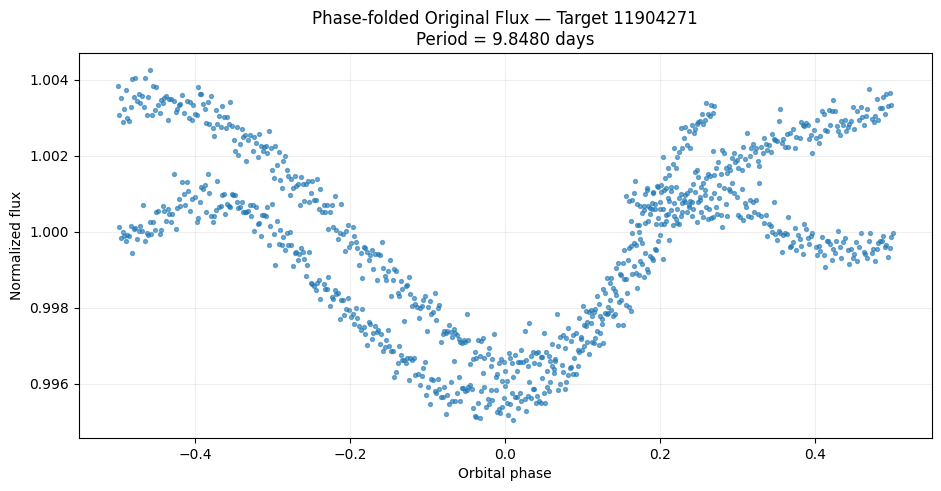

Target: 11904271
Period: 9.847969593918783
Duration (hours): 5.0
Depth (ppm): 3913.7056082225427
BLS power: 0.018152624969239438


In [124]:

# Step 4.51: Visual review of Target 11904271

target_id = 11904271

raw_data = expanded_quality_versions["primary"][target_id]

time_review = np.asarray(raw_data["time"], dtype=float)
flux_review = np.asarray(raw_data["flux"], dtype=float)

flux_review = flux_review / np.nanmedian(flux_review)

valid = np.isfinite(time_review) & np.isfinite(flux_review)
time_review = time_review[valid]
flux_review = flux_review[valid]

order = np.argsort(time_review)
time_review = time_review[order]
flux_review = flux_review[order]

# Original normalized flux
plt.figure(figsize=(13, 4))
plt.scatter(time_review, flux_review, s=8, alpha=0.6)
plt.axhline(1.0, linestyle="--", alpha=0.5)
plt.xlabel("Time (BKJD)")
plt.ylabel("Normalized flux")
plt.title(f"Original PDCSAP Flux — Target {target_id}")
plt.grid(alpha=0.2)
plt.show()

# Detrended flux
processed = preprocessed_expanded["primary"][target_id]

plt.figure(figsize=(13, 4))
plt.scatter(
    processed["time"],
    processed["detrended_flux"],
    s=8,
    alpha=0.6
)
plt.axhline(1.0, linestyle="--", alpha=0.5)
plt.xlabel("Time (BKJD)")
plt.ylabel("Detrended flux")
plt.title(f"Detrended Flux — Target {target_id}")
plt.grid(alpha=0.2)
plt.show()

# Phase-folded original flux
row = bls_screening_df[
    bls_screening_df["Target_ID"] == target_id
].iloc[0]

period_review = row["Best_Period_days"]
epoch_review = row["Best_Epoch_BKJD"]

phase_review = (
    (time_review - epoch_review + period_review / 2)
    % period_review
) / period_review - 0.5

plt.figure(figsize=(11, 5))
plt.scatter(phase_review, flux_review, s=8, alpha=0.6)
plt.xlabel("Orbital phase")
plt.ylabel("Normalized flux")
plt.title(
    f"Phase-folded Original Flux — Target {target_id}\n"
    f"Period = {period_review:.4f} days"
)
plt.grid(alpha=0.2)
plt.show()

print("Target:", target_id)
print("Period:", period_review)
print("Duration (hours):", row["Best_Duration_hours"])
print("Depth (ppm):", row["Depth_ppm"])
print("BLS power:", row["BLS_Power"])


In [125]:

# Step 4.52: Add Target 11904271 to the review log

new_review = pd.DataFrame([{
    "Target_ID": 11904271,
    "Review_Status": "Unclassified",
    "Include_in_initial_training": False,
    "BLS_Period_days": 9.847970,
    "BLS_Duration_hours": 5.0,
    "BLS_Depth_ppm": 3913.705608,
    "Original_signal_present": True,
    "Phase_fold_morphology": "Broad smooth periodic variation",
    "Double_period_result": "Not yet tested",
    "Reason": (
        "No clear isolated transit morphology; period and duration "
        "are at the upper boundaries of the BLS search grid."
    )
}])

target_review_log = pd.concat(
    [target_review_log, new_review],
    ignore_index=True
)

display(target_review_log)


,Target_ID,Review_Status,Include_in_initial_training,BLS_Period_days,BLS_Duration_hours,BLS_Depth_ppm,Original_signal_present,Phase_fold_morphology,Double_period_result,Reason
0,11904038,Unclassified,False,0.632063,4.0,3082.988808,True,Broad smooth periodic variation,No clear distinct secondary eclipse,Periodic signal is not a clean isolated transi...
1,11904099,Unclassified,False,7.480096,5.0,8592.706563,True,Broad smooth variation,Not yet tested,Large-scale flux variation dominates the origi...
2,11904011,Unclassified,False,4.515500,5.0,5155.400000,True,Broad evolving periodic variation,Not yet tested,Broad smooth brightness variations dominate th...
3,11904271,Unclassified,False,9.847970,5.0,3913.705608,True,Broad smooth periodic variation,Not yet tested,No clear isolated transit morphology; period a...


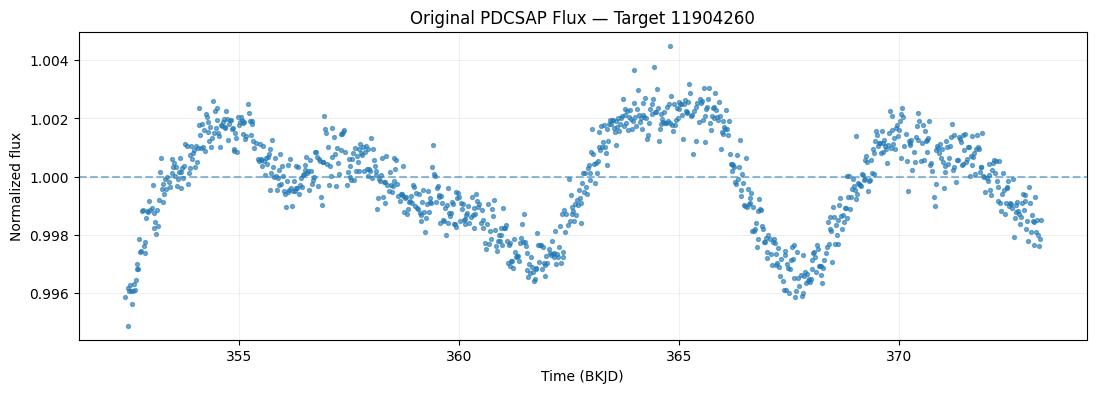

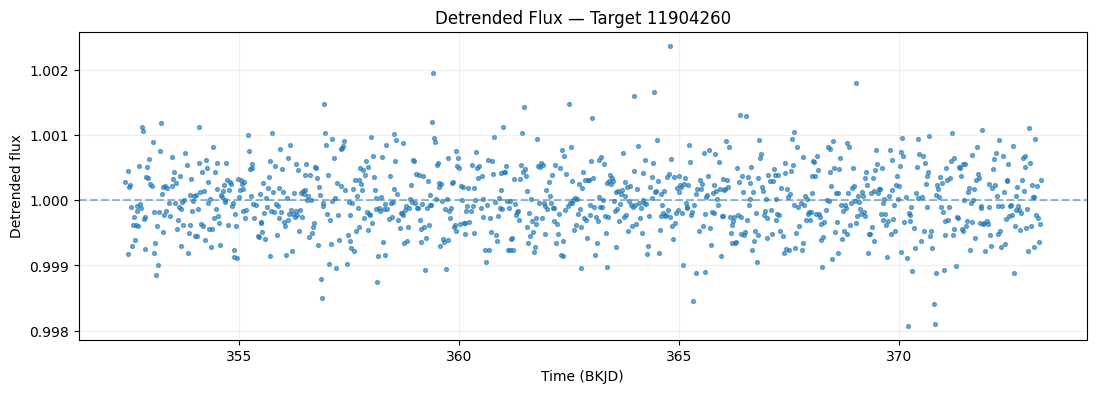

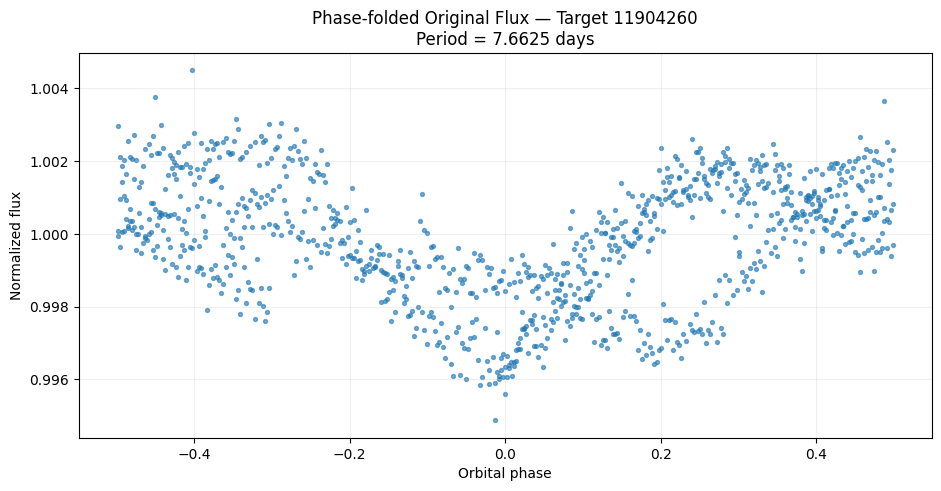

Target: 11904260
Period: 7.6625325065013
Duration (hours): 5.0
Depth (ppm): 2915.0485032279144
BLS power: 0.01621965825521418


In [126]:

# Step 4.53: Visual review of Target 11904260

target_id = 11904260

raw_data = expanded_quality_versions["primary"][target_id]

time_review = np.asarray(raw_data["time"], dtype=float)
flux_review = np.asarray(raw_data["flux"], dtype=float)

flux_review = flux_review / np.nanmedian(flux_review)

valid = np.isfinite(time_review) & np.isfinite(flux_review)
time_review = time_review[valid]
flux_review = flux_review[valid]

order = np.argsort(time_review)
time_review = time_review[order]
flux_review = flux_review[order]

# Original normalized flux
plt.figure(figsize=(13, 4))
plt.scatter(time_review, flux_review, s=8, alpha=0.6)
plt.axhline(1.0, linestyle="--", alpha=0.5)
plt.xlabel("Time (BKJD)")
plt.ylabel("Normalized flux")
plt.title(f"Original PDCSAP Flux — Target {target_id}")
plt.grid(alpha=0.2)
plt.show()

# Detrended flux
processed = preprocessed_expanded["primary"][target_id]

plt.figure(figsize=(13, 4))
plt.scatter(
    processed["time"],
    processed["detrended_flux"],
    s=8,
    alpha=0.6
)
plt.axhline(1.0, linestyle="--", alpha=0.5)
plt.xlabel("Time (BKJD)")
plt.ylabel("Detrended flux")
plt.title(f"Detrended Flux — Target {target_id}")
plt.grid(alpha=0.2)
plt.show()

# Phase-folded original flux
row = bls_screening_df[
    bls_screening_df["Target_ID"] == target_id
].iloc[0]

period_review = row["Best_Period_days"]
epoch_review = row["Best_Epoch_BKJD"]

phase_review = (
    (time_review - epoch_review + period_review / 2)
    % period_review
) / period_review - 0.5

plt.figure(figsize=(11, 5))
plt.scatter(phase_review, flux_review, s=8, alpha=0.6)
plt.xlabel("Orbital phase")
plt.ylabel("Normalized flux")
plt.title(
    f"Phase-folded Original Flux — Target {target_id}\n"
    f"Period = {period_review:.4f} days"
)
plt.grid(alpha=0.2)
plt.show()

print("Target:", target_id)
print("Period:", period_review)
print("Duration (hours):", row["Best_Duration_hours"])
print("Depth (ppm):", row["Depth_ppm"])
print("BLS power:", row["BLS_Power"])


In [127]:

# Step 4.54: Add Target 11904260 to the review log

new_review = pd.DataFrame([{
    "Target_ID": 11904260,
    "Review_Status": "Unclassified",
    "Include_in_initial_training": False,
    "BLS_Period_days": 7.662533,
    "BLS_Duration_hours": 5.0,
    "BLS_Depth_ppm": 2915.048503,
    "Original_signal_present": True,
    "Phase_fold_morphology": "Broad evolving variability with dispersed phase-folded structure",
    "Double_period_result": "Not yet tested",
    "Reason": (
        "No clear isolated transit morphology; broad brightness "
        "variations dominate and only about 2.7 cycles are observed."
    )
}])

target_review_log = pd.concat(
    [target_review_log, new_review],
    ignore_index=True
)

display(target_review_log)


,Target_ID,Review_Status,Include_in_initial_training,BLS_Period_days,BLS_Duration_hours,BLS_Depth_ppm,Original_signal_present,Phase_fold_morphology,Double_period_result,Reason
0,11904038,Unclassified,False,0.632063,4.0,3082.988808,True,Broad smooth periodic variation,No clear distinct secondary eclipse,Periodic signal is not a clean isolated transi...
1,11904099,Unclassified,False,7.480096,5.0,8592.706563,True,Broad smooth variation,Not yet tested,Large-scale flux variation dominates the origi...
2,11904011,Unclassified,False,4.515500,5.0,5155.400000,True,Broad evolving periodic variation,Not yet tested,Broad smooth brightness variations dominate th...
3,11904271,Unclassified,False,9.847970,5.0,3913.705608,True,Broad smooth periodic variation,Not yet tested,No clear isolated transit morphology; period a...
4,11904260,Unclassified,False,7.662533,5.0,2915.048503,True,Broad evolving variability with dispersed phas...,Not yet tested,No clear isolated transit morphology; broad br...


In [128]:

# Step 4.55: Verify the 50-target preprocessing dataset

print("Primary processed targets:",
      len(preprocessed_expanded["primary"]))

print("Expanded processed targets:",
      len(preprocessed_expanded["expanded"]))

print("\nExample target IDs:")
print(list(preprocessed_expanded["primary"].keys())[:10])

print("\nExample target data structure:")
example_id = list(preprocessed_expanded["primary"].keys())[0]
example = preprocessed_expanded["primary"][example_id]

print("Target ID:", example_id)
print("Time shape:", np.asarray(example["time"]).shape)
print("Flux shape:", np.asarray(example["detrended_flux"]).shape)
print("Finite flux values:",
      np.isfinite(example["detrended_flux"]).sum())


Primary processed targets: 50
Expanded processed targets: 50

Example target IDs:
[11904151, 11904148, 11904099, 11904085, 11904071, 11904090, 11904101, 11904249, 11904271, 11904260]

Example target data structure:
Target ID: 11904151
Time shape: (979,)
Flux shape: (979,)
Finite flux values: 979


In [129]:

# Step 4.56: Generate varied synthetic transit parameters

rng = np.random.default_rng(42)

injection_parameters = []

for target_id, data in preprocessed_expanded["primary"].items():

    time = np.asarray(data["time"], dtype=float)
    time = time[np.isfinite(time)]

    t_min = np.min(time)
    t_max = np.max(time)
    midpoint = (t_min + t_max) / 2

    # Draw varied synthetic transit parameters
    period = rng.uniform(2.0, 6.0)
    duration_hours = rng.uniform(2.0, 5.0)
    depth_ppm = rng.uniform(500, 2500)

    duration_days = duration_hours / 24

    # Place a reference transit near the middle of the observing baseline
    epoch = rng.uniform(
        midpoint - period / 2,
        midpoint + period / 2
    )

    # Count predicted transit centers within the observed time range
    first_event = int(np.ceil((t_min - epoch) / period))
    last_event = int(np.floor((t_max - epoch) / period))
    transit_count = max(0, last_event - first_event + 1)

    injection_parameters.append({
        "Target_ID": target_id,
        "Period_days": period,
        "Duration_hours": duration_hours,
        "Depth_ppm": depth_ppm,
        "Epoch_BKJD": epoch,
        "Transit_Count": transit_count,
        "Baseline_days": t_max - t_min
    })

injection_parameters_df = pd.DataFrame(injection_parameters)

print("Number of targets:", len(injection_parameters_df))
print("Targets with at least 3 predicted transits:",
      (injection_parameters_df["Transit_Count"] >= 3).sum())
print("Minimum predicted transit count:",
      injection_parameters_df["Transit_Count"].min())

display(
    injection_parameters_df.round(4)
)

# Check parameter diversity
print("\nParameter ranges:")
display(
    injection_parameters_df[
        ["Period_days", "Duration_hours", "Depth_ppm", "Transit_Count"]
    ].describe().round(3)
)


Number of targets: 50
Targets with at least 3 predicted transits: 50
Minimum predicted transit count: 4


,Target_ID,Period_days,Duration_hours,Depth_ppm,Epoch_BKJD,Transit_Count,Baseline_days
0,11904151,5.0958,3.3166,2217.1958,363.8140,4,20.8215
1,11904148,2.3767,4.9269,2022.2794,363.4882,9,20.8215
2,11904099,2.5125,3.3512,1241.5960,363.8805,8,20.8215
3,11904085,4.5755,4.4683,1386.8284,361.5603,5,20.8215
4,11904071,4.2183,2.1915,2155.2623,363.3637,5,20.8215
5,11904090,5.0324,3.0636,2441.3960,364.7866,4,20.8215
6,11904101,5.1135,2.5839,1433.4420,360.4755,4,20.8215
7,11904249,2.6172,4.0491,1989.5243,364.0318,8,20.8215
8,11904271,3.3033,3.1114,1439.1116,361.7825,6,20.8215
9,11904260,2.5197,3.4271,953.8187,363.2362,8,20.8215



Parameter ranges:


,Period_days,Duration_hours,Depth_ppm,Transit_Count
count,50.000,50.000,50.000,50.000
mean,3.873,3.652,1443.654,5.820
std,1.117,0.788,550.146,1.859
min,2.091,2.065,616.605,4.000
25%,2.740,3.120,935.332,4.000
50%,3.865,3.661,1392.776,5.000
75%,4.923,4.156,1951.672,7.750
max,5.834,4.977,2441.396,10.000


In [130]:
# Find DataFrames containing the required injection parameters

required_columns = {
    "Target_ID",
    "Period_days",
    "Duration_hours",
    "Depth_ppm",
    "Epoch_BKJD"
}

candidate_tables = []

for name, obj in globals().copy().items():
    if isinstance(obj, pd.DataFrame):
        if required_columns.issubset(set(obj.columns)):
            candidate_tables.append((name, obj))

print("Matching parameter tables:", len(candidate_tables))

for name, df in candidate_tables:
    print("\nDataFrame variable:", name)
    print("Shape:", df.shape)
    print("Columns:", df.columns.tolist())
    print("Unique targets:", df["Target_ID"].nunique())
    print("Missing parameter values:")
    print(df[list(required_columns)].isna().sum())

print("\nPreprocessed data:")
print("Primary targets:", len(preprocessed_expanded["primary"]))
print("Expanded targets:", len(preprocessed_expanded["expanded"]))

Matching parameter tables: 1

DataFrame variable: injection_parameters_df
Shape: (50, 7)
Columns: ['Target_ID', 'Period_days', 'Duration_hours', 'Depth_ppm', 'Epoch_BKJD', 'Transit_Count', 'Baseline_days']
Unique targets: 50
Missing parameter values:
Epoch_BKJD        0
Depth_ppm         0
Target_ID         0
Duration_hours    0
Period_days       0
dtype: int64

Preprocessed data:
Primary targets: 50
Expanded targets: 50


In [131]:

# Step 4.42: Construct paired synthetic transit injections

paired_injection_dataset = {}
injection_validation = []

for _, params in injection_parameters_df.iterrows():

    target_id = int(params["Target_ID"])

    # Retrieve the primary preprocessed light curve
    data = preprocessed_expanded["primary"][target_id]

    time = np.asarray(data["time"], dtype=float)
    control_flux = np.asarray(data["detrended_flux"], dtype=float)

    # Validate input arrays
    valid = np.isfinite(time) & np.isfinite(control_flux)
    time = time[valid]
    control_flux = control_flux[valid]

    order = np.argsort(time)
    time = time[order]
    control_flux = control_flux[order]

    # Retrieve synthetic transit parameters
    period = float(params["Period_days"])
    duration_days = float(params["Duration_hours"]) / 24
    depth = float(params["Depth_ppm"]) * 1e-6
    epoch = float(params["Epoch_BKJD"])

    # Calculate distance from the nearest predicted transit center
    phase_time = (
        (time - epoch + period / 2) % period
    ) - period / 2

    # Identify observations inside the synthetic transit
    in_transit = np.abs(phase_time) <= duration_days / 2

    # Apply a box-shaped transit to a copy of the original flux
    injected_flux = control_flux.copy()
    injected_flux[in_transit] *= (1 - depth)

    # Store matched control and injected samples
    paired_injection_dataset[target_id] = {
        "time": time,
        "control_flux": control_flux.copy(),
        "injected_flux": injected_flux,
        "in_transit_mask": in_transit,
        "period_days": period,
        "duration_hours": duration_days * 24,
        "depth_ppm": depth * 1e6,
        "epoch_bkjd": epoch
    }

    injection_validation.append({
        "Target_ID": target_id,
        "Observations": len(time),
        "Injected_observations": int(in_transit.sum()),
        "Control_samples": 1,
        "Positive_samples": 1,
        "Expected_depth_ppm": depth * 1e6,
        "Measured_injected_depth_ppm": (
            (np.median(control_flux[in_transit]) -
             np.median(injected_flux[in_transit])) * 1e6
            if in_transit.any() else np.nan
        )
    })

injection_validation_df = pd.DataFrame(injection_validation)

print("Targets processed:", len(paired_injection_dataset))
print("Total paired samples:", 2 * len(paired_injection_dataset))
print("Targets with injected observations:",
      (injection_validation_df["Injected_observations"] > 0).sum())
print("Targets without injected observations:",
      (injection_validation_df["Injected_observations"] == 0).sum())
print("Total injected observations:",
      injection_validation_df["Injected_observations"].sum())

display(injection_validation_df.round(3))


Targets processed: 50
Total paired samples: 100
Targets with injected observations: 50
Targets without injected observations: 0
Total injected observations: 2146


,Target_ID,Observations,Injected_observations,Control_samples,Positive_samples,Expected_depth_ppm,Measured_injected_depth_ppm
0,11904151,979,28,1,1,2217.196,2217.185
1,11904148,989,89,1,1,2022.279,2022.102
2,11904099,993,54,1,1,1241.596,1241.591
3,11904085,957,38,1,1,1386.828,1386.802
4,11904071,995,22,1,1,2155.262,2155.042
5,11904090,998,25,1,1,2441.396,2441.350
6,11904101,993,20,1,1,1433.442,1433.459
7,11904249,986,64,1,1,1989.524,1989.560
8,11904271,994,37,1,1,1439.112,1439.075
9,11904260,984,52,1,1,953.819,953.656


In [132]:

# Step 4.43: Create local phase-folded paired samples

N_BINS = 24
PHASE_MIN = -2.0
PHASE_MAX = 2.0
bin_edges = np.linspace(PHASE_MIN, PHASE_MAX, N_BINS + 1)

X_phase = []
y_phase = []
group_ids = []
phase_bin_counts = []
phase_metadata = []

for target_id, sample in paired_injection_dataset.items():

    time = sample["time"]
    period = sample["period_days"]
    epoch = sample["epoch_bkjd"]
    duration_days = sample["duration_hours"] / 24

    # Centered phase, expressed in units of transit duration
    phase_days = (
        (time - epoch + period / 2) % period
    ) - period / 2

    scaled_phase = phase_days / duration_days

    # Keep the local window from -2 to +2 transit durations
    in_window = (
        (scaled_phase >= PHASE_MIN) &
        (scaled_phase <= PHASE_MAX)
    )

    local_phase = scaled_phase[in_window]

    # Assign observations to 24 bins
    bin_indices = np.floor(
        (local_phase - PHASE_MIN) /
        (PHASE_MAX - PHASE_MIN) * N_BINS
    ).astype(int)

    # Include the rightmost edge in the final bin
    bin_indices = np.clip(bin_indices, 0, N_BINS - 1)

    for label, flux_key in [
        (0, "control_flux"),
        (1, "injected_flux")
    ]:

        local_flux = sample[flux_key][in_window]

        binned_flux = np.full(N_BINS, np.nan)
        bin_counts = np.zeros(N_BINS, dtype=int)

        for bin_number in range(N_BINS):
            values = local_flux[bin_indices == bin_number]

            bin_counts[bin_number] = len(values)

            if len(values) > 0:
                binned_flux[bin_number] = np.median(values)

        X_phase.append(binned_flux)
        y_phase.append(label)
        group_ids.append(target_id)

        phase_bin_counts.append(bin_counts)

        phase_metadata.append({
            "Target_ID": target_id,
            "Label": label,
            "Occupied_bins": int(np.sum(bin_counts > 0)),
            "Empty_bins": int(np.sum(bin_counts == 0)),
            "Local_observations": int(len(local_flux))
        })

X_phase = np.asarray(X_phase, dtype=float)
y_phase = np.asarray(y_phase, dtype=int)
group_ids = np.asarray(group_ids)
phase_bin_counts = np.asarray(phase_bin_counts)

phase_metadata_df = pd.DataFrame(phase_metadata)

print("Phase-folded dataset shape:", X_phase.shape)
print("Labels shape:", y_phase.shape)
print("Group IDs shape:", group_ids.shape)
print("Bin-count array shape:", phase_bin_counts.shape)

print("\nClass counts:")
print(pd.Series(y_phase).value_counts().sort_index())

print("\nTotal empty bins:", np.isnan(X_phase).sum())
print("Samples with at least one empty bin:",
      np.isnan(X_phase).any(axis=1).sum())

print("\nOccupied-bin summary:")
display(
    phase_metadata_df.groupby("Label")[
        ["Occupied_bins", "Empty_bins", "Local_observations"]
    ].describe().round(2)
)

print("\nFirst 10 sample records:")
display(phase_metadata_df.head(10))


Phase-folded dataset shape: (100, 24)
Labels shape: (100,)
Group IDs shape: (100,)
Bin-count array shape: (100, 24)

Class counts:
0    50
1    50
Name: count, dtype: int64

Total empty bins: 0
Samples with at least one empty bin: 0

Occupied-bin summary:


Occupied_bins                                          Empty_bins       \
              count  mean  std   min   25%   50%   75%   max      count mean   
Label                                                                          
0              50.0  24.0  0.0  24.0  24.0  24.0  24.0  24.0       50.0  0.0   
1              50.0  24.0  0.0  24.0  24.0  24.0  24.0  24.0       50.0  0.0   

       ...           Local_observations                                      \
       ...  75%  max              count    mean    std   min     25%    50%   
Label  ...                                                                    
0      ...  0.0  0.0               50.0  169.84  69.79  74.0  111.25  146.0   
1      ...  0.0  0.0               50.0  169.84  69.79  74.0  111.25  146.0   

                     
         75%    max  
Label                
0      223.0  342.0  
1      223.0  342.0  

[2 rows x 24 columns]


First 10 sample records:


,Target_ID,Label,Occupied_bins,Empty_bins,Local_observations
0,11904151,0,24,0,105
1,11904151,1,24,0,105
2,11904148,0,24,0,342
3,11904148,1,24,0,342
4,11904099,0,24,0,211
5,11904099,1,24,0,211
6,11904085,0,24,0,151
7,11904085,1,24,0,151
8,11904071,0,24,0,90
9,11904071,1,24,0,90


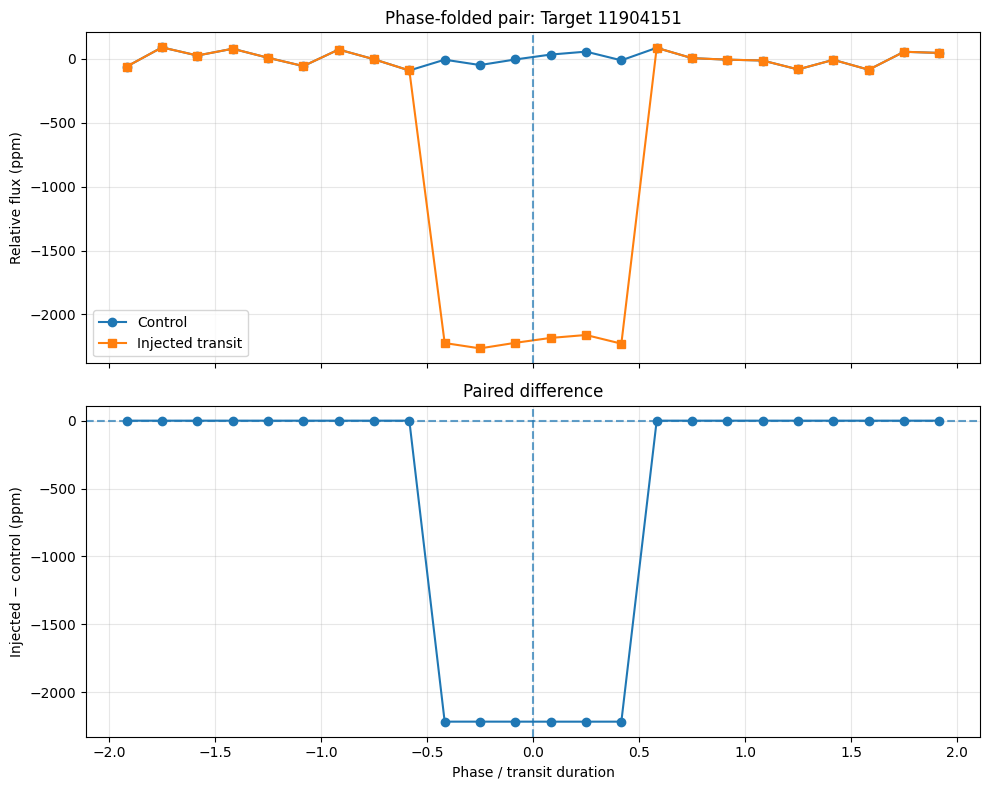

Target: 11904151
Expected injected depth (ppm): 2217.195839822765
Median paired difference (ppm): 0.0
Minimum paired difference (ppm): -2217.3204486508616


In [133]:

# Step 4.44: Compare one control/injected pair

target_to_plot = 11904151

control_idx = np.where(
    (group_ids == target_to_plot) & (y_phase == 0)
)[0][0]

injected_idx = np.where(
    (group_ids == target_to_plot) & (y_phase == 1)
)[0][0]

bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2

control_ppm = (X_phase[control_idx] - 1) * 1e6
injected_ppm = (X_phase[injected_idx] - 1) * 1e6

difference_ppm = injected_ppm - control_ppm

fig, axes = plt.subplots(2, 1, figsize=(10, 8), sharex=True)

axes[0].plot(
    bin_centers, control_ppm,
    marker="o", label="Control"
)
axes[0].plot(
    bin_centers, injected_ppm,
    marker="s", label="Injected transit"
)
axes[0].axvline(0, linestyle="--", alpha=0.7)
axes[0].set_ylabel("Relative flux (ppm)")
axes[0].set_title(f"Phase-folded pair: Target {target_to_plot}")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(
    bin_centers, difference_ppm,
    marker="o"
)
axes[1].axhline(0, linestyle="--", alpha=0.7)
axes[1].axvline(0, linestyle="--", alpha=0.7)
axes[1].set_xlabel("Phase / transit duration")
axes[1].set_ylabel("Injected − control (ppm)")
axes[1].set_title("Paired difference")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

print("Target:", target_to_plot)
print("Expected injected depth (ppm):",
      paired_injection_dataset[target_to_plot]["depth_ppm"])
print("Median paired difference (ppm):",
      np.median(difference_ppm))
print("Minimum paired difference (ppm):",
      np.min(difference_ppm))


In [134]:

# Step 4.45: Group-aware train/validation/test split

rng = np.random.default_rng(42)

# Get unique target IDs and shuffle them
unique_target_ids = np.array(sorted(np.unique(group_ids)))
shuffled_target_ids = rng.permutation(unique_target_ids)

# Split by target, not by individual sample
train_target_ids = shuffled_target_ids[:35]
val_target_ids = shuffled_target_ids[35:42]
test_target_ids = shuffled_target_ids[42:50]

# Convert target assignments into sample indices
train_idx = np.where(np.isin(group_ids, train_target_ids))[0]
val_idx = np.where(np.isin(group_ids, val_target_ids))[0]
test_idx = np.where(np.isin(group_ids, test_target_ids))[0]

# Create dataset partitions
X_train = X_phase[train_idx]
y_train = y_phase[train_idx]

X_val = X_phase[val_idx]
y_val = y_phase[val_idx]

X_test = X_phase[test_idx]
y_test = y_phase[test_idx]

groups_train = group_ids[train_idx]
groups_val = group_ids[val_idx]
groups_test = group_ids[test_idx]

# Verify that no target appears in multiple partitions
train_groups = set(groups_train)
val_groups = set(groups_val)
test_groups = set(groups_test)

assert train_groups.isdisjoint(val_groups)
assert train_groups.isdisjoint(test_groups)
assert val_groups.isdisjoint(test_groups)

# Verify expected sample and class counts
assert len(train_idx) == 70
assert len(val_idx) == 14
assert len(test_idx) == 16

assert np.sum(y_train == 0) == np.sum(y_train == 1) == 35
assert np.sum(y_val == 0) == np.sum(y_val == 1) == 7
assert np.sum(y_test == 0) == np.sum(y_test == 1) == 8

print("TRAINING")
print("Targets:", len(train_groups))
print("Samples:", len(X_train))
print("Class counts:", np.bincount(y_train))

print("\nVALIDATION")
print("Targets:", len(val_groups))
print("Samples:", len(X_val))
print("Class counts:", np.bincount(y_val))

print("\nTEST")
print("Targets:", len(test_groups))
print("Samples:", len(X_test))
print("Class counts:", np.bincount(y_test))

print("\nGROUP LEAKAGE CHECK")
print("Train/validation overlap:", train_groups & val_groups)
print("Train/test overlap:", train_groups & test_groups)
print("Validation/test overlap:", val_groups & test_groups)

print("\nAll split checks passed.")


TRAINING
Targets: 35
Samples: 70
Class counts: [35 35]

VALIDATION
Targets: 7
Samples: 14
Class counts: [7 7]

TEST
Targets: 8
Samples: 16
Class counts: [8 8]

GROUP LEAKAGE CHECK
Train/validation overlap: set()
Train/test overlap: set()
Validation/test overlap: set()

All split checks passed.


In [135]:

# Step 4.46: Convert flux into scaled ppm and prepare CNN inputs

def prepare_cnn_input(X):
    # Convert normalized flux to units of 1000 ppm
    X_scaled = ((X - 1.0) * 1e6) / 1000.0

    # Add the channel dimension: (samples, bins, channels)
    X_scaled = X_scaled[..., np.newaxis]

    return X_scaled.astype(np.float32)


X_train_cnn = prepare_cnn_input(X_train)
X_val_cnn = prepare_cnn_input(X_val)
X_test_cnn = prepare_cnn_input(X_test)

print("CNN input shapes:")
print("Training:", X_train_cnn.shape)
print("Validation:", X_val_cnn.shape)
print("Testing:", X_test_cnn.shape)

print("\nData type:", X_train_cnn.dtype)

print("\nTraining feature statistics:")
print("Minimum:", np.min(X_train_cnn))
print("Maximum:", np.max(X_train_cnn))
print("Mean:", np.mean(X_train_cnn))
print("Standard deviation:", np.std(X_train_cnn))

print("\nNaN check:")
print("Training:", np.isnan(X_train_cnn).sum())
print("Validation:", np.isnan(X_val_cnn).sum())
print("Testing:", np.isnan(X_test_cnn).sum())

print("\nLabel distributions:")
print("Training:", np.bincount(y_train))
print("Validation:", np.bincount(y_val))
print("Testing:", np.bincount(y_test))


CNN input shapes:
Training: (70, 24, 1)
Validation: (14, 24, 1)
Testing: (16, 24, 1)

Data type: float32

Training feature statistics:
Minimum: -2.9058785
Maximum: 0.8968412
Mean: -0.18706349
Standard deviation: 0.56182814

NaN check:
Training: 0
Validation: 0
Testing: 0

Label distributions:
Training: [35 35]
Validation: [7 7]
Testing: [8 8]


In [136]:

# Step 4.47: Logistic Regression baseline

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

# Remove the CNN channel dimension
X_train_flat = X_train_cnn.squeeze(-1)
X_val_flat = X_val_cnn.squeeze(-1)

# Build baseline pipeline
baseline_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ))
])

# Train using training data only
baseline_model.fit(X_train_flat, y_train)

# Predict validation samples
val_predictions = baseline_model.predict(X_val_flat)
val_probabilities = baseline_model.predict_proba(X_val_flat)[:, 1]

# Evaluate validation performance
print("LOGISTIC REGRESSION — VALIDATION RESULTS")
print("----------------------------------------")

print("Accuracy:",
      accuracy_score(y_val, val_predictions))

print("Precision:",
      precision_score(y_val, val_predictions, zero_division=0))

print("Recall:",
      recall_score(y_val, val_predictions, zero_division=0))

print("F1-score:",
      f1_score(y_val, val_predictions, zero_division=0))

print("ROC-AUC:",
      roc_auc_score(y_val, val_probabilities))

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, val_predictions))

print("\nClassification Report:")
print(classification_report(
    y_val,
    val_predictions,
    target_names=["Control", "Injected transit"],
    zero_division=0
))


LOGISTIC REGRESSION — VALIDATION RESULTS
----------------------------------------
Accuracy: 1.0
Precision: 1.0
Recall: 1.0
F1-score: 1.0
ROC-AUC: 1.0

Confusion Matrix:
[[7 0]
 [0 7]]

Classification Report:
                  precision    recall  f1-score   support

         Control       1.00      1.00      1.00         7
Injected transit       1.00      1.00      1.00         7

        accuracy                           1.00        14
       macro avg       1.00      1.00      1.00        14
    weighted avg       1.00      1.00      1.00        14



In [137]:

# Step 4.48: Inspect validation prediction probabilities

validation_results = pd.DataFrame({
    "Target_ID": groups_val,
    "Actual_Label": y_val,
    "Predicted_Label": val_predictions,
    "Control_Probability": baseline_model.predict_proba(
        X_val_flat
    )[:, 0],
    "Injected_Probability": val_probabilities
})

validation_results = validation_results.sort_values(
    ["Target_ID", "Actual_Label"]
).reset_index(drop=True)

display(validation_results.round(4))

print("\nPrediction confidence summary:")
print(
    validation_results.groupby("Actual_Label")[
        "Injected_Probability"
    ].describe().round(4)
)

print("\nMinimum predicted probability for injected samples:",
      validation_results.loc[
          validation_results["Actual_Label"] == 1,
          "Injected_Probability"
      ].min())

print("Maximum predicted probability for control samples:",
      validation_results.loc[
          validation_results["Actual_Label"] == 0,
          "Injected_Probability"
      ].max())


,Target_ID,Actual_Label,Predicted_Label,Control_Probability,Injected_Probability
0,11853779,0,0,0.9739,0.0261
1,11853779,1,1,0.0927,0.9073
2,11854129,0,0,0.9772,0.0228
3,11854129,1,1,0.1969,0.8031
4,11904011,0,0,0.9823,0.0177
5,11904011,1,1,0.0913,0.9087
6,11904038,0,0,0.9935,0.0065
7,11904038,1,1,0.0018,0.9982
8,11904151,0,0,0.9804,0.0196
9,11904151,1,1,0.0000,1.0000



Prediction confidence summary:
              count    mean     std     min     25%     50%     75%     max
Actual_Label                                                               
0               7.0  0.0224  0.0097  0.0065  0.0187  0.0228  0.0259  0.0384
1               7.0  0.9265  0.0697  0.8031  0.9029  0.9087  0.9840  1.0000

Minimum predicted probability for injected samples: 0.803105019088285
Maximum predicted probability for control samples: 0.03842463198376981


In [138]:

# Step 4.49: Build and train a small 1D CNN

import tensorflow as tf
from tensorflow.keras import layers, models, callbacks

# Reproducibility
tf.keras.utils.set_random_seed(42)

# Define a small CNN
cnn_model = models.Sequential([
    layers.Input(shape=(24, 1)),

    layers.Conv1D(
        filters=8,
        kernel_size=3,
        activation="relu",
        padding="same"
    ),

    layers.GlobalAveragePooling1D(),

    layers.Dense(8, activation="relu"),

    layers.Dropout(0.25),

    layers.Dense(1, activation="sigmoid")
])

cnn_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=["accuracy", tf.keras.metrics.AUC(name="auc")]
)

cnn_model.summary()

# Stop training when validation loss stops improving
early_stopping = callbacks.EarlyStopping(
    monitor="val_loss",
    patience=12,
    restore_best_weights=True
)

# Train only on training data; use validation for monitoring
history = cnn_model.fit(
    X_train_cnn,
    y_train,
    validation_data=(X_val_cnn, y_val),
    epochs=100,
    batch_size=8,
    callbacks=[early_stopping],
    verbose=1
)

print("\nTraining stopped after:",
      len(history.history["loss"]), "epochs")

print("Best validation loss:",
      min(history.history["val_loss"]))

print("Best validation accuracy:",
      max(history.history["val_accuracy"]))


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 24, 8)          │            32 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d        │ (None, 8)              │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 8)              │            72 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 8)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 113 (452.00 B)

 Trainable params: 113 (452.00 B)

 Non-trainable params: 0 (0.00 B)

Epoch 1/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 4s 84ms/step - accuracy: 0.5000 - auc: 0.9808 - loss: 0.6454 - val_accuracy: 0.5000 - val_auc: 0.9082 - val_loss: 0.6558
Epoch 2/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - accuracy: 0.5000 - auc: 0.9669 - loss: 0.6451 - val_accuracy: 0.5000 - val_auc: 0.9184 - val_loss: 0.6505
Epoch 3/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.5143 - auc: 0.9641 - loss: 0.6406 - val_accuracy: 0.5000 - val_auc: 0.9184 - val_loss: 0.6456
Epoch 4/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.5000 - auc: 0.9833 - loss: 0.6247 - val_accuracy: 0.5000 - val_auc: 0.9184 - val_loss: 0.6406
Epoch 5/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - accuracy: 0.5571 - auc: 0.9849 - loss: 0.6204 - val_accuracy: 0.5000 - val_auc: 0.9286 - val_loss: 0.6347
Epoch 6/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - accuracy: 0.5286 - auc: 0.9873 - loss: 0.6188 - val_accuracy: 0.7143 - val_auc: 0.9796 - val_loss: 0.6284
Epoch 7/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - 

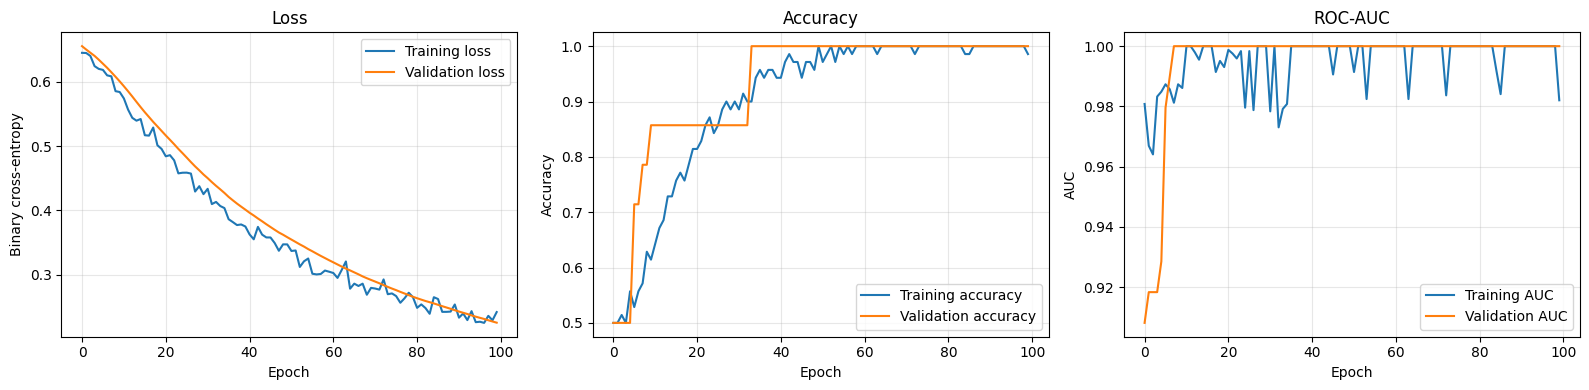

Best validation-loss epoch: 100
Best validation loss: 0.22516100108623505
Final validation loss: 0.22516100108623505
Final training loss: 0.24169398844242096


In [139]:

# Step 4.50: Plot CNN learning curves

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

# Loss
axes[0].plot(history.history["loss"], label="Training loss")
axes[0].plot(history.history["val_loss"], label="Validation loss")
axes[0].set_title("Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Binary cross-entropy")
axes[0].legend()
axes[0].grid(alpha=0.3)

# Accuracy
axes[1].plot(history.history["accuracy"], label="Training accuracy")
axes[1].plot(history.history["val_accuracy"], label="Validation accuracy")
axes[1].set_title("Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid(alpha=0.3)

# AUC
axes[2].plot(history.history["auc"], label="Training AUC")
axes[2].plot(history.history["val_auc"], label="Validation AUC")
axes[2].set_title("ROC-AUC")
axes[2].set_xlabel("Epoch")
axes[2].set_ylabel("AUC")
axes[2].legend()
axes[2].grid(alpha=0.3)

plt.tight_layout()
plt.show()

best_epoch = np.argmin(history.history["val_loss"]) + 1

print("Best validation-loss epoch:", best_epoch)
print("Best validation loss:", min(history.history["val_loss"]))
print("Final validation loss:", history.history["val_loss"][-1])
print("Final training loss:", history.history["loss"][-1])


In [142]:
from sklearn.metrics import accuracy_score, roc_auc_score
import numpy as np
import pandas as pd

noise_levels_ppm = [0, 100, 250, 500, 1000, 2000]

rng = np.random.default_rng(42)

noise_results = []

val_groups = group_ids[val_idx]

# Generate one fixed noise pattern per target.
# The same pattern is applied to its control and injected samples.
base_noise = {
    target_id: rng.normal(0, 1, X_val.shape[1])
    for target_id in np.unique(val_groups)
}

for noise_ppm in noise_levels_ppm:

    X_val_noisy = X_val.copy()

    for target_id in np.unique(val_groups):

        target_mask = val_groups == target_id

        noise = base_noise[target_id] * (noise_ppm / 1e6)

        X_val_noisy[target_mask] += noise

    # CNN evaluation
    X_val_noisy_cnn = prepare_cnn_input(X_val_noisy)

    cnn_prob = cnn_model.predict(
        X_val_noisy_cnn,
        verbose=0
    ).ravel()

    cnn_pred = (cnn_prob >= 0.5).astype(int)

    # Logistic Regression evaluation
    lr_prob = lr_model.predict_proba(X_val_noisy)[:, 1]
    lr_pred = (lr_prob >= 0.5).astype(int)

    noise_results.append({
        "Noise_ppm": noise_ppm,
        "CNN_Accuracy": accuracy_score(y_val, cnn_pred),
        "CNN_ROC_AUC": roc_auc_score(y_val, cnn_prob),
        "LR_Accuracy": accuracy_score(y_val, lr_pred),
        "LR_ROC_AUC": roc_auc_score(y_val, lr_prob)
    })

noise_results_df = pd.DataFrame(noise_results)

display(noise_results_df)

,Noise_ppm,CNN_Accuracy,CNN_ROC_AUC,LR_Accuracy,LR_ROC_AUC
0,0,1.000000,1.000000,1.000000,1.000000
1,100,1.000000,1.000000,1.000000,1.000000
2,250,0.928571,1.000000,1.000000,1.000000
3,500,0.714286,1.000000,0.928571,1.000000
4,1000,0.571429,0.897959,0.785714,0.918367
5,2000,0.500000,0.795918,0.785714,0.755102


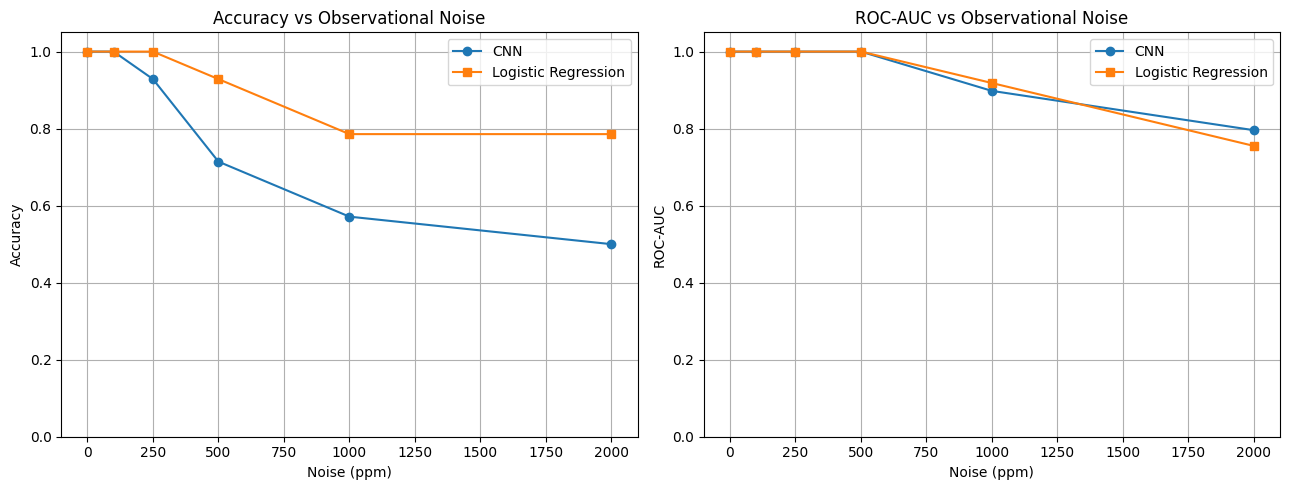

In [143]:

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Accuracy comparison
axes[0].plot(
    noise_results_df["Noise_ppm"],
    noise_results_df["CNN_Accuracy"],
    marker="o",
    label="CNN"
)

axes[0].plot(
    noise_results_df["Noise_ppm"],
    noise_results_df["LR_Accuracy"],
    marker="s",
    label="Logistic Regression"
)

axes[0].set_title("Accuracy vs Observational Noise")
axes[0].set_xlabel("Noise (ppm)")
axes[0].set_ylabel("Accuracy")
axes[0].set_ylim(0, 1.05)
axes[0].grid(True)
axes[0].legend()

# ROC-AUC comparison
axes[1].plot(
    noise_results_df["Noise_ppm"],
    noise_results_df["CNN_ROC_AUC"],
    marker="o",
    label="CNN"
)

axes[1].plot(
    noise_results_df["Noise_ppm"],
    noise_results_df["LR_ROC_AUC"],
    marker="s",
    label="Logistic Regression"
)

axes[1].set_title("ROC-AUC vs Observational Noise")
axes[1].set_xlabel("Noise (ppm)")
axes[1].set_ylabel("ROC-AUC")
axes[1].set_ylim(0, 1.05)
axes[1].grid(True)
axes[1].legend()

plt.tight_layout()
plt.show()

In [144]:
print("Training dataset shape:", X_train.shape)
print("Training labels:", np.unique(y_train, return_counts=True))

print("\nValidation dataset shape:", X_val.shape)
print("Validation labels:", np.unique(y_val, return_counts=True))

print("\nCNN input shape:", X_train_cnn.shape)

print("\nIndependent training targets:", len(np.unique(group_ids[train_idx])))
print("Independent validation targets:", len(np.unique(group_ids[val_idx])))


Training dataset shape: (70, 24)
Training labels: (array([0, 1]), array([35, 35]))

Validation dataset shape: (14, 24)
Validation labels: (array([0, 1]), array([7, 7]))

CNN input shape: (70, 24, 1)

Independent training targets: 35
Independent validation targets: 7


In [145]:
import numpy as np
import tensorflow as tf
from tensorflow.keras import layers, models, callbacks

# Preserve the original model for later comparison
original_cnn_model = cnn_model

rng = np.random.default_rng(42)

train_groups = group_ids[train_idx]

# Keep the original clean training samples
X_augmented_list = [X_train.copy()]
y_augmented_list = [y_train.copy()]

# Generate two independently augmented copies
for augmentation_round in range(2):

    X_noisy = X_train.copy()

    for target_id in np.unique(train_groups):

        target_mask = train_groups == target_id

        # Random noise level between 100 and 1000 ppm
        noise_ppm = rng.uniform(100, 1000)

        # One noise realization shared by both paired samples
        noise = rng.normal(
            loc=0,
            scale=noise_ppm * 1e-6,
            size=X_train.shape[1]
        )

        X_noisy[target_mask] += noise

    X_augmented_list.append(X_noisy)
    y_augmented_list.append(y_train.copy())

# Combine clean and augmented samples
X_train_augmented = np.concatenate(
    X_augmented_list,
    axis=0
)

y_train_augmented = np.concatenate(
    y_augmented_list,
    axis=0
)

# Prepare CNN input
X_train_augmented_cnn = prepare_cnn_input(
    X_train_augmented
)

print("Original training samples:", len(X_train))
print("Augmented training samples:", len(X_train_augmented))
print("Augmented CNN input shape:", X_train_augmented_cnn.shape)
print("Augmented class counts:", np.unique(
    y_train_augmented, return_counts=True
))

# Recreate the same CNN architecture
tf.keras.utils.set_random_seed(42)

augmented_cnn_model = models.Sequential([
    layers.Input(shape=(24, 1)),
    layers.Conv1D(
        filters=8,
        kernel_size=3,
        activation="relu",
        padding="same"
    ),
    layers.GlobalAveragePooling1D(),
    layers.Dense(8, activation="relu"),
    layers.Dropout(0.25),
    layers.Dense(1, activation="sigmoid")
])

augmented_cnn_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.AUC(name="auc")
    ]
)

early_stopping_aug = callbacks.EarlyStopping(
    monitor="val_loss",
    patience=12,
    restore_best_weights=True
)

history_aug = augmented_cnn_model.fit(
    X_train_augmented_cnn,
    y_train_augmented,
    validation_data=(X_val_cnn, y_val),
    epochs=100,
    batch_size=8,
    callbacks=[early_stopping_aug],
    verbose=1
)

Original training samples: 70
Augmented training samples: 210
Augmented CNN input shape: (210, 24, 1)
Augmented class counts: (array([0, 1]), array([105, 105]))
Epoch 1/100
27/27 ━━━━━━━━━━━━━━━━━━━━ 7s 63ms/step - accuracy: 0.5000 - auc: 0.8354 - loss: 0.6563 - val_accuracy: 0.5714 - val_auc: 0.9184 - val_loss: 0.6493
Epoch 2/100
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.5429 - auc: 0.8857 - loss: 0.6373 - val_accuracy: 0.8571 - val_auc: 0.9796 - val_loss: 0.6372
Epoch 3/100
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.5905 - auc: 0.9022 - loss: 0.6273 - val_accuracy: 0.8571 - val_auc: 1.0000 - val_loss: 0.6266
Epoch 4/100
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.6238 - auc: 0.9319 - loss: 0.6106 - val_accuracy: 0.8571 - val_auc: 1.0000 - val_loss: 0.6146
Epoch 5/100
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.6952 - auc: 0.9367 - loss: 0.5888 - val_accuracy: 0.9286 - val_auc: 1.0000 - val_loss: 0.6001
Epoch 6/100
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 

In [147]:
# Important error: noise scaling
noise_ppm * 1e-6

0.00021928787285627224

In [148]:
from sklearn.metrics import accuracy_score, roc_auc_score
import numpy as np
import pandas as pd

noise_levels_ppm = [0, 100, 250, 500, 1000, 2000]

rng = np.random.default_rng(42)
val_groups = group_ids[val_idx]

# Same noise realizations for all three models
base_noise = {
    target_id: rng.normal(0, 1, X_val.shape[1])
    for target_id in np.unique(val_groups)
}

comparison_results = []

for noise_ppm in noise_levels_ppm:

    X_val_noisy = X_val.copy()

    for target_id in np.unique(val_groups):

        mask = val_groups == target_id

        noise = base_noise[target_id] * noise_ppm * 1e-6

        X_val_noisy[mask] += noise

    # Prepare CNN input
    X_noisy_cnn = prepare_cnn_input(X_val_noisy)

    # Original CNN
    original_prob = original_cnn_model.predict(
        X_noisy_cnn, verbose=0
    ).ravel()

    # Augmented CNN
    augmented_prob = augmented_cnn_model.predict(
        X_noisy_cnn, verbose=0
    ).ravel()

    # Logistic Regression
    lr_prob = lr_model.predict_proba(X_val_noisy)[:, 1]

    comparison_results.append({
        "Noise_ppm": noise_ppm,
        "Original_CNN_Accuracy": accuracy_score(
            y_val, original_prob >= 0.5
        ),
        "Augmented_CNN_Accuracy": accuracy_score(
            y_val, augmented_prob >= 0.5
        ),
        "LR_Accuracy": accuracy_score(
            y_val, lr_prob >= 0.5
        ),
        "Original_CNN_AUC": roc_auc_score(y_val, original_prob),
        "Augmented_CNN_AUC": roc_auc_score(y_val, augmented_prob),
        "LR_AUC": roc_auc_score(y_val, lr_prob)
    })

comparison_df = pd.DataFrame(comparison_results)

display(comparison_df)

,Noise_ppm,Original_CNN_Accuracy,Augmented_CNN_Accuracy,LR_Accuracy,Original_CNN_AUC,Augmented_CNN_AUC,LR_AUC
0,0,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
1,100,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
2,250,0.928571,1.000000,1.000000,1.000000,1.000000,1.000000
3,500,0.714286,1.000000,0.928571,1.000000,1.000000,1.000000
4,1000,0.571429,0.857143,0.785714,0.897959,0.938776,0.918367
5,2000,0.500000,0.642857,0.785714,0.795918,0.755102,0.755102


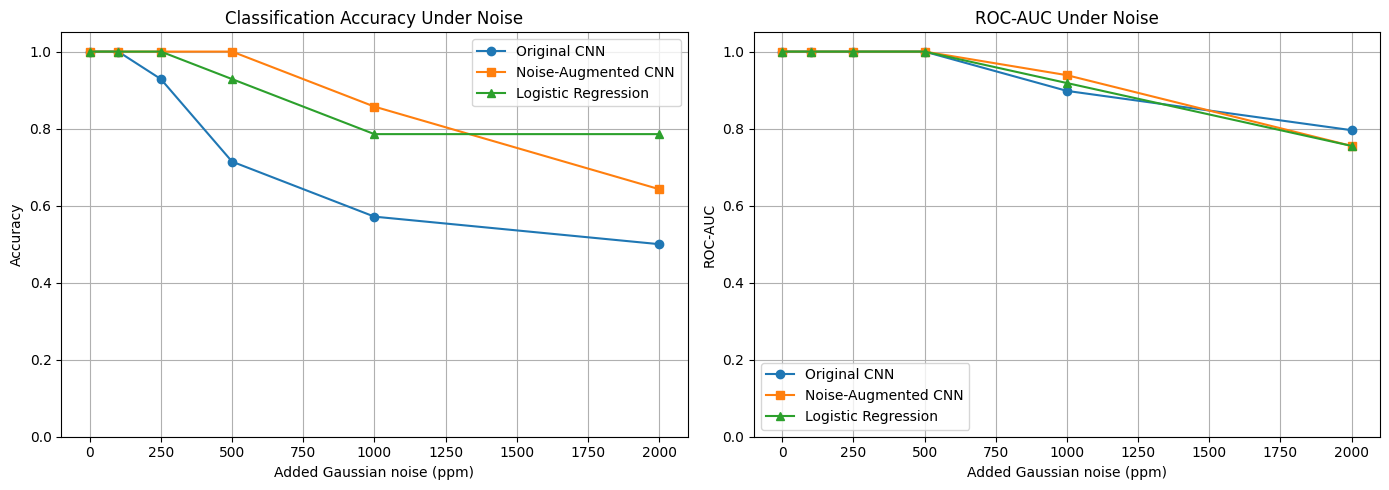

In [149]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

noise = comparison_df["Noise_ppm"]

# Accuracy
axes[0].plot(
    noise, comparison_df["Original_CNN_Accuracy"],
    marker="o", label="Original CNN"
)
axes[0].plot(
    noise, comparison_df["Augmented_CNN_Accuracy"],
    marker="s", label="Noise-Augmented CNN"
)
axes[0].plot(
    noise, comparison_df["LR_Accuracy"],
    marker="^", label="Logistic Regression"
)

axes[0].set_title("Classification Accuracy Under Noise")
axes[0].set_xlabel("Added Gaussian noise (ppm)")
axes[0].set_ylabel("Accuracy")
axes[0].set_ylim(0, 1.05)
axes[0].grid(True)
axes[0].legend()

# ROC-AUC
axes[1].plot(
    noise, comparison_df["Original_CNN_AUC"],
    marker="o", label="Original CNN"
)
axes[1].plot(
    noise, comparison_df["Augmented_CNN_AUC"],
    marker="s", label="Noise-Augmented CNN"
)
axes[1].plot(
    noise, comparison_df["LR_AUC"],
    marker="^", label="Logistic Regression"
)

axes[1].set_title("ROC-AUC Under Noise")
axes[1].set_xlabel("Added Gaussian noise (ppm)")
axes[1].set_ylabel("ROC-AUC")
axes[1].set_ylim(0, 1.05)
axes[1].grid(True)
axes[1].legend()

plt.tight_layout()
plt.show()

In [150]:
# save the validation comparison
validation_results = comparison_df.copy()

validation_results.to_csv(
    "validation_noise_robustness_results.csv",
    index=False
)

print("Validation results saved successfully.")
display(validation_results)

Validation results saved successfully.


,Noise_ppm,Original_CNN_Accuracy,Augmented_CNN_Accuracy,LR_Accuracy,Original_CNN_AUC,Augmented_CNN_AUC,LR_AUC
0,0,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
1,100,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
2,250,0.928571,1.000000,1.000000,1.000000,1.000000,1.000000
3,500,0.714286,1.000000,0.928571,1.000000,1.000000,1.000000
4,1000,0.571429,0.857143,0.785714,0.897959,0.938776,0.918367
5,2000,0.500000,0.642857,0.785714,0.795918,0.755102,0.755102


In [151]:
# Step 4.58 — Evaluate on the untouched test set
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report
)

# Prepare untouched test data
X_test_cnn = prepare_cnn_input(X_test)

# Obtain probability predictions
original_prob = original_cnn_model.predict(
    X_test_cnn, verbose=0
).ravel()

augmented_prob = augmented_cnn_model.predict(
    X_test_cnn, verbose=0
).ravel()

lr_prob = lr_model.predict_proba(X_test)[:, 1]

# Convert probabilities into binary predictions
original_pred = (original_prob >= 0.5).astype(int)
augmented_pred = (augmented_prob >= 0.5).astype(int)
lr_pred = (lr_prob >= 0.5).astype(int)

models_to_evaluate = {
    "Original CNN": (original_pred, original_prob),
    "Noise-Augmented CNN": (augmented_pred, augmented_prob),
    "Logistic Regression": (lr_pred, lr_prob)
}

test_results = []

for model_name, (predictions, probabilities) in models_to_evaluate.items():

    results = {
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "F1": f1_score(
            y_test, predictions, zero_division=0
        ),
        "ROC_AUC": roc_auc_score(y_test, probabilities),
        "PR_AUC": average_precision_score(y_test, probabilities)
    }

    test_results.append(results)

test_results_df = pd.DataFrame(test_results)

print("FINAL TEST-SET RESULTS")
display(test_results_df.round(4))

for model_name, (predictions, probabilities) in models_to_evaluate.items():

    print(f"\n{'='*50}")
    print(model_name)
    print("="*50)

    print("Confusion Matrix:")
    print(confusion_matrix(y_test, predictions))

    print("\nClassification Report:")
    print(classification_report(
        y_test,
        predictions,
        target_names=["Control", "Synthetic Transit"],
        zero_division=0
    ))

FINAL TEST-SET RESULTS


,Model,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC
0,Original CNN,0.9375,0.8889,1.0,0.9412,1.0,1.0
1,Noise-Augmented CNN,1.0000,1.0000,1.0,1.0000,1.0,1.0
2,Logistic Regression,1.0000,1.0000,1.0,1.0000,1.0,1.0



Original CNN
Confusion Matrix:
[[7 1]
 [0 8]]

Classification Report:
                   precision    recall  f1-score   support

          Control       1.00      0.88      0.93         8
Synthetic Transit       0.89      1.00      0.94         8

         accuracy                           0.94        16
        macro avg       0.94      0.94      0.94        16
     weighted avg       0.94      0.94      0.94        16


Noise-Augmented CNN
Confusion Matrix:
[[8 0]
 [0 8]]

Classification Report:
                   precision    recall  f1-score   support

          Control       1.00      1.00      1.00         8
Synthetic Transit       1.00      1.00      1.00         8

         accuracy                           1.00        16
        macro avg       1.00      1.00      1.00        16
     weighted avg       1.00      1.00      1.00        16


Logistic Regression
Confusion Matrix:
[[8 0]
 [0 8]]

Classification Report:
                   precision    recall  f1-score   support


In [155]:
reconstructed_curves = []
reconstructed_target_ids = []

for target_id in np.unique(group_ids):

    data = paired_injection_dataset[int(target_id)]

    for flux_key in ["control_flux", "injected_flux"]:

        reconstructed = create_perturbed_phase_curve(
            time=data["time"],
            flux=data[flux_key],
            period_days=data["period_days"],
            true_epoch=data["epoch_bkjd"],
            true_duration_hours=data["duration_hours"],
            alpha=1.0,
            beta=0.0,
            n_bins=24
        )

        reconstructed_curves.append(reconstructed)
        reconstructed_target_ids.append(target_id)

X_reconstructed = np.array(reconstructed_curves)

print("Original shape:", X_phase.shape)
print("Reconstructed shape:", X_reconstructed.shape)

if X_reconstructed.shape == X_phase.shape:
    print(
        "Maximum absolute difference:",
        np.nanmax(np.abs(X_phase - X_reconstructed))
    )

print("Missing values:", np.isnan(X_reconstructed).sum())
print("Unique targets:", len(np.unique(reconstructed_target_ids)))

Original shape: (100, 24)
Reconstructed shape: (100, 24)
Maximum absolute difference: 0.0020767967833095202
Missing values: 0
Unique targets: 50


In [156]:
# Step 4.59.3 — Inspect the original phase-folding code
print("Original phase-folding code variables:")
print("N_BINS:", N_BINS)
print("PHASE_MIN:", PHASE_MIN)
print("PHASE_MAX:", PHASE_MAX)

print("\nOriginal bin edges:")
print(bin_edges)

print("\nOriginal arrays:")
print("X_phase:", X_phase.shape)
print("group_ids:", group_ids.shape)
print("y_phase:", y_phase.shape)

print("\nFirst target ID:", np.unique(group_ids)[0])

print("\nStored injection metadata:")
display(
    injection_parameters_df.head()
)

Original phase-folding code variables:
N_BINS: 24
PHASE_MIN: -2.0
PHASE_MAX: 2.0

Original bin edges:
[-2.         -1.83333333 -1.66666667 -1.5        -1.33333333 -1.16666667
 -1.         -0.83333333 -0.66666667 -0.5        -0.33333333 -0.16666667
  0.          0.16666667  0.33333333  0.5         0.66666667  0.83333333
  1.          1.16666667  1.33333333  1.5         1.66666667  1.83333333
  2.        ]

Original arrays:
X_phase: (100, 24)
group_ids: (100,)
y_phase: (100,)

First target ID: 11853779

Stored injection metadata:


,Target_ID,Period_days,Duration_hours,Depth_ppm,Epoch_BKJD,Transit_Count,Baseline_days
0,11904151,5.095824,3.316635,2217.195840,363.814045,4,20.821508
1,11904148,2.376709,4.926867,2022.279404,363.488185,9,20.821508
2,11904099,2.512455,3.351158,1241.596048,363.880519,8,20.821508
3,11904085,4.575460,4.468285,1386.828398,361.560283,5,20.821509
4,11904071,4.218339,2.191452,2155.262344,363.363696,5,20.821509


In [157]:
reconstructed_curves = []
reconstructed_target_ids = []

for target_id in injection_parameters_df["Target_ID"].astype(int):

    data = paired_injection_dataset[int(target_id)]

    for flux_key in ["control_flux", "injected_flux"]:

        reconstructed = create_perturbed_phase_curve(
            time=data["time"],
            flux=data[flux_key],
            period_days=data["period_days"],
            true_epoch=data["epoch_bkjd"],
            true_duration_hours=data["duration_hours"],
            alpha=1.0,
            beta=0.0,
            n_bins=24
        )

        reconstructed_curves.append(reconstructed)
        reconstructed_target_ids.append(target_id)

X_reconstructed = np.array(reconstructed_curves)

print("Original shape:", X_phase.shape)
print("Reconstructed shape:", X_reconstructed.shape)

print(
    "Original first target IDs:",
    group_ids[:10]
)

print(
    "Reconstructed first target IDs:",
    reconstructed_target_ids[:10]
)

print(
    "Maximum absolute difference:",
    np.nanmax(np.abs(X_phase - X_reconstructed))
)

print("Missing values:", np.isnan(X_reconstructed).sum())

Original shape: (100, 24)
Reconstructed shape: (100, 24)
Original first target IDs: [11904151 11904151 11904148 11904148 11904099 11904099 11904085 11904085
 11904071 11904071]
Reconstructed first target IDs: [11904151, 11904151, 11904148, 11904148, 11904099, 11904099, 11904085, 11904085, 11904071, 11904071]
Maximum absolute difference: 0.0
Missing values: 0


In [159]:
def create_perturbed_phase_curve(
    time,
    flux,
    period_days,
    true_epoch,
    true_duration_hours,
    alpha=1.0,
    beta=0.0,
    n_bins=24
):
    true_duration_days = true_duration_hours / 24.0

    estimated_duration_days = alpha * true_duration_days
    estimated_epoch = true_epoch + beta * true_duration_days

    phase_days = (
        (time - estimated_epoch + period_days / 2)
        % period_days
    ) - period_days / 2

    scaled_phase = phase_days / estimated_duration_days

    in_window = (
        (scaled_phase >= -2.0) &
        (scaled_phase <= 2.0)
    )

    phase_values = scaled_phase[in_window]
    flux_values = flux[in_window]

    bin_edges = np.linspace(-2.0, 2.0, n_bins + 1)
    bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2

    binned_flux = np.full(n_bins, np.nan)

    bin_indices = np.digitize(
        phase_values,
        bin_edges
    ) - 1

    for i in range(n_bins):
        mask = bin_indices == i

        if np.any(mask):
            binned_flux[i] = np.median(flux_values[mask])

    valid_bins = np.isfinite(binned_flux)

    if valid_bins.sum() == 0:
        return binned_flux

    if valid_bins.sum() < n_bins:
        binned_flux[~valid_bins] = np.interp(
            bin_centers[~valid_bins],
            bin_centers[valid_bins],
            binned_flux[valid_bins]
        )

    return binned_flux

In [160]:
# Rerun the duration experiment correctly
duration_error_results = []

duration_factors = [0.5, 0.75, 1.0, 1.25, 1.5, 2.0]

for alpha in duration_factors:

    perturbed_curves = []

    for target_id in injection_parameters_df["Target_ID"].astype(int):

        data = paired_injection_dataset[target_id]

        for flux_key in ["control_flux", "injected_flux"]:

            curve = create_perturbed_phase_curve(
                time=data["time"],
                flux=data[flux_key],
                period_days=data["period_days"],
                true_epoch=data["epoch_bkjd"],
                true_duration_hours=data["duration_hours"],
                alpha=alpha,
                beta=0.0,
                n_bins=24
            )

            perturbed_curves.append(curve)

    X_perturbed_full = np.asarray(perturbed_curves)

    # Select precisely the original test samples
    X_perturbed_test = X_perturbed_full[test_idx]

    assert X_perturbed_test.shape == X_test.shape
    assert X_perturbed_test.shape[0] == len(y_test)
    assert np.isfinite(X_perturbed_test).all()

    X_perturbed_test_cnn = prepare_cnn_input(
        X_perturbed_test
    )

    probabilities = {
        "Original CNN": original_cnn_model.predict(
            X_perturbed_test_cnn, verbose=0
        ).ravel(),

        "Noise-Augmented CNN": augmented_cnn_model.predict(
            X_perturbed_test_cnn, verbose=0
        ).ravel(),

        "Logistic Regression": lr_model.predict_proba(
            X_perturbed_test
        )[:, 1]
    }

    for model_name, probs in probabilities.items():

        predictions = (probs >= 0.5).astype(int)

        duration_error_results.append({
            "Alpha": alpha,
            "Model": model_name,
            "Accuracy": accuracy_score(y_test, predictions),
            "ROC_AUC": roc_auc_score(y_test, probs)
        })

duration_error_df = pd.DataFrame(duration_error_results)

display(
    duration_error_df.round(4)
)

,Alpha,Model,Accuracy,ROC_AUC
0,0.50,Original CNN,0.8750,1.0
1,0.50,Noise-Augmented CNN,1.0000,1.0
2,0.50,Logistic Regression,1.0000,1.0
3,0.75,Original CNN,0.9375,1.0
4,0.75,Noise-Augmented CNN,1.0000,1.0
5,0.75,Logistic Regression,1.0000,1.0
6,1.00,Original CNN,0.9375,1.0
7,1.00,Noise-Augmented CNN,1.0000,1.0
8,1.00,Logistic Regression,1.0000,1.0
9,1.25,Original CNN,0.9375,1.0


In [161]:
center_error_results = []

center_offsets = [
    -1.0, -0.75, -0.5, -0.25,
     0.0,  0.25,  0.5,  0.75, 1.0
]

for beta in center_offsets:

    perturbed_curves = []

    for target_id in injection_parameters_df["Target_ID"].astype(int):

        data = paired_injection_dataset[target_id]

        for flux_key in ["control_flux", "injected_flux"]:

            curve = create_perturbed_phase_curve(
                time=data["time"],
                flux=data[flux_key],
                period_days=data["period_days"],
                true_epoch=data["epoch_bkjd"],
                true_duration_hours=data["duration_hours"],
                alpha=1.0,
                beta=beta,
                n_bins=24
            )

            perturbed_curves.append(curve)

    X_perturbed_full = np.asarray(perturbed_curves)

    # Select the same eight test targets and their paired samples
    X_perturbed_test = X_perturbed_full[test_idx]

    assert X_perturbed_test.shape == X_test.shape
    assert np.isfinite(X_perturbed_test).all()

    X_perturbed_test_cnn = prepare_cnn_input(
        X_perturbed_test
    )

    probabilities = {
        "Original CNN": original_cnn_model.predict(
            X_perturbed_test_cnn, verbose=0
        ).ravel(),

        "Noise-Augmented CNN": augmented_cnn_model.predict(
            X_perturbed_test_cnn, verbose=0
        ).ravel(),

        "Logistic Regression": lr_model.predict_proba(
            X_perturbed_test
        )[:, 1]
    }

    for model_name, probs in probabilities.items():

        predictions = (probs >= 0.5).astype(int)

        center_error_results.append({
            "Beta": beta,
            "Model": model_name,
            "Accuracy": accuracy_score(y_test, predictions),
            "ROC_AUC": roc_auc_score(y_test, probs)
        })

center_error_df = pd.DataFrame(center_error_results)

display(center_error_df.round(4))

,Beta,Model,Accuracy,ROC_AUC
0,-1.00,Original CNN,1.0000,1.0000
1,-1.00,Noise-Augmented CNN,1.0000,1.0000
2,-1.00,Logistic Regression,0.5000,0.3281
3,-0.75,Original CNN,0.9375,1.0000
4,-0.75,Noise-Augmented CNN,1.0000,1.0000
5,-0.75,Logistic Regression,0.5000,0.7031
6,-0.50,Original CNN,0.9375,1.0000
7,-0.50,Noise-Augmented CNN,1.0000,1.0000
8,-0.50,Logistic Regression,0.7500,1.0000
9,-0.25,Original CNN,0.9375,1.0000


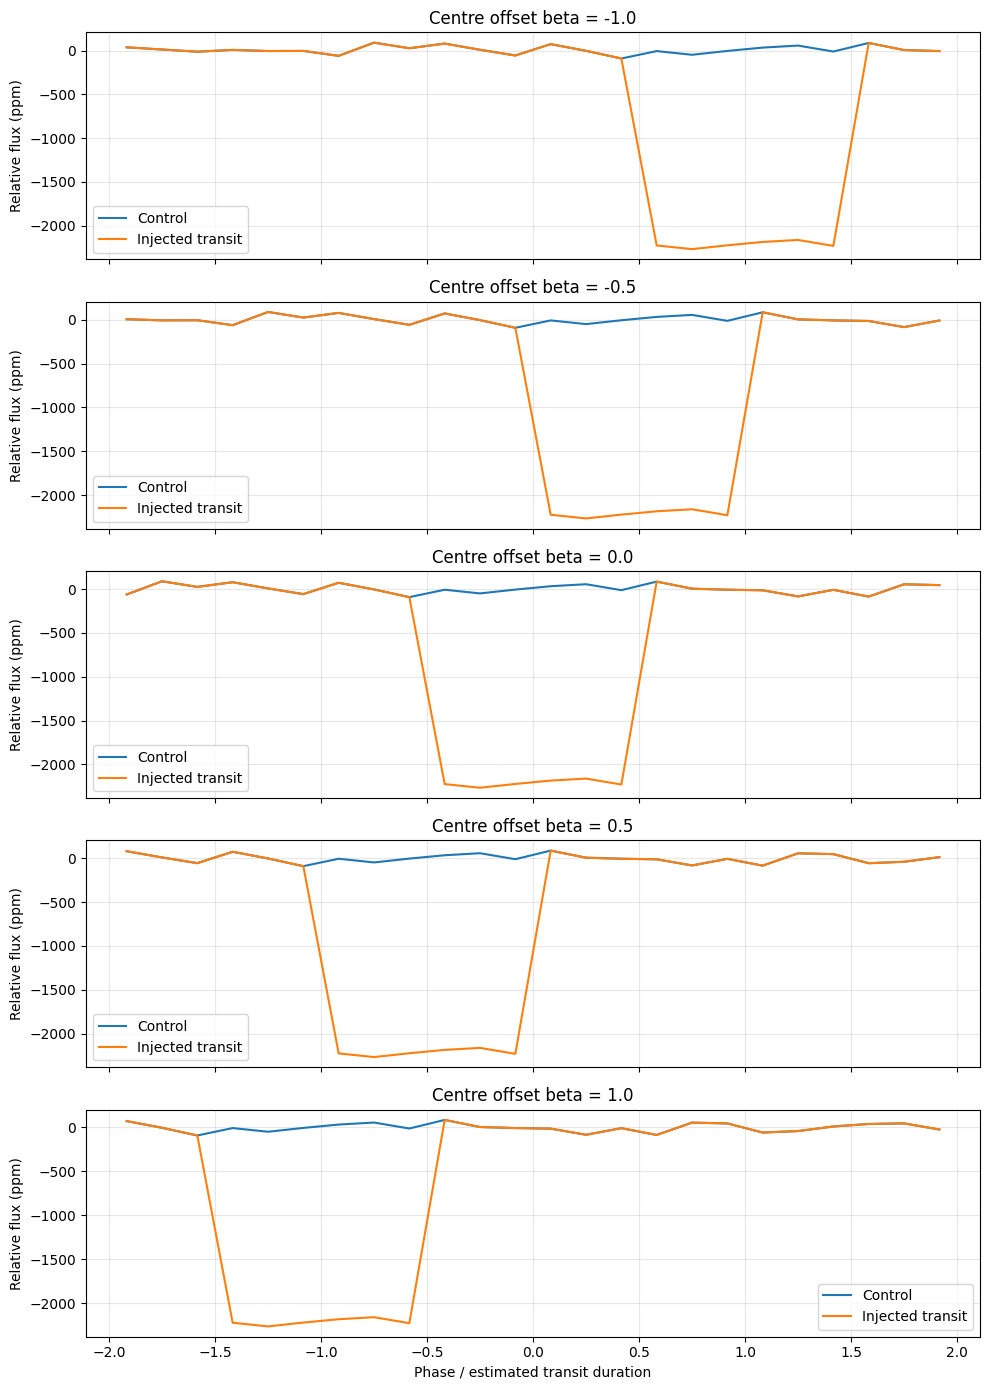

In [162]:
# Step 4.62 — Verify what the models are actually seeing

target_id = int(injection_parameters_df["Target_ID"].iloc[0])
data = paired_injection_dataset[target_id]

beta_values = [-1.0, -0.5, 0.0, 0.5, 1.0]

fig, axes = plt.subplots(
    len(beta_values), 1,
    figsize=(10, 14),
    sharex=True
)

for ax, beta in zip(axes, beta_values):

    control_curve = create_perturbed_phase_curve(
        time=data["time"],
        flux=data["control_flux"],
        period_days=data["period_days"],
        true_epoch=data["epoch_bkjd"],
        true_duration_hours=data["duration_hours"],
        alpha=1.0,
        beta=beta
    )

    injected_curve = create_perturbed_phase_curve(
        time=data["time"],
        flux=data["injected_flux"],
        period_days=data["period_days"],
        true_epoch=data["epoch_bkjd"],
        true_duration_hours=data["duration_hours"],
        alpha=1.0,
        beta=beta
    )

    phase_bins = np.linspace(-2, 2, 24, endpoint=False)
    phase_bins += (4 / 24) / 2

    ax.plot(
        phase_bins,
        (control_curve - 1) * 1e6,
        label="Control"
    )

    ax.plot(
        phase_bins,
        (injected_curve - 1) * 1e6,
        label="Injected transit"
    )

    ax.set_title(f"Centre offset beta = {beta}")
    ax.set_ylabel("Relative flux (ppm)")
    ax.grid(True, alpha=0.3)
    ax.legend()

axes[-1].set_xlabel("Phase / estimated transit duration")

plt.tight_layout()
plt.show()

In [163]:
# Step 4.63 — Combined duration and centre errors
combined_error_results = []

alpha_values = [0.75, 1.0, 1.25, 1.5]
beta_values = [-0.5, 0.0, 0.5]

for alpha in alpha_values:

    for beta in beta_values:

        perturbed_curves = []

        for target_id in injection_parameters_df["Target_ID"].astype(int):

            data = paired_injection_dataset[target_id]

            for flux_key in ["control_flux", "injected_flux"]:

                curve = create_perturbed_phase_curve(
                    time=data["time"],
                    flux=data[flux_key],
                    period_days=data["period_days"],
                    true_epoch=data["epoch_bkjd"],
                    true_duration_hours=data["duration_hours"],
                    alpha=alpha,
                    beta=beta,
                    n_bins=24
                )

                perturbed_curves.append(curve)

        X_combined_full = np.asarray(perturbed_curves)

        # Use the same test samples
        X_combined_test = X_combined_full[test_idx]

        assert X_combined_test.shape == X_test.shape
        assert np.isfinite(X_combined_test).all()

        X_combined_cnn = prepare_cnn_input(X_combined_test)

        probabilities = {
            "Original CNN": original_cnn_model.predict(
                X_combined_cnn, verbose=0
            ).ravel(),

            "Noise-Augmented CNN": augmented_cnn_model.predict(
                X_combined_cnn, verbose=0
            ).ravel(),

            "Logistic Regression": lr_model.predict_proba(
                X_combined_test
            )[:, 1]
        }

        for model_name, probs in probabilities.items():

            predictions = (probs >= 0.5).astype(int)

            combined_error_results.append({
                "Alpha": alpha,
                "Beta": beta,
                "Model": model_name,
                "Accuracy": accuracy_score(y_test, predictions),
                "ROC_AUC": roc_auc_score(y_test, probs)
            })

combined_error_df = pd.DataFrame(combined_error_results)

display(
    combined_error_df.round(4)
)

,Alpha,Beta,Model,Accuracy,ROC_AUC
0,0.75,-0.5,Original CNN,0.9375,1.0
1,0.75,-0.5,Noise-Augmented CNN,1.0000,1.0
2,0.75,-0.5,Logistic Regression,0.8750,1.0
3,0.75,0.0,Original CNN,0.9375,1.0
4,0.75,0.0,Noise-Augmented CNN,1.0000,1.0
5,0.75,0.0,Logistic Regression,1.0000,1.0
6,0.75,0.5,Original CNN,0.9375,1.0
7,0.75,0.5,Noise-Augmented CNN,1.0000,1.0
8,0.75,0.5,Logistic Regression,0.9375,1.0
9,1.00,-0.5,Original CNN,0.9375,1.0


In [164]:
# Step 4.64 — Save the robustness experiment results
# Save individual experiment results
validation_results.to_csv(
    "validation_noise_robustness_results.csv",
    index=False
)

test_results_df.to_csv(
    "final_test_results.csv",
    index=False
)

duration_error_df.to_csv(
    "duration_error_results.csv",
    index=False
)

center_error_df.to_csv(
    "center_error_results.csv",
    index=False
)

combined_error_df.to_csv(
    "combined_error_results.csv",
    index=False
)

print("All experiment result files saved.")

print("\nSaved files:")
for filename in [
    "validation_noise_robustness_results.csv",
    "final_test_results.csv",
    "duration_error_results.csv",
    "center_error_results.csv",
    "combined_error_results.csv"
]:
    print(filename)

All experiment result files saved.

Saved files:
validation_noise_robustness_results.csv
final_test_results.csv
duration_error_results.csv
center_error_results.csv
combined_error_results.csv


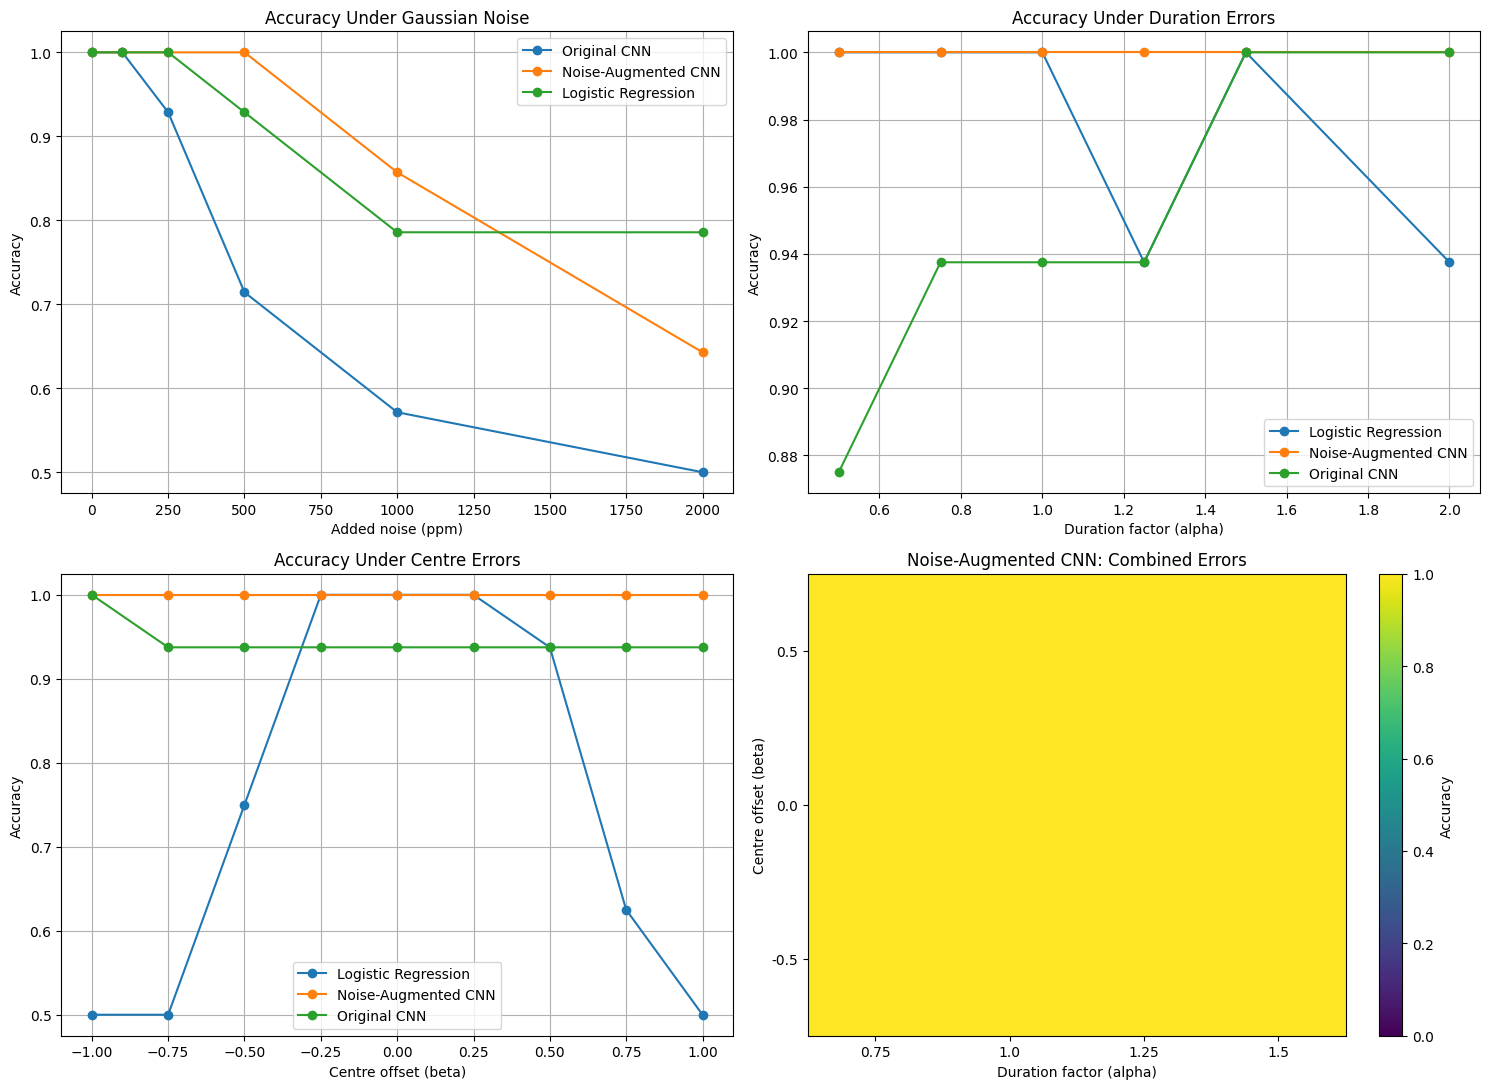

Research figures saved successfully.


In [165]:
#  Step 4.65 — Generate research figures
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 2, figsize=(15, 11))

# 1. Noise robustness
for model in comparison_df.columns:
    pass

noise_models = {
    "Original CNN": "Original_CNN_Accuracy",
    "Noise-Augmented CNN": "Augmented_CNN_Accuracy",
    "Logistic Regression": "LR_Accuracy"
}

for name, column in noise_models.items():
    axes[0, 0].plot(
        comparison_df["Noise_ppm"],
        comparison_df[column],
        marker="o",
        label=name
    )

axes[0, 0].set_title("Accuracy Under Gaussian Noise")
axes[0, 0].set_xlabel("Added noise (ppm)")
axes[0, 0].set_ylabel("Accuracy")
axes[0, 0].legend()
axes[0, 0].grid(True)


# 2. Duration errors
for model_name, group in duration_error_df.groupby("Model"):
    axes[0, 1].plot(
        group["Alpha"],
        group["Accuracy"],
        marker="o",
        label=model_name
    )

axes[0, 1].set_title("Accuracy Under Duration Errors")
axes[0, 1].set_xlabel("Duration factor (alpha)")
axes[0, 1].set_ylabel("Accuracy")
axes[0, 1].legend()
axes[0, 1].grid(True)


# 3. Centre errors
for model_name, group in center_error_df.groupby("Model"):
    axes[1, 0].plot(
        group["Beta"],
        group["Accuracy"],
        marker="o",
        label=model_name
    )

axes[1, 0].set_title("Accuracy Under Centre Errors")
axes[1, 0].set_xlabel("Centre offset (beta)")
axes[1, 0].set_ylabel("Accuracy")
axes[1, 0].legend()
axes[1, 0].grid(True)


# 4. Combined errors: noise-augmented CNN
combined_cnn = combined_error_df[
    combined_error_df["Model"] == "Noise-Augmented CNN"
]

combined_pivot = combined_cnn.pivot(
    index="Beta",
    columns="Alpha",
    values="Accuracy"
)

im = axes[1, 1].imshow(
    combined_pivot.values,
    aspect="auto",
    origin="lower",
    vmin=0,
    vmax=1
)

axes[1, 1].set_title("Noise-Augmented CNN: Combined Errors")
axes[1, 1].set_xlabel("Duration factor (alpha)")
axes[1, 1].set_ylabel("Centre offset (beta)")
axes[1, 1].set_xticks(range(len(combined_pivot.columns)))
axes[1, 1].set_xticklabels(combined_pivot.columns)
axes[1, 1].set_yticks(range(len(combined_pivot.index)))
axes[1, 1].set_yticklabels(combined_pivot.index)

fig.colorbar(im, ax=axes[1, 1], label="Accuracy")

plt.tight_layout()

plt.savefig(
    "research_robustness_figures.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Research figures saved successfully.")